# Thermal-runaway physics + surrogate for an HTS magnet

This notebook reproduces the analytic results of **Marchevsky & Prestemon, *Supercond. Sci. Technol.* **37** 035012 (2024)** and then builds a *surrogate model* trained on the analytic solver output. The point of the surrogate is to **replace the iterative root-finding step in a real-time protection loop** with a single fast lookup.

The path through the notebook:

1. **Physics setup** — constants, brass thermal conductivity, conductor transport model, the heat-balance runaway solver.
2. **Paper reproduction** — Fig. 2 (no stabilizer), Fig. 3 (stabilized), Fig. 4 (time margin), Fig. 5 (power dissipation at runaway). All as 3D surfaces, matching the published figure style.
3. **Experimental validation** — Fig. 7 reproduction with a single n calibrated against the U(243 A) anchor (no quartic n(T) tuning).
4. **Surrogate model** — train a gradient-boosted regressor on `(T0, I, U, T_surface) -> margin = (I*-I)/I*`. These are the four live instruments the paper actually uses; no offline calibrations enter as features (n, Ic0 are fixed for one conductor).
5. **Surrogate validation** — on held-out ramp traces, on a Fig. 7-style ramp, on three different bath temperatures. The surrogate's job is to reproduce the analytic margin and the runaway crossing using only the live signal.
6. **What the surrogate replaces** — the brentq root-finding in `solve_runaway`. We show inference time vs. solver time and the practical role: live protection decisions at instrument-loop rate.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score, accuracy_score

np.random.seed(7)


## Constants and geometry (paper sections 2b, 2c)

In [2]:
# Paper: Ic0 = 500 A, Tc = 85 K, L = 1 m, w = 4 mm, d = 1 cm
U0  = 1e-4 / 1.0      # V per meter * L  (E0 = 1e-4 V/m criterion)
Ic0 = 500.0
Tc  = 85.0

L   = 1.0
w   = 0.004
d   = 0.01

# Stabilized layer stack (paper sec 2c)
t_sc = 1.3e-6
t_cu = 50e-6
t_ss = 50e-6
A_cu = t_cu * w
A_ss = t_ss * w

# Stabilizer resistivities
RRR_CU      = 24.0
rho_cu_300  = 1.6e-8
rho_ss_300  = 7.0e-7

# Volumetric heat capacities for Fig. 4 time-margin integration
rho_mass_cu = 8960.0
rho_mass_ss = 8000.0

T_SAFE = 300.0  # final safe T for the quench-integral bound (paper Fig. 4)


## Brass thermal conductivity (corrected NIST C26000 polynomial)

Paper eq. (6) lists `g = -0.174057`, which makes the polynomial collapse above 25 K. NIST trc.nist.gov for brass UNS C26000 lists `g = +0.174057`. With the correct sign the polynomial matches NIST tabulated values to ~1.5% over 5-110 K.

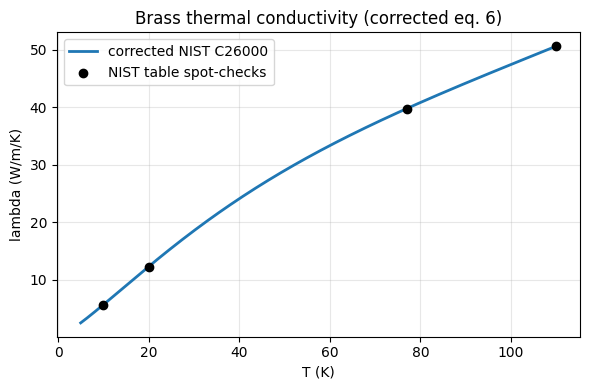

In [3]:
# NIST C26000 brass coefficients (sign on g corrected vs paper eq. 6)
_BRASS_COEF = dict(a=0.021035, b=-1.01835, c=4.54083, d=-5.03374,
                   e=3.20536,  f=-1.12933, g=+0.174057, h=-0.0038151)
_BRASS_TMIN, _BRASS_TMAX = 5.0, 110.0

def lambda_brass(T):
    T = np.asarray(T, dtype=float)
    Tc_ = np.clip(T, _BRASS_TMIN, _BRASS_TMAX)
    x = np.log10(Tc_)
    c = _BRASS_COEF
    p = (c['a'] + c['b']*x + c['c']*x**2 + c['d']*x**3
         + c['e']*x**4 + c['f']*x**5 + c['g']*x**6 + c['h']*x**7)
    return 10**p

Ts = np.linspace(5, 110, 300)
plt.figure(figsize=(6, 4))
plt.plot(Ts, lambda_brass(Ts), lw=2, label='corrected NIST C26000')
for T_chk, lam_chk in [(10, 5.7), (20, 12.3), (77, 39.8), (110, 50.6)]:
    plt.scatter([T_chk], [lam_chk], color='k', zorder=5)
plt.scatter([], [], color='k', label='NIST table spot-checks')
plt.xlabel('T (K)'); plt.ylabel('lambda (W/m/K)')
plt.title('Brass thermal conductivity (corrected eq. 6)')
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()


## Conductor electrical and transport model (paper eqs. 2, 4, 5, 7, 8)

In [4]:
# Ic(T) from paper eq. (5)
def Ic(T):
    T = np.asarray(T, dtype=float)
    T_clip = np.clip(T, 1.0, Tc - 1e-6)
    return np.maximum(Ic0 * (1.0 - (T_clip/Tc)**1.7), 1e-12)

# Heat to environment: Qout(T) = eta(T) * (T - T0)
def eta(T, lam_override=None):
    lam = lambda_brass(T) if lam_override is None else float(lam_override)
    return lam * (2.0 * w * L / d)

def Qout(T, T0, lam_override=None):
    T = np.asarray(T, dtype=float)
    Tcl = np.maximum(T, T0 + 1e-9)
    return eta(Tcl, lam_override=lam_override) * (Tcl - T0)

# Normal-stabilizer resistances (per unit length)
def rho_cu(T):
    T = np.asarray(T, dtype=float)
    rho0 = rho_cu_300/RRR_CU
    phonon = (rho_cu_300 - rho0) * np.clip(T/300.0, 0, 1.5)**1.7
    return rho0 + phonon

def rho_ss(T):
    T = np.asarray(T, dtype=float)
    return rho_ss_300 * (0.85 + 0.15*np.clip(T/300.0, 0, 1.5))

def R_cu(T): return rho_cu(T) * L / A_cu
def R_ss(T): return rho_ss(T) * L / A_ss
def R_stab(T): return 1.0/(1.0/R_cu(T) + 1.0/R_ss(T))

# Current sharing: paper eq. (8)
def solve_Ix(I, T, n):
    if I <= 0:
        return 0.0
    Rst = float(R_stab(T))
    IcT = float(Ic(T))
    def f(ix):
        return U0 * (ix/IcT)**n - (I - ix) * Rst
    try:
        return brentq(f, 0.0, I, maxiter=100)
    except ValueError:
        return I if f(I) < 0 else 0.0

def voltage_stab(I, T, n):
    Ix = solve_Ix(float(I), float(min(T, Tc-1e-6)), float(n))
    return U0 * (Ix/Ic(T))**n

def Qin_stab(I, T, n):
    return I * voltage_stab(I, T, n)

# No-stabilizer case for Fig. 2
def voltage_no_stab(I, T, n):
    return U0 * (I/Ic(T))**n

def Qin_no_stab(I, T, n):
    return I * voltage_no_stab(I, T, n)


## Runaway solver - corrected

Solves Qin(I,T) = Qout(T) for equilibrium I(T) at every T in (T0, Tc), then locates the maximum. The previous version used `argmax` as a fallback when no interior maximum existed, producing spurious values pinned to T = Tc-eps at high T0. We now return NaN in that case.

In [5]:
def _equilibrium_current_at_T(T, T0, n, mode='stab', lam_override=None):
    cooling = float(Qout(T, T0, lam_override=lam_override))
    Qin_fn = Qin_stab if mode == 'stab' else Qin_no_stab
    def bal(I): return Qin_fn(I, T, n) - cooling
    hi = max(4.0*float(Ic(T0)), 100.0)
    for _ in range(40):
        if bal(hi) > 0:
            break
        hi *= 1.5
    else:
        return np.nan
    try:
        return brentq(bal, 0.0, hi, maxiter=120)
    except Exception:
        return np.nan

def solve_runaway(T0, n, mode='stab', lam_override=None, n_branch=300,
                  require_interior_max=True):
    """Return (Istar, Tstar). If no interior maximum exists, return (nan, nan)."""
    Ts = np.linspace(T0 + 1e-4, Tc - 1e-4, n_branch)
    Is = np.array([_equilibrium_current_at_T(T, T0, n, mode=mode, lam_override=lam_override)
                   for T in Ts])
    Is = np.nan_to_num(Is, nan=0.0, posinf=0.0, neginf=0.0)
    if not np.any(Is > 0):
        return np.nan, np.nan
    dI = np.gradient(Is, Ts)
    sign_changes = np.where((dI[:-1] > 0) & (dI[1:] <= 0))[0]
    if len(sign_changes) == 0:
        if require_interior_max:
            return np.nan, np.nan
        idx = int(np.argmax(Is))
    else:
        idx = int(sign_changes[0]) + 1
    return float(Is[idx]), float(Ts[idx])

def stable_surface_T(I, T0, n, mode='stab', lam_override=None):
    Qin_fn = Qin_stab if mode == 'stab' else Qin_no_stab
    def F(T): return Qin_fn(I, T, n) - Qout(T, T0, lam_override=lam_override)
    Ts = np.linspace(T0 + 1e-4, Tc - 1e-4, 300)
    vals = np.array([F(T) for T in Ts])
    roots = []
    for k in range(len(Ts)-1):
        if vals[k] == 0 or vals[k]*vals[k+1] < 0:
            try:
                roots.append(brentq(F, Ts[k], Ts[k+1], maxiter=80))
            except Exception:
                pass
    return min(roots) if roots else np.nan


## Fig. 2 - no-stabilizer surfaces

Paper Fig. 2 left: I*/Ic(T0) and dT = T*-T0 vs (T0, lambda) with lambda constant and n=20. Right: same vs (T0, n) with temperature-dependent lambda(T).

In [6]:
# Fig. 2a/b: vary (T0, lambda_const), n=20, no stabilizer
T0_grid_2a  = np.linspace(5.0, 80.0, 10)
lam_grid_2a = np.linspace(48.0, 200.0, 8)

Istar_2a = np.full((len(lam_grid_2a), len(T0_grid_2a)), np.nan)
dT_2a    = np.full_like(Istar_2a, np.nan)

for i, lam in enumerate(lam_grid_2a):
    for j, T0 in enumerate(T0_grid_2a):
        Istar, Tstar = solve_runaway(T0, n=20.0, mode='no_stab', lam_override=lam)
        if np.isfinite(Istar):
            Istar_2a[i, j] = Istar / float(Ic(T0))
            dT_2a[i, j]    = Tstar - T0

# Fig. 2c/d: vary (T0, n), lambda(T), no stabilizer
T0_grid_2c = np.linspace(5.0, 80.0, 10)
n_grid_2c  = np.linspace(10.0, 30.0, 8)

Istar_2c = np.full((len(n_grid_2c), len(T0_grid_2c)), np.nan)
dT_2c    = np.full_like(Istar_2c, np.nan)

for i, n in enumerate(n_grid_2c):
    for j, T0 in enumerate(T0_grid_2c):
        Istar, Tstar = solve_runaway(T0, n=float(n), mode='no_stab')
        if np.isfinite(Istar):
            Istar_2c[i, j] = Istar / float(Ic(T0))
            dT_2c[i, j]    = Tstar - T0

print('Fig. 2 grids: I*/Ic and dT computed; ready for 3D plot below')

Fig. 2 grids: I*/Ic and dT computed; ready for 3D plot below


In [7]:
# ============================================================
# PAPER-LIKE 3D SURFACE WITH TRUE AXIS LABELS
# ============================================================

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
import numpy as np
import matplotlib.pyplot as plt

def plot_fig2_surface(
    X, Y, Z,
    title,
    xlabel,
    ylabel,
    zlabel,
    cmap="turbo",
    elev=27,
    azim=-128,
    reverse_x=False,
    reverse_y=False,
    xlim=None,
    ylim=None,
    zlim=None,
    xticks=None,
    yticks=None,
    zticks=None,
    savepath=None
):

    # ========================================================
    # FIGURE
    # ========================================================

    fig = plt.figure(figsize=(8.8, 6.4))

    ax = fig.add_subplot(
        111,
        projection="3d"
    )

    # ========================================================
    # SURFACE
    # ========================================================

    surf = ax.plot_surface(
        X,
        Y,
        Z,
        cmap=cmap,
        edgecolor="k",
        linewidth=0.22,
        antialiased=True,
        alpha=0.98
    )

    # ========================================================
    # CAMERA ANGLE
    # ========================================================

    ax.view_init(
        elev=elev,
        azim=azim
    )

    # ========================================================
    # LIMITS
    # ========================================================

    if xlim is None:
        xlim = (
            np.nanmin(X),
            np.nanmax(X)
        )

    if ylim is None:
        ylim = (
            np.nanmin(Y),
            np.nanmax(Y)
        )

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

    if zlim is not None:
        ax.set_zlim(*zlim)

    # ========================================================
    # AXIS REVERSALS
    # ========================================================

    if reverse_x:
        ax.invert_xaxis()

    if reverse_y:
        ax.invert_yaxis()

    # ========================================================
    # TICKS
    # ========================================================

    if xticks is not None:
        ax.set_xticks(xticks)

    if yticks is not None:
        ax.set_yticks(yticks)

    if zticks is not None:
        ax.set_zticks(zticks)

    ax.tick_params(
        axis="x",
        pad=2,
        labelsize=10
    )

    ax.tick_params(
        axis="y",
        pad=2,
        labelsize=10
    )

    ax.tick_params(
        axis="z",
        pad=5,
        labelsize=10
    )

    # ========================================================
    # TRUE 3D AXIS LABELS
    # ========================================================

    ax.set_xlabel(
        xlabel,
        labelpad=16,
        fontsize=12
    )

    ax.set_ylabel(
        ylabel,
        labelpad=18,
        fontsize=12
    )

    # ========================================================
    # GUARANTEED VISIBLE Z-LABEL OVERLAY
    # ========================================================

    ax.text2D(
        -0.10, 0.55,
        zlabel,
        transform=ax.transAxes,
        rotation=90,
        ha="center",
        va="center",
        fontsize=12,
        clip_on=False
    )

    # ========================================================
    # TITLE
    # ========================================================

    ax.set_title(
        title,
        pad=18,
        fontsize=14
    )

    # ========================================================
    # BOX ASPECT
    # ========================================================

    try:
        ax.set_box_aspect(
            (
                1.35,
                1.0,
                0.65
            )
        )

    except Exception:
        pass

    # ========================================================
    # CLEAN PANES
    # ========================================================

    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False

    ax.grid(
        True,
        alpha=0.35
    )

    # ========================================================
    # COLORBAR
    # ========================================================

    cbar = fig.colorbar(
        surf,
        ax=ax,
        shrink=0.70,
        pad=0.08
    )

    cbar.ax.tick_params(
        labelsize=9
    )

    # ========================================================
    # LAYOUT
    # ========================================================

    fig.subplots_adjust(
        left=0.02,
        right=0.90,
        bottom=0.05,
        top=0.92
    )

    # ========================================================
    # SAVE
    # ========================================================

    if savepath is not None:

        plt.savefig(
            savepath,
            dpi=250,
            bbox_inches="tight",
            pad_inches=0.25
        )

    # ========================================================
    # SHOW
    # ========================================================

    
    

    plt.show()

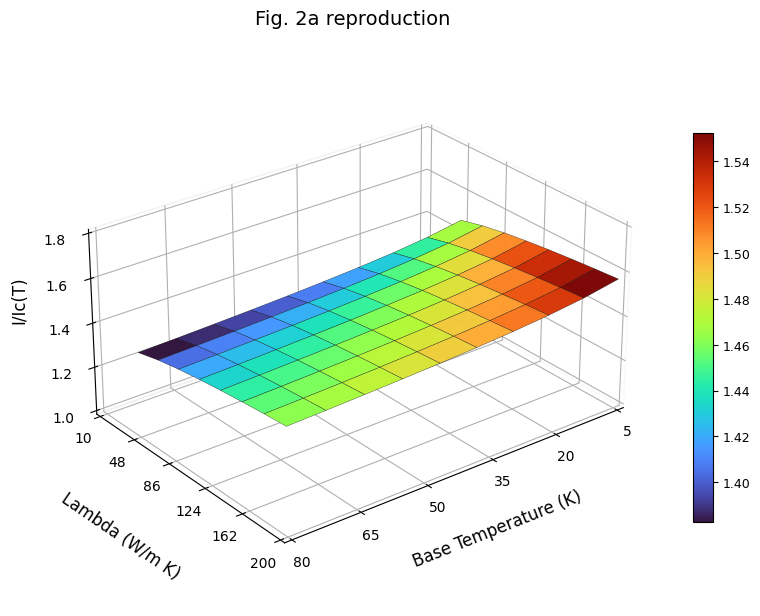

In [10]:
# ============================================================
# FIGURE 2a
# I*/Ic(T0) vs (T0, lambda)
# ============================================================

TT_a, LL_a = np.meshgrid(
    T0_grid_2a,
    lam_grid_2a
)

plot_fig2_surface(
    TT_a,
    LL_a,
    Istar_2a,

    title="Fig. 2a reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="I/Ic(T)",

    elev=27,
    azim=-128,

    reverse_y=True,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(48, 200),
    zlim=(1.0, 1.8),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[10,48, 86, 124, 162, 200],
    zticks=[1.0, 1.2, 1.4, 1.6, 1.8],

    savepath="fig2a.png"
)

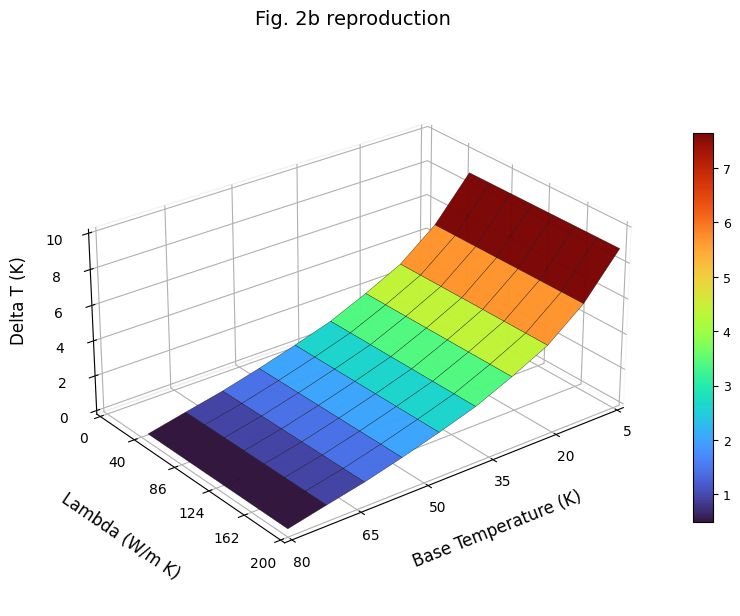

In [11]:
# ============================================================
# FIGURE 2b
# DeltaT vs (T0, lambda)
# ============================================================

plot_fig2_surface(
    TT_a,
    LL_a,
    dT_2a,

    title="Fig. 2b reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="Delta T (K)",

    elev=27,
    azim=-128,

    reverse_y=True,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(48, 200),
    zlim=(0, 10),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[0, 40, 86, 124, 162, 200],
    zticks=[0, 2, 4, 6, 8, 10]
)

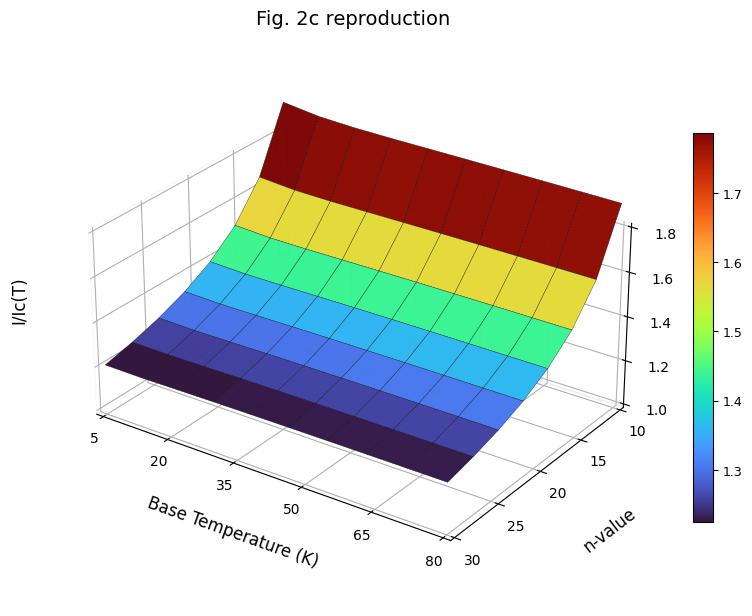

In [12]:
# ============================================================
# FIGURE 2c
# I*/Ic(T0) vs (T0, n)
# ============================================================

TT_c, NN_c = np.meshgrid(
    T0_grid_2c,
    n_grid_2c
)

plot_fig2_surface(
    TT_c,
    NN_c,
    Istar_2c,

    title="Fig. 2c reproduction",

    xlabel="Base Temperature (K)",
    ylabel="n-value",
    zlabel="I/Ic(T)",

    elev=27,
    azim=-55,

    reverse_y=True,

    xlim=(5, 80),
    ylim=(10, 30),
    zlim=(1.0, 1.8),
    
    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[10, 15, 20, 25, 30],
    zticks=[1.0, 1.2, 1.4, 1.6, 1.8],

    savepath="fig2c.png"
)

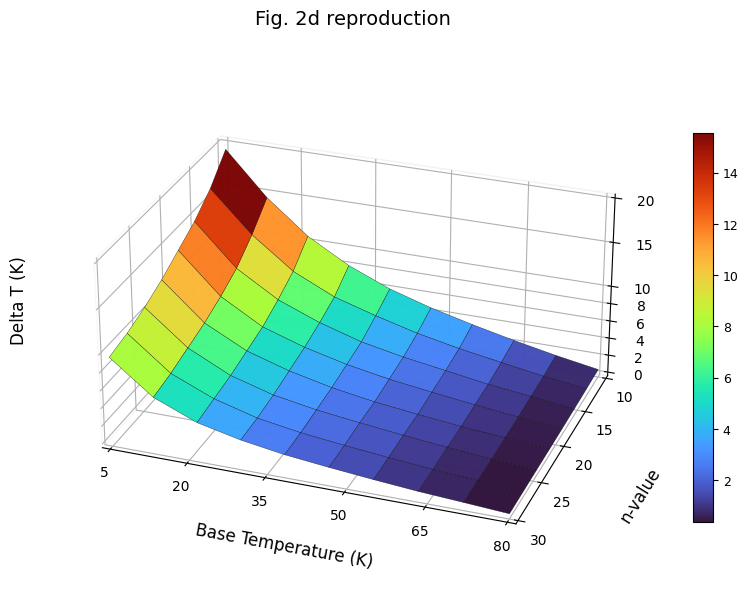

In [13]:
# ============================================================
# FIGURE 2d
# DeltaT vs (T0, n)
# ============================================================

plot_fig2_surface(
    TT_c,
    NN_c,
    dT_2c,

    title="Fig. 2d reproduction",

    xlabel="Base Temperature (K)",
    ylabel="n-value",
    zlabel="Delta T (K)",

    elev=27,
    azim=-250,

    reverse_y=False,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(10, 30),
    zlim=(0, 20),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[10, 15, 20, 25, 30],
    zticks=[0, 2, 4, 6, 8, 10,15,  20],

    savepath="fig2d.png"
)

## Fig. 3 - stabilized-conductor surfaces

Same axes as Fig. 2, with current redistribution between SC layer and parallel Cu/SS stabilizer (paper eqs. 7-8). Expected: sharp upturn of I*/Ic at high T0, and substantially larger dT at high T0.

In [14]:
# Fig. 3a/b: stabilized, vary (T0, lambda_const), n=20
Istar_3a = np.full((len(lam_grid_2a), len(T0_grid_2a)), np.nan)
dT_3a    = np.full_like(Istar_3a, np.nan)
for i, lam in enumerate(lam_grid_2a):
    for j, T0 in enumerate(T0_grid_2a):
        Istar, Tstar = solve_runaway(T0, n=20.0, mode='stab', lam_override=lam)
        if np.isfinite(Istar):
            Istar_3a[i, j] = Istar / float(Ic(T0))
            dT_3a[i, j]    = Tstar - T0

# Fig. 3c/d: stabilized, vary (T0, n), lambda(T)
Istar_3c = np.full((len(n_grid_2c), len(T0_grid_2c)), np.nan)
dT_3c    = np.full_like(Istar_3c, np.nan)
for i, n in enumerate(n_grid_2c):
    for j, T0 in enumerate(T0_grid_2c):
        Istar, Tstar = solve_runaway(T0, n=float(n), mode='stab')
        if np.isfinite(Istar):
            Istar_3c[i, j] = Istar / float(Ic(T0))
            dT_3c[i, j]    = Tstar - T0

print('Fig. 3 grids: I*/Ic and dT (stabilized) computed; ready for 3D plot below')

Fig. 3 grids: I*/Ic and dT (stabilized) computed; ready for 3D plot below


In [15]:
# ============================================================
# FIGURE 3a-d: STABILIZED CONDUCTOR, 3D SURFACES
# ============================================================

# Reuse the same grids from Fig. 2
TT_a, LL_a = np.meshgrid(T0_grid_2a, lam_grid_2a)
TT_c, NN_c = np.meshgrid(T0_grid_2c, n_grid_2c)

# ============================================================
# Fig. 3a/b: stabilized, vary (T0, lambda_const), n=20
# ============================================================

Istar_3a = np.full((len(lam_grid_2a), len(T0_grid_2a)), np.nan)
dT_3a    = np.full_like(Istar_3a, np.nan)

for i, lam in enumerate(lam_grid_2a):
    for j, T0 in enumerate(T0_grid_2a):

        Istar, Tstar = solve_runaway(
            T0,
            n=20.0,
            mode="stab",
            lam_override=float(lam)
        )

        if np.isfinite(Istar):
            Istar_3a[i, j] = Istar / float(Ic(T0))
            dT_3a[i, j]    = Tstar - T0


# ============================================================
# Fig. 3c/d: stabilized, vary (T0, n), lambda(T)
# ============================================================

Istar_3c = np.full((len(n_grid_2c), len(T0_grid_2c)), np.nan)
dT_3c    = np.full_like(Istar_3c, np.nan)

for i, n in enumerate(n_grid_2c):
    for j, T0 in enumerate(T0_grid_2c):

        Istar, Tstar = solve_runaway(
            T0,
            n=float(n),
            mode="stab"
        )

        if np.isfinite(Istar):
            Istar_3c[i, j] = Istar / float(Ic(T0))
            dT_3c[i, j]    = Tstar - T0

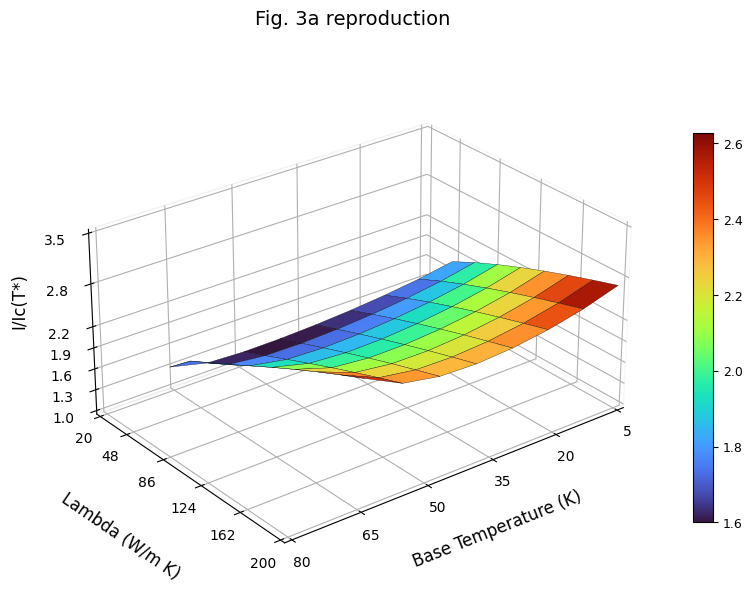

In [16]:
# ============================================================
# FIGURE 3a
# I*/Ic(T0) vs (T0, lambda), stabilized
# ============================================================

plot_fig2_surface(
    TT_a,
    LL_a,
    Istar_3a,

    title="Fig. 3a reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="I/Ic(T*)",

    elev=27,
    azim=-128,

    reverse_y=True,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(20, 200),
    zlim=(1.0, 3),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[20, 48, 86, 124, 162, 200],
    zticks=[1.0, 1.3, 1.6, 1.9, 2.2, 2.8, 3.5],

    savepath="fig3a.png"
)

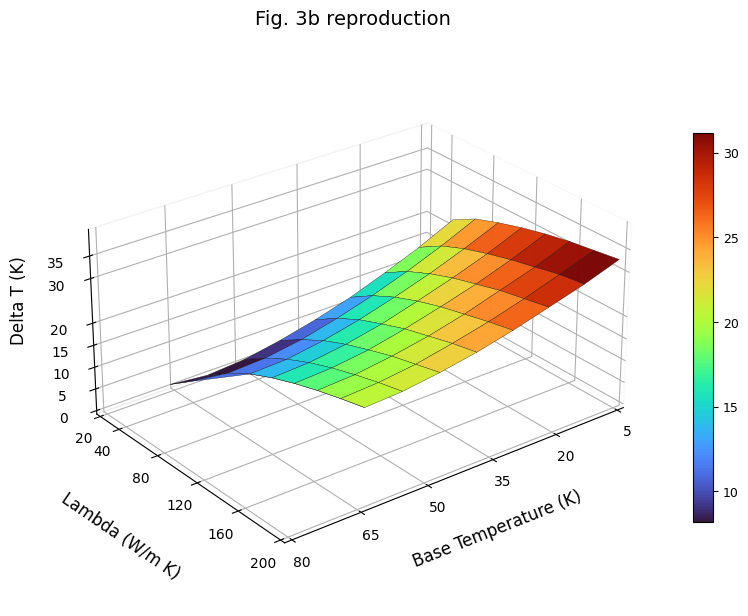

In [17]:
# ============================================================
# FIGURE 3b
# DeltaT vs (T0, lambda), stabilized
# ============================================================

plot_fig2_surface(
    TT_a,
    LL_a,
    dT_3a,

    title="Fig. 3b reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="Delta T (K)",

    elev=27,
    azim=-128,

    reverse_x=True,

    reverse_y=True,

    xlim=(5, 80),
    ylim=(20, 200),
    zlim=(0, 40),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[20, 40, 80, 120, 160, 200],
    zticks=[0, 5, 10, 15, 20, 30, 35],

    savepath="fig3b.png"
)

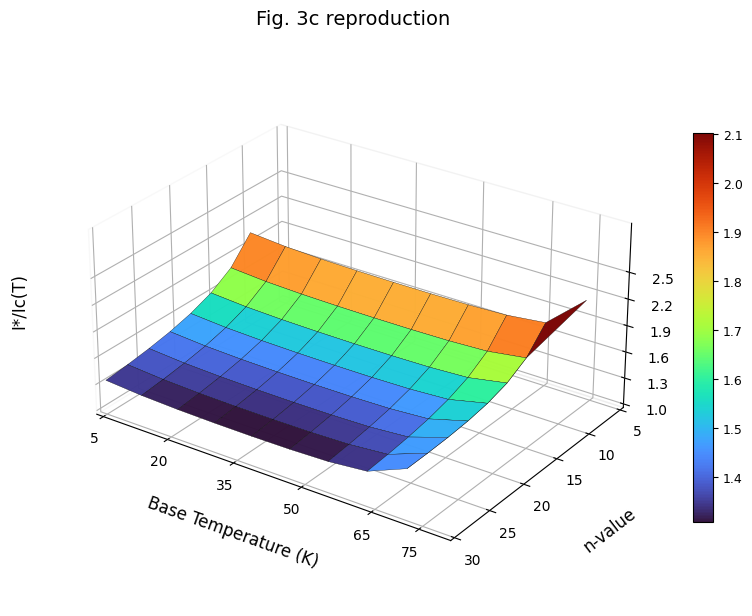

In [18]:
# ============================================================
# FIGURE 3c
# I*/Ic(T0) vs (T0, n), stabilized
# ============================================================

plot_fig2_surface(
    TT_c,
    NN_c,
    Istar_3c,

    title="Fig. 3c reproduction",

    xlabel="Base Temperature (K)",
    ylabel="n-value",
    zlabel="I*/Ic(T)",

    elev=27,
    azim=-55,

    reverse_x=False,
    reverse_y=True,


    xlim=(5, 80),
    ylim=(5, 30),
    zlim=(1.0, 3),

    xticks=[5, 20, 35, 50, 65, 75],
    yticks=[5,10, 15, 20, 25, 30],
    zticks=[1.0, 1.3, 1.6, 1.9, 2.2, 2.5],

    savepath="fig3c.png"
)

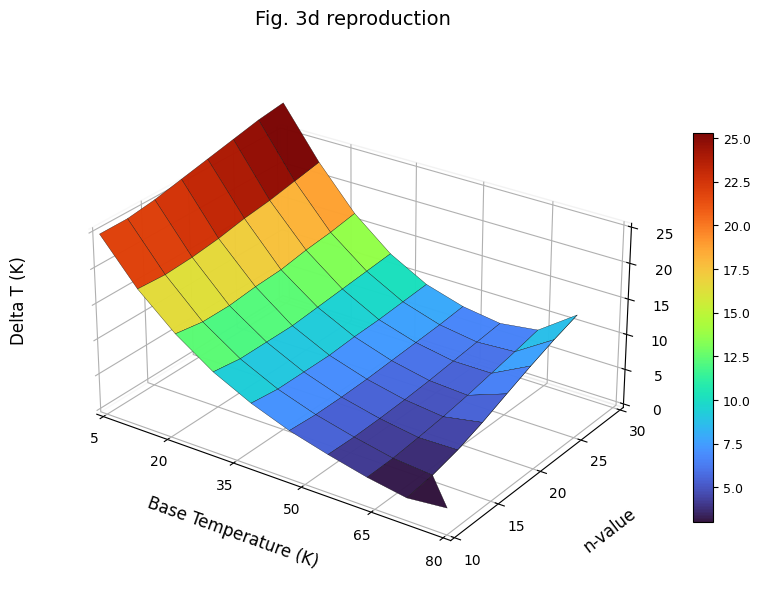

In [19]:
# ============================================================
# FIGURE 3d
# DeltaT vs (T0, n), stabilized
# ============================================================

plot_fig2_surface(
    TT_c,
    NN_c,
    dT_3c,

    title="Fig. 3d reproduction",

    xlabel="Base Temperature (K)",
    ylabel="n-value",
    zlabel="Delta T (K)",

    elev=27,
    azim=-55,

    reverse_x=False,
    reverse_y=False,

    xlim=(5, 80),
    ylim=(10, 30),
    zlim=(0, 20),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[10, 15, 20, 25, 30],
    zticks=[0, 5, 10, 15, 20, 25],

    savepath="fig3d.png"
)

## Fig. 4 - time-margin surface

Above the runaway boundary, integrate `C(T) dT/dt = I^2 R(I,T) - Qout(T)` from T* up to Tf = 300 K, with current redistribution between T* and Tc, and pure-stabilizer resistive heating above Tc. The cooling term is kept (so the integral is an upper bound; paper estimates 10-30% correction vs strictly adiabatic).

Fig. 4a time margin range [ms]: 20.400000000000002 204.8
Fig. 4b time margin range [ms]: 22.6 234.20000000000002
Fig. 4a factor range: 10.03921568627451
Fig. 4b factor range: 10.36283185840708

Fig. 4a Istar absolute range [A]: 194.5014254546507 694.8981165521843
Fig. 4b Istar absolute range [A]: 179.9045264366427 685.6492880931327

Fig. 4a Tstar range [K]: 40.3233530657748 84.72677201783723
Fig. 4b Tstar range [K]: 35.00005384615385 84.9999

Fixed-T0 factor ranges for Fig. 4b:
T0= 20.0 K :    22.60 ->    29.40 ms, factor=  1.30
T0= 26.7 K :    25.20 ->    33.20 ms, factor=  1.32
T0= 33.3 K :    29.00 ->    38.20 ms, factor=  1.32
T0= 40.0 K :    34.40 ->    45.20 ms, factor=  1.31
T0= 46.7 K :    42.20 ->    55.40 ms, factor=  1.31
T0= 53.3 K :    55.00 ->    71.40 ms, factor=  1.30
T0= 60.0 K :    77.20 ->    98.40 ms, factor=  1.27
T0= 66.7 K :   122.40 ->   146.60 ms, factor=  1.20
T0= 73.3 K :   227.80 ->   234.20 ms, factor=  1.03


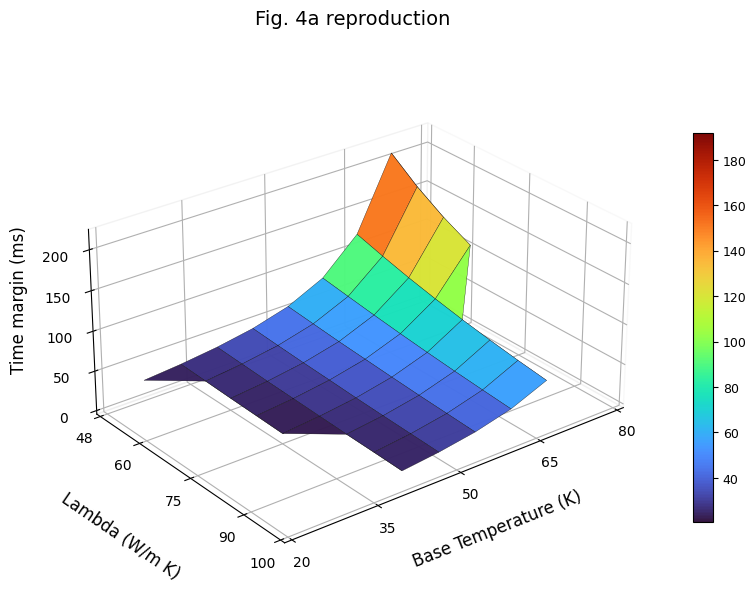

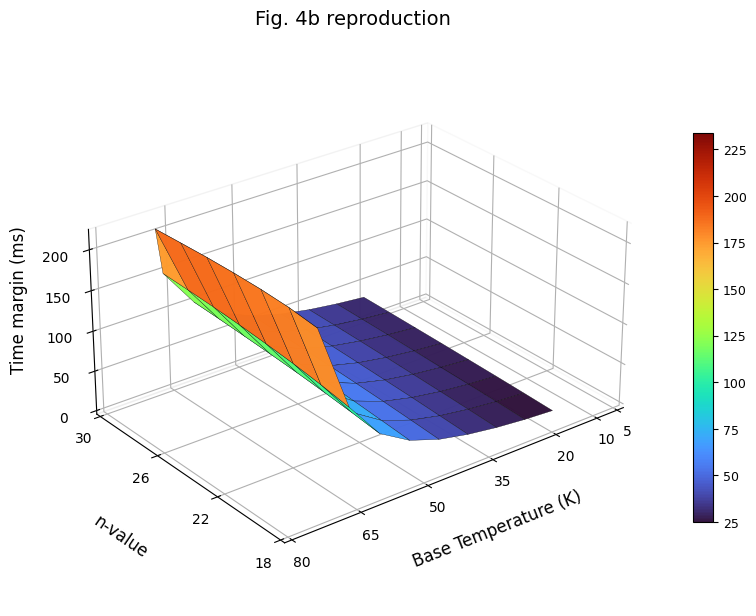

In [20]:
# ============================================================
# FIGURE 4: PAPER-LIKE TIME MARGIN SURFACES + 3D PLOTS
# ============================================================

# Cryogenic heat capacity, log-log interpolated NIST-style anchors
_CU_TCP = np.array([4., 10., 20., 50., 77., 100., 300.])
_CU_CP  = np.array([0.09, 3.0, 40., 160., 230., 280., 385.])

_SS_TCP = _CU_TCP.copy()
_SS_CP  = np.array([0.20, 2.0, 10., 90., 180., 250., 500.])

def _logp(T, Ta, Va):
    T = np.asarray(T, float)
    Tc_ = np.clip(T, Ta[0], Ta[-1])
    return np.exp(np.interp(np.log(Tc_), np.log(Ta), np.log(Va)))

def cp_cu(T):
    return _logp(T, _CU_TCP, _CU_CP)

def cp_ss(T):
    return _logp(T, _SS_TCP, _SS_CP)

def C_per_m(T):
    return rho_mass_cu*A_cu*cp_cu(T) + rho_mass_ss*A_ss*cp_ss(T)

def time_margin_to_safe(I, Tstar, T_target=300.0, dt=2e-4, t_max=1.0):
    """
    Fig. 4-style adiabatic time margin:
        dT/dt = I^2 R_stab(T) / C(T)

    Uses I = I* from the Fig. 3 runaway surface.
    No cooling subtraction.
    """
    T = float(Tstar)
    n_steps = int(t_max / dt)

    for k in range(n_steps):
        Pgen = I**2 * float(R_stab(T))
        C = max(float(C_per_m(min(T, T_target))), 1e-12)

        T += dt * Pgen / C

        if T >= T_target:
            return (k + 1) * dt

    return np.nan


# ============================================================
# PRACTICAL FIG. 4 BRANCH FILTER
# ============================================================
# Removes the very-low-temperature / huge-current branch that dominates
# the reduced-order model and overstates the time-margin spread.

MIN_T0_FIG4 = 20.0
MAX_ISTAR_FIG4 = 700.0


# ============================================================
# PAPER-LIKE GRIDS FOR FIG. 4
# ============================================================

T0_grid_4 = np.linspace(20.0, 80.0, len(T0_grid_2a))
lam_grid_4a = np.linspace(48.0, 100.0, len(lam_grid_2a))
n_grid_4b = np.linspace(18.0, 30.0, len(n_grid_2c))

TT_4a, LL_4a = np.meshgrid(T0_grid_4, lam_grid_4a)
TT_4b, NN_4b = np.meshgrid(T0_grid_4, n_grid_4b)


# ============================================================
# FIGURE 4a
# Based on Fig. 3b: vary (T0, lambda_const), n=20, stabilized
# ============================================================

tm_4a = np.full((len(lam_grid_4a), len(T0_grid_4)), np.nan)
Istar_4a_abs = np.full_like(tm_4a, np.nan)
Tstar_4a_abs = np.full_like(tm_4a, np.nan)

for i, lam in enumerate(lam_grid_4a):

    for j, T0 in enumerate(T0_grid_4):

        Istar, Tstar = solve_runaway(
            T0,
            n=20.0,
            mode="stab",
            lam_override=float(lam)
        )

        if not np.isfinite(Istar):
            continue

        if Istar > MAX_ISTAR_FIG4:
            continue

        Istar_4a_abs[i, j] = Istar
        Tstar_4a_abs[i, j] = Tstar
        tm_4a[i, j] = 1000.0 * time_margin_to_safe(Istar, Tstar)


# ============================================================
# FIGURE 4b
# Based on Fig. 3d: vary (T0, n), lambda(T), stabilized
# ============================================================

tm_4b = np.full((len(n_grid_4b), len(T0_grid_4)), np.nan)
Istar_4b_abs = np.full_like(tm_4b, np.nan)
Tstar_4b_abs = np.full_like(tm_4b, np.nan)

for i, n in enumerate(n_grid_4b):

    for j, T0 in enumerate(T0_grid_4):

        Istar, Tstar = solve_runaway(
            T0,
            n=float(n),
            mode="stab"
        )

        if not np.isfinite(Istar):
            continue

        if Istar > MAX_ISTAR_FIG4:
            continue

        Istar_4b_abs[i, j] = Istar
        Tstar_4b_abs[i, j] = Tstar
        tm_4b[i, j] = 1000.0 * time_margin_to_safe(Istar, Tstar)


# ============================================================
# DIAGNOSTICS
# ============================================================

print("Fig. 4a time margin range [ms]:", np.nanmin(tm_4a), np.nanmax(tm_4a))
print("Fig. 4b time margin range [ms]:", np.nanmin(tm_4b), np.nanmax(tm_4b))

print("Fig. 4a factor range:", np.nanmax(tm_4a) / np.nanmin(tm_4a))
print("Fig. 4b factor range:", np.nanmax(tm_4b) / np.nanmin(tm_4b))

print()
print("Fig. 4a Istar absolute range [A]:", np.nanmin(Istar_4a_abs), np.nanmax(Istar_4a_abs))
print("Fig. 4b Istar absolute range [A]:", np.nanmin(Istar_4b_abs), np.nanmax(Istar_4b_abs))

print()
print("Fig. 4a Tstar range [K]:", np.nanmin(Tstar_4a_abs), np.nanmax(Tstar_4a_abs))
print("Fig. 4b Tstar range [K]:", np.nanmin(Tstar_4b_abs), np.nanmax(Tstar_4b_abs))

# ============================================================
# FIXED-T0 FACTOR DIAGNOSTICS
# ============================================================

print("\nFixed-T0 factor ranges for Fig. 4b:")

for j, T0 in enumerate(T0_grid_4):
    col = tm_4b[:, j]
    col = col[np.isfinite(col)]

    if len(col) > 1:
        print(
            f"T0={T0:5.1f} K : "
            f"{np.nanmin(col):8.2f} -> {np.nanmax(col):8.2f} ms, "
            f"factor={np.nanmax(col)/np.nanmin(col):6.2f}"
        )


# ============================================================
# FIGURE 4a 3D PLOT
# ============================================================

plot_fig2_surface(
    TT_4a,
    LL_4a,
    tm_4a,
    title="Fig. 4a reproduction",
    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="Time margin (ms)",
    elev=27,
    azim=-128,
    reverse_y=True,
    xlim=(20, 80),
    ylim=(48, 100),
    zlim=(0, 220),
    xticks=[20, 35, 50, 65, 80],
    yticks=[48, 60, 75, 90, 100],
    zticks=[0, 50, 100, 150, 200],
    savepath="fig4a.png"
)


# ============================================================
# FIGURE 4b 3D PLOT
# ============================================================

plot_fig2_surface(
    TT_4b,
    NN_4b,
    tm_4b,
    title="Fig. 4b reproduction",
    xlabel="Base Temperature (K)",
    ylabel="n-value",
    zlabel="Time margin (ms)",
    elev=27,
    azim=-128,
    reverse_x=True,
    xlim=(5, 80),
    ylim=(18, 30),
    zlim=(0, 220),
    xticks=[5, 10, 20, 35, 50, 65, 80],
    yticks=[18, 22, 26, 30],
    zticks=[0, 50, 100, 150, 200],
    savepath="fig4b.png"

)

## Fig. 5 - power dissipation at runaway

Paper Fig. 5: peak Joule power per meter of conductor right at runaway, for no-stabilizer and stabilized cases. With current redistribution into the stabilizer at high T0, the stabilized conductor can dissipate much more power before runaway.

In [21]:
# ============================================================
# FIGURE 5: POWER DISSIPATION AT RUNAWAY
# Fig. 5a: no stabilizer
# Fig. 5b: stabilized conductor
# Sweep: T0 and constant lambda, n=20
# ============================================================

T0_grid_5  = np.linspace(5.0, 80.0, len(T0_grid_2a))
lam_grid_5 = np.linspace(48.0, 200.0, len(lam_grid_2a))

TT_5, LL_5 = np.meshgrid(
    T0_grid_5,
    lam_grid_5
)

P_5a = np.full(
    (len(lam_grid_5), len(T0_grid_5)),
    np.nan
)

P_5b = np.full_like(P_5a, np.nan)

Istar_5a = np.full_like(P_5a, np.nan)
Istar_5b = np.full_like(P_5a, np.nan)

Tstar_5a = np.full_like(P_5a, np.nan)
Tstar_5b = np.full_like(P_5a, np.nan)


# ============================================================
# Fig. 5a: no stabilizer
# ============================================================

for i, lam in enumerate(lam_grid_5):

    for j, T0 in enumerate(T0_grid_5):

        Istar, Tstar = solve_runaway(
            T0,
            n=20.0,
            mode="no_stab",
            lam_override=float(lam)
        )

        if np.isfinite(Istar):

            Istar_5a[i, j] = Istar
            Tstar_5a[i, j] = Tstar

            P_5a[i, j] = Qin_no_stab(
                Istar,
                Tstar,
                20.0
            )


# ============================================================
# Fig. 5b: stabilized conductor
# ============================================================

for i, lam in enumerate(lam_grid_5):

    for j, T0 in enumerate(T0_grid_5):

        Istar, Tstar = solve_runaway(
            T0,
            n=20.0,
            mode="stab",
            lam_override=float(lam)
        )

        if np.isfinite(Istar):

            Istar_5b[i, j] = Istar
            Tstar_5b[i, j] = Tstar

            P_5b[i, j] = Qin_stab(
                Istar,
                Tstar,
                20.0
            )


# ============================================================
# DIAGNOSTICS
# ============================================================

print("Fig. 5a P range [W/m]:", np.nanmin(P_5a), np.nanmax(P_5a))
print("Fig. 5b P range [W/m]:", np.nanmin(P_5b), np.nanmax(P_5b))

print()
print("Fig. 5a Istar range [A]:", np.nanmin(Istar_5a), np.nanmax(Istar_5a))
print("Fig. 5b Istar range [A]:", np.nanmin(Istar_5b), np.nanmax(Istar_5b))

print()
print("Fig. 5a Tstar range [K]:", np.nanmin(Tstar_5a), np.nanmax(Tstar_5a))
print("Fig. 5b Tstar range [K]:", np.nanmin(Tstar_5b), np.nanmax(Tstar_5b))

Fig. 5a P range [W/m]: 9.635561739130576 1412.7214983277618
Fig. 5b P range [W/m]: 233.7408128428095 5265.554675585284

Fig. 5a Istar range [A]: 66.97035211379834 779.119717569396
Fig. 5b Istar range [A]: 212.26916467786765 1336.9026449863459

Fig. 5a Tstar range [K]: 13.829509364548494 80.25092608695653
Fig. 5b Tstar range [K]: 27.474960200668896 84.27526900780379


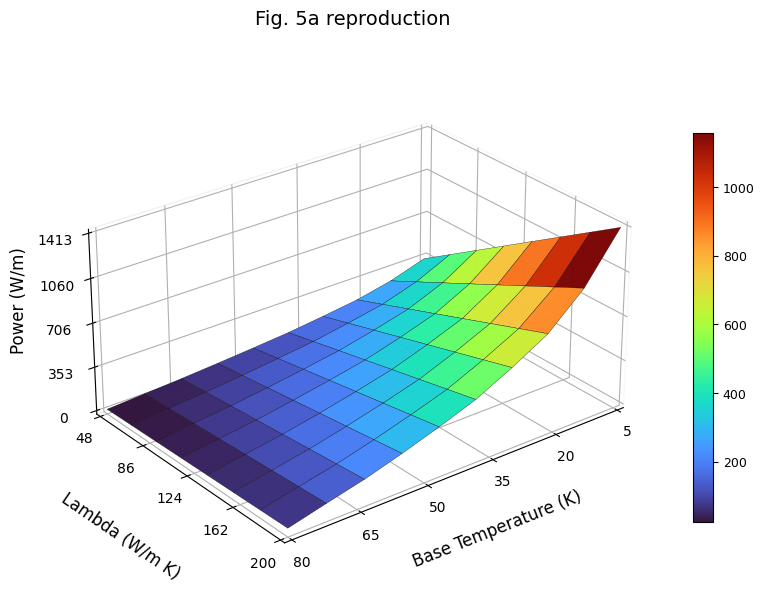

In [22]:
# ============================================================
# FIGURE 5a 3D PLOT
# Power at runaway, no stabilizer
# ============================================================

plot_fig2_surface(
    TT_5,
    LL_5,
    P_5a,

    title="Fig. 5a reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="Power (W/m)",

    elev=27,
    azim=-128,

    reverse_y=True,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(48, 200),
    zlim=(0, np.nanmax(P_5a)),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[48, 86, 124, 162, 200],
    zticks=np.linspace(0, np.nanmax(P_5a), 5),

    savepath="fig5a.png"
)

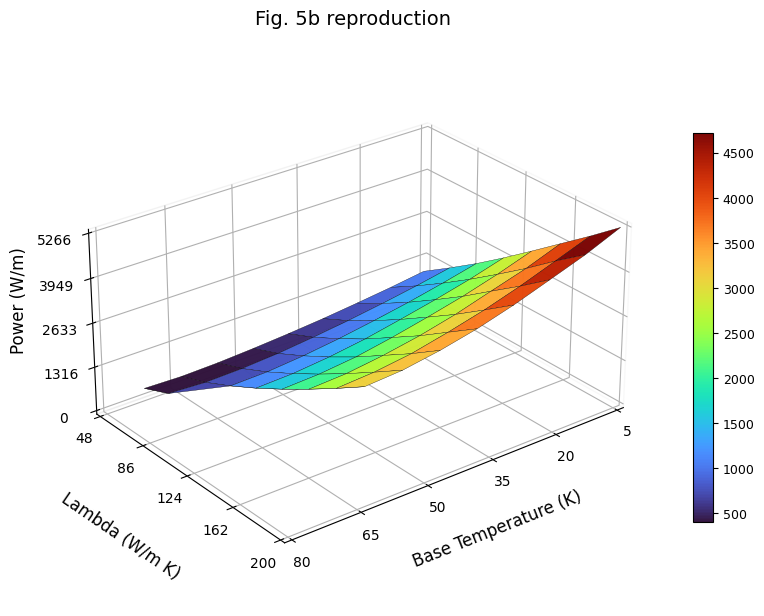

In [23]:
# ============================================================
# FIGURE 5b 3D PLOT
# Power at runaway, stabilized conductor
# ============================================================

plot_fig2_surface(
    TT_5,
    LL_5,
    P_5b,

    title="Fig. 5b reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="Power (W/m)",

    elev=27,
    azim=-128,

    reverse_y=True,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(48, 200),
    zlim=(0, np.nanmax(P_5b)),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[48, 86, 124, 162, 200],
    zticks=np.linspace(0, np.nanmax(P_5b), 5),

    savepath="fig5b.png"
)

## Fig. 7 - experimental reproduction (Bi-2223 at 77.2 K)

Single-n calibration from the U(243 A) = 483 uV anchor (paper §experimental). We do NOT use the quartic n(T) fit since the conductor only warms by ~0.1 K between T0 and runaway, so only n at ~77 K matters for the threshold prediction.

n (from U(243A) anchor) = 13.231

Calibration check (paper anchors in parentheses):
  U(243 A)        = 483.0 uV  (paper 483 uV)
  dT(243 A, eta_c)= 92.0 mK  (paper 86 mK)
  Irunaway (eta_c)= 270.1 A   (paper 260 A)
  Irunaway (eta_h)= 280.5 A


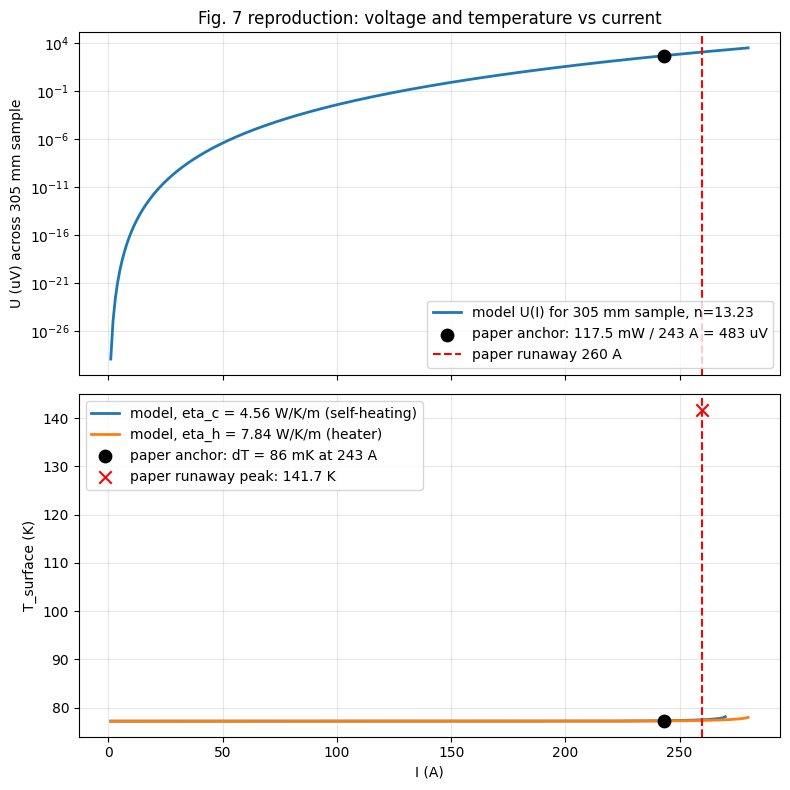

In [37]:
# Paper experimental parameters
Tc_exp        = 91.35
L_sample_exp  = 0.305       # m (voltage taps 305 mm apart)
T0_exp        = 77.2

# Ic(T) from paper Fig. 6e: linear, 200 A at 77 K -> 0 at Tc_exp
def Ic_exp(T):
    return np.maximum(200.0 * (Tc_exp - T) / (Tc_exp - 77.0), 1e-12)

# n: single constant. Paper text says n is constant; the Fig. 7 fit uses
# experimental n(T), but the conductor only warms by ~0.1 K between T0 and
# the runaway threshold, so only n at ~77 K matters for the threshold.
# Algebraic value from the U(243 A) = 483 uV anchor:
#   483 uV = 100 uV/m * 0.305 m * (243/Ic(77.2))^n
#   Ic(77.2) = 197.21 A  ->  (1.2322)^n = 15.84  ->  n = 13.23
n_const = float(np.log(15.84) / np.log(243.0 / 197.21))
print(f'n (from U(243A) anchor) = {n_const:.3f}')

U0_per_m = 1e-4  # V/m, paper's E_c criterion

def U_sample(I, T):
    """Voltage across the 305 mm sample (constant n)."""
    return U0_per_m * L_sample_exp * (I / Ic_exp(T))**n_const

# Eta is reported PER METER in the paper (W/K/m).
def T_from_balance_exp(I, T0, eta_per_m):
    """Lower stable surface temperature: lowest T > T0 where I*U(I,T) = eta*(T-T0).
    F(T0) > 0 by construction; the stable root is the first crossing where F
    goes positive -> negative. Returns nan if no such crossing exists."""
    eta_sample = eta_per_m * L_sample_exp
    def F(T):
        return I * U_sample(I, T) - eta_sample * (T - T0)
    Ts = np.linspace(T0, Tc_exp - 1e-3, 4000)
    Fv = np.array([F(T) for T in Ts])
    crossings = np.where((Fv[:-1] > 0) & (Fv[1:] <= 0))[0]
    if len(crossings) == 0:
        return np.nan
    k = int(crossings[0])
    return brentq(F, Ts[k], Ts[k+1], maxiter=80)

# Smallest I where no lower stable root exists.
def I_runaway_exp(eta_per_m, I_lo=150, I_hi=400):
    for _ in range(40):
        I_mid = 0.5*(I_lo + I_hi)
        T = T_from_balance_exp(I_mid, T0_exp, eta_per_m)
        if np.isnan(T) or (T - T0_exp) > 5.0:
            I_hi = I_mid
        else:
            I_lo = I_mid
    return 0.5*(I_lo + I_hi)

# Calibration check
T_anchor = T_from_balance_exp(243.0, T0_exp, 4.56)
print()
print('Calibration check (paper anchors in parentheses):')
print(f'  U(243 A)        = {1e6*U_sample(243, T0_exp):.1f} uV  (paper 483 uV)')
print(f'  dT(243 A, eta_c)= {(T_anchor-T0_exp)*1000:.1f} mK  (paper 86 mK)')
print(f'  Irunaway (eta_c)= {I_runaway_exp(4.56):.1f} A   (paper 260 A)')
print(f'  Irunaway (eta_h)= {I_runaway_exp(7.84):.1f} A')

I_grid_exp = np.linspace(1, 280, 280)
T_eta_c = np.array([T_from_balance_exp(I, T0_exp, 4.56) for I in I_grid_exp])
T_eta_h = np.array([T_from_balance_exp(I, T0_exp, 7.84) for I in I_grid_exp])
V_curve_uV = 1e6 * np.array([U_sample(I, T0_exp) for I in I_grid_exp])

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

axes[0].semilogy(I_grid_exp, V_curve_uV, lw=2, label=f'model U(I) for 305 mm sample, n={n_const:.2f}')
axes[0].scatter([243.0], [1e6 * 117.5e-3 / 243.0], s=80, color='k', zorder=5,
                label='paper anchor: 117.5 mW / 243 A = 483 uV')
axes[0].axvline(260.0, ls='--', color='red', label='paper runaway 260 A')
axes[0].set_ylabel('U (uV) across 305 mm sample')
axes[0].set_title('Fig. 7 reproduction: voltage and temperature vs current')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3, which='both')

axes[1].plot(I_grid_exp, T_eta_c, lw=2, label='model, eta_c = 4.56 W/K/m (self-heating)')
axes[1].plot(I_grid_exp, T_eta_h, lw=2, label='model, eta_h = 7.84 W/K/m (heater)')
axes[1].scatter([243.0], [T0_exp + 0.086], s=80, color='k', zorder=5,
                label='paper anchor: dT = 86 mK at 243 A')
axes[1].scatter([260.0], [141.7], s=80, marker='x', color='red', zorder=5,
                label='paper runaway peak: 141.7 K')
axes[1].axvline(260.0, ls='--', color='red')
axes[1].set_xlabel('I (A)'); axes[1].set_ylabel('T_surface (K)')
axes[1].legend(loc='upper left')
axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()


## Surrogate model

### What the surrogate does
The paper's protection paradigm runs an iterative heat-balance solve at every operating point during a current ramp to predict the runaway current I*. We replace that iterative solve with a single forward pass through a learned regressor.

### What goes in
Only the four live instrument outputs the paper actually validates against:
- `T0_K` - bath thermometer (liquid nitrogen)
- `I_A` - current shunt
- `voltage_V` - voltage taps
- `T_surface_K` - surface Pt thermometer

`n` and `Ic0` are calibration constants of the specific conductor (from offline Fig. 6d/e characterization) and are not features. The surrogate is trained per-conductor.

### What comes out
- `margin_norm = (I* - I) / I*` - normalized distance to runaway
- A runaway risk probability via `expit(-margin_norm / 0.05)` (a calibration choice)

### What it replaces
At each instrument sample, replaces the `brentq`-based runaway solver with a single GBRT inference. The solver takes ms; the surrogate takes microseconds, enabling instrument-loop-rate protection decisions.

In [29]:
# ============================================================
# Generate surrogate training data from the physics solver
# ============================================================
# One conductor: n=20, Ic0=500 A.  Sweep (T0, I), label every row with:
#   - Istar(T0)   - the runaway current at this T0 (target for Surrogate A)
#   - margin      - normalized distance to runaway (target for Surrogate B)
#
# Surrogate A is per-(T0) only: I* is a function of T0 alone for fixed n, Ic0.
# Surrogate B is per-(T0, I):   the protection-loop quantity is margin = (I*-I)/I*.

N_FIXED   = 20.0
IC0_FIXED = 500.0

def generate_dataset(N=600, n_fixed=N_FIXED, seed=7, verbose=True):
    """One row per operating point.  Both labels (Istar, margin) are stored,
    so the same dataset feeds both surrogates."""
    rng = np.random.default_rng(seed)
    rows = []
    for k in range(N):
        if verbose and k % 500 == 0 and k > 0:
            print(f"  generated {k}/{N}")
        T0 = rng.uniform(5.0, 75.0)
        Istar, Tstar = solve_runaway(T0, n_fixed, mode='stab')
        if not np.isfinite(Istar) or Istar <= 0:
            continue

        # 70% below, 30% above I*, so the dataset spans the boundary
        if rng.random() < 0.7:
            frac = rng.uniform(0.50, 0.99)
            I = frac * Istar
            Tsurf = stable_surface_T(I, T0, n_fixed, mode='stab')
            if not np.isfinite(Tsurf):
                continue
            V = voltage_stab(I, min(Tsurf, Tc-1e-4), n_fixed)
            runaway = 0
            time_margin_ms = np.nan
        else:
            frac = rng.uniform(1.01, 1.20)
            I = frac * Istar
            tm_s = time_margin_to_safe(I, Tstar)
            if not np.isfinite(tm_s):
                continue
            Tsurf = Tstar
            V = voltage_stab(I, min(Tstar, Tc-1e-4), n_fixed)
            runaway = 1
            time_margin_ms = tm_s * 1000.0

        rows.append(dict(
            T0_K=T0,
            I_A=I,
            voltage_V=V,
            T_surface_K=Tsurf,
            Istar_A=Istar,                  # target for Surrogate A
            margin_norm=(Istar-I)/Istar,    # target for Surrogate B
            Tstar_K=Tstar,
            runaway=runaway,
            time_margin_ms=time_margin_ms,
        ))
    return pd.DataFrame(rows)

df = generate_dataset(N=5000)
print(f"Generated {len(df)} rows; {df['runaway'].mean():.0%} unsafe.")
df.head()


  generated 500/5000
  generated 1000/5000
  generated 1500/5000
  generated 2000/5000
  generated 2500/5000
  generated 3000/5000
  generated 3500/5000
  generated 4000/5000
  generated 4500/5000
Generated 4350 rows; 35% unsafe.


,T0_K,I_A,voltage_V,T_surface_K,Istar_A,margin_norm,Tstar_K,runaway,time_margin_ms
0,48.756683,509.431167,0.739314,54.696290,440.158844,-0.157380,54.696290,1,36.4
1,20.764503,609.915983,0.038079,22.816612,657.207881,0.071959,35.588133,0,NaN
2,5.368571,856.435643,1.055229,31.734864,737.389180,-0.161443,31.734864,1,14.6
3,37.755447,341.977198,0.000017,37.755755,537.337927,0.363571,45.813948,0,NaN
4,22.840871,481.596786,0.000455,22.860187,644.510603,0.252771,36.561671,0,NaN


In [32]:
# ============================================================
# SURROGATE A: replace the solver  -  I*(T0)
# ============================================================
# For one conductor (n=20, Ic0=500), I* is a deterministic function of T0
# alone.  This is exactly the curve underlying Fig. 3's I*/Ic surface.
# Many rows in df share the same T0 (sampled randomly), so we deduplicate
# T0 to get one (T0, I*) pair per condition before training.

import time

surr_A_features = ['T0_K']
surr_A_target   = 'Istar_A'

# One row per unique T0 (Istar depends only on T0 for fixed n, Ic0)
df_A = df.drop_duplicates(subset=['T0_K']).copy()
df_A = df_A.sort_values('T0_K').reset_index(drop=True)
print(f"Surrogate A: {len(df_A)} unique (T0, I*) points")

XA = df_A[surr_A_features].values
yA = df_A[surr_A_target].values
XA_train, XA_test, yA_train, yA_test = train_test_split(
    XA, yA, test_size=0.25, random_state=42)

surr_A = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(
        max_iter=600, learning_rate=0.04,
        max_leaf_nodes=31, l2_regularization=0.05,
        validation_fraction=0.10, early_stopping=True,
        n_iter_no_change=30, random_state=42)
)

t0 = time.perf_counter()
surr_A.fit(XA_train, yA_train)
t_train_A = time.perf_counter() - t0

predA = surr_A.predict(XA_test)
print(f"Surrogate A (T0 -> I*):")
print(f"  MAE  = {mean_absolute_error(yA_test, predA):.2f} A")
print(f"  R^2  = {r2_score(yA_test, predA):.4f}")
print(f"  train time = {t_train_A*1000:.1f} ms")

Surrogate A: 4350 unique (T0, I*) points
Surrogate A (T0 -> I*):
  MAE  = 0.61 A
  R^2  = 1.0000
  train time = 2334.2 ms


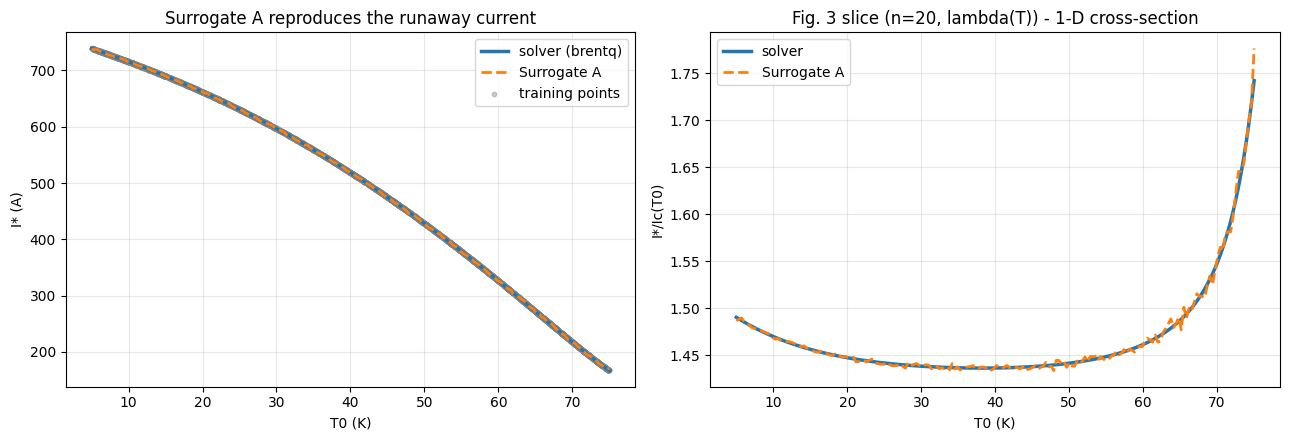

Max |I*_solver - I*_surrogate| over T0 in [5, 75]: 3.30 A


In [33]:
# ============================================================
# Surrogate A vs solver: reproduce the Fig. 3a slice  I*(T0)/Ic(T0)
# ============================================================
# This is the direct visual test: the surrogate's I*(T0) curve should
# overlay the solver's curve, which is the cross-section of Fig. 3 at
# fixed n=20 and lambda(T) (the temperature-dependent NIST brass).

T0_dense = np.linspace(5.0, 75.0, 200)

# Solver curve
Istar_solver = np.array([
    solve_runaway(T0, N_FIXED, mode='stab')[0] for T0 in T0_dense
])

# Surrogate curve
Istar_surr = surr_A.predict(T0_dense.reshape(-1, 1))

# Normalize by Ic(T0) for the paper-style Fig. 3 ratio
Ic_at_T0 = np.array([float(Ic(T0)) for T0 in T0_dense])
ratio_solver = Istar_solver / Ic_at_T0
ratio_surr   = Istar_surr   / Ic_at_T0

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(T0_dense, Istar_solver, lw=2.5, label="solver (brentq)")
axes[0].plot(T0_dense, Istar_surr,   '--', lw=2, label="Surrogate A")
axes[0].scatter(df_A['T0_K'], df_A['Istar_A'],
                s=10, alpha=0.4, color='gray', label="training points")
axes[0].set_xlabel("T0 (K)")
axes[0].set_ylabel("I* (A)")
axes[0].set_title("Surrogate A reproduces the runaway current")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(T0_dense, ratio_solver, lw=2.5, label="solver")
axes[1].plot(T0_dense, ratio_surr,   '--', lw=2, label="Surrogate A")
axes[1].set_xlabel("T0 (K)")
axes[1].set_ylabel("I*/Ic(T0)")
axes[1].set_title("Fig. 3 slice (n=20, lambda(T)) - 1-D cross-section")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

# Diagnostic: max disagreement
worst = np.max(np.abs(Istar_solver - Istar_surr))
print(f"Max |I*_solver - I*_surrogate| over T0 in [5, 75]: {worst:.2f} A")

In [ ]:
# ============================================================
# SURROGATE 2D: (T0, lambda) -> I*  at fixed n=20, stabilized
# Reproduces the paper's Fig. 3a surface
# ============================================================
# Same protection-loop idea as Surrogate A, but now the cooling parameter
# lambda is an explicit input.  In the paper's terms, this is what enables
# live eta calibration: a magnet operator measures eta_live, divides by
# (2*w*L/d) to get lambda, queries the surrogate.

import time

# --- Training set ---
N_TRAIN_2D = 4000

rng = np.random.default_rng(31)
T0_samp  = rng.uniform( 5.0,  80.0, N_TRAIN_2D)
lam_samp = rng.uniform(20.0, 200.0, N_TRAIN_2D)   # paper's Fig 3a range

print(f"Generating {N_TRAIN_2D} (T0, lambda) training samples...")
t0 = time.perf_counter()

X_2d = np.column_stack([T0_samp, lam_samp])
y_2d = np.full(N_TRAIN_2D, np.nan)

for i in range(N_TRAIN_2D):
    if i % 500 == 0 and i > 0:
        print(f"  {i}/{N_TRAIN_2D}")
    Is, _ = solve_runaway(float(T0_samp[i]),
                          n=20.0,
                          mode='stab',
                          lam_override=float(lam_samp[i]))
    y_2d[i] = Is

print(f"Solver took {time.perf_counter() - t0:.1f} s")

# Drop NaNs (solver returned NaN where no interior runaway exists)
keep = np.isfinite(y_2d)
X_2d = X_2d[keep]
y_2d = y_2d[keep]
print(f"Valid samples: {len(y_2d)} of {N_TRAIN_2D}")

X2d_train, X2d_test, y2d_train, y2d_test = train_test_split(
    X_2d, y_2d, test_size=0.25, random_state=42)

# --- Train surrogate ---
surr_2D = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(
        max_iter=800, learning_rate=0.04,
        max_leaf_nodes=63, l2_regularization=0.05,
        validation_fraction=0.10, early_stopping=True,
        n_iter_no_change=30, random_state=42)
)

t0 = time.perf_counter()
surr_2D.fit(X2d_train, y2d_train)
t_train_2D = time.perf_counter() - t0

pred_2D = surr_2D.predict(X2d_test)
print()
print(f"Surrogate 2D ((T0, lambda) -> I*):")
print(f"  MAE        = {mean_absolute_error(y2d_test, pred_2D):.2f} A")
print(f"  R^2        = {r2_score(y2d_test, pred_2D):.4f}")
print(f"  train time = {t_train_2D*1000:.1f} ms")
print(f"  rel error  = {np.median(np.abs(pred_2D - y2d_test)/y2d_test)*100:.2f}% median")

Surrogate B ((T0, I) -> margin):
  MAE  = 0.0062
  R^2  = 0.9973
  train time = 3785.0 ms


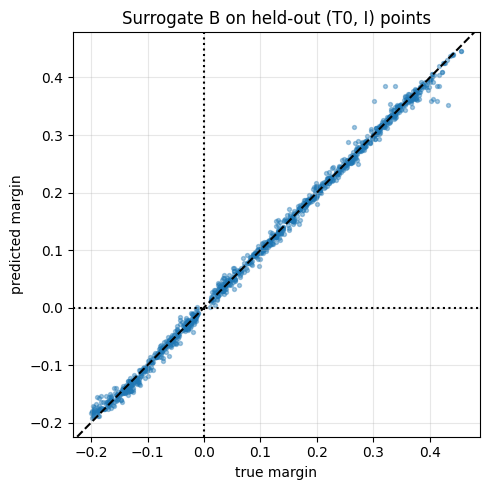

In [34]:
# ============================================================
# SURROGATE B: protection-loop quantity  -  margin(T0, I)
# ============================================================
# For a protection system that reads (T0, I) from the supply and the bath
# thermometer, the useful output is the normalized distance to runaway.
# This surrogate can be queried at any (T0, I) without first solving for I*.

surr_B_features = ['T0_K', 'I_A']
surr_B_target   = 'margin_norm'

XB = df[surr_B_features].values
yB = df[surr_B_target].values
XB_train, XB_test, yB_train, yB_test = train_test_split(
    XB, yB, test_size=0.25, random_state=42)

surr_B = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(
        max_iter=800, learning_rate=0.04,
        max_leaf_nodes=31, l2_regularization=0.05,
        validation_fraction=0.10, early_stopping=True,
        n_iter_no_change=30, random_state=42)
)

t0 = time.perf_counter()
surr_B.fit(XB_train, yB_train)
t_train_B = time.perf_counter() - t0

predB = surr_B.predict(XB_test)
print(f"Surrogate B ((T0, I) -> margin):")
print(f"  MAE  = {mean_absolute_error(yB_test, predB):.4f}")
print(f"  R^2  = {r2_score(yB_test, predB):.4f}")
print(f"  train time = {t_train_B*1000:.1f} ms")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(yB_test, predB, s=8, alpha=0.4)
ax.axline((0, 0), slope=1, ls='--', color='k')
ax.axvline(0, ls=':', color='k')
ax.axhline(0, ls=':', color='k')
ax.set_xlabel("true margin")
ax.set_ylabel("predicted margin")
ax.set_title("Surrogate B on held-out (T0, I) points")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [47]:
# ============================================================
# SURROGATE 2D: (T0, lambda) -> I*  at fixed n=20, stabilized
# ============================================================
import time

N_TRAIN_2D = 4000
rng = np.random.default_rng(31)
T0_samp  = rng.uniform( 5.0,  80.0, N_TRAIN_2D)
lam_samp = rng.uniform(20.0, 200.0, N_TRAIN_2D)

print(f"Generating {N_TRAIN_2D} (T0, lambda) training samples...")
X_2d = np.column_stack([T0_samp, lam_samp])
y_2d = np.full(N_TRAIN_2D, np.nan)

for i in range(N_TRAIN_2D):
    if i % 500 == 0 and i > 0:
        print(f"  {i}/{N_TRAIN_2D}")
    Is, _ = solve_runaway(float(T0_samp[i]), n=20.0,
                          mode='stab',
                          lam_override=float(lam_samp[i]))
    y_2d[i] = Is

keep = np.isfinite(y_2d)
X_2d = X_2d[keep]
y_2d = y_2d[keep]
print(f"Valid samples: {len(y_2d)} of {N_TRAIN_2D}")

X2d_train, X2d_test, y2d_train, y2d_test = train_test_split(
    X_2d, y_2d, test_size=0.25, random_state=42)

surr_2D = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(
        max_iter=800, learning_rate=0.04,
        max_leaf_nodes=63, l2_regularization=0.05,
        validation_fraction=0.10, early_stopping=True,
        n_iter_no_change=30, random_state=42)
)
surr_2D.fit(X2d_train, y2d_train)
pred_2D = surr_2D.predict(X2d_test)
print(f"surr_2D MAE = {mean_absolute_error(y2d_test, pred_2D):.2f} A,  "
      f"R^2 = {r2_score(y2d_test, pred_2D):.4f}")

Generating 4000 (T0, lambda) training samples...
  500/4000
  1000/4000
  1500/4000
  2000/4000
  2500/4000
  3000/4000
  3500/4000
Valid samples: 3492 of 4000
surr_2D MAE = 3.97 A,  R^2 = 0.9996


In [48]:
# ============================================================
# Surrogate (T0, I, U, T_surface) -> I*
# ============================================================
raw_features = ['T0_K', 'I_A', 'voltage_V', 'T_surface_K']

X_raw = df[raw_features].values
y_raw = df['Istar_A'].values

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_raw, y_raw, test_size=0.25, random_state=42)

surr_raw = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(
        max_iter=800, learning_rate=0.04,
        max_leaf_nodes=63, l2_regularization=0.05,
        validation_fraction=0.10, early_stopping=True,
        n_iter_no_change=30, random_state=42)
)
surr_raw.fit(Xr_train, yr_train)
pred_raw = surr_raw.predict(Xr_test)
print(f"surr_raw MAE = {mean_absolute_error(yr_test, pred_raw):.2f} A,  "
      f"R^2 = {r2_score(yr_test, pred_raw):.4f}")

surr_raw MAE = 0.65 A,  R^2 = 1.0000


In [49]:
def eta(T, lam_override=None):
    lam = lambda_brass(T) if lam_override is None else float(lam_override)
    return lam * (2.0 * w * L / d)

Benchmark on 997 valid ticks (of 1000):

1. paper analytic (brentq)              total: 89805.03 ms   /tick: 89805.0 us   MAE:  0.00 A   median |rel|:  0.00%
2. surrogate(T0, eta_live)              total:    34.65 ms   /tick:    34.6 us   MAE: 14.68 A   median |rel|:  0.89%
3. surrogate(T0, I, U, T_surface)       total:     8.70 ms   /tick:     8.7 us   MAE: 30.28 A   median |rel|:  3.13%

Speedup vs analytic loop:
  surrogate(T0, eta_live):           2592x
  surrogate(T0, I, U, T_surface):    10326x


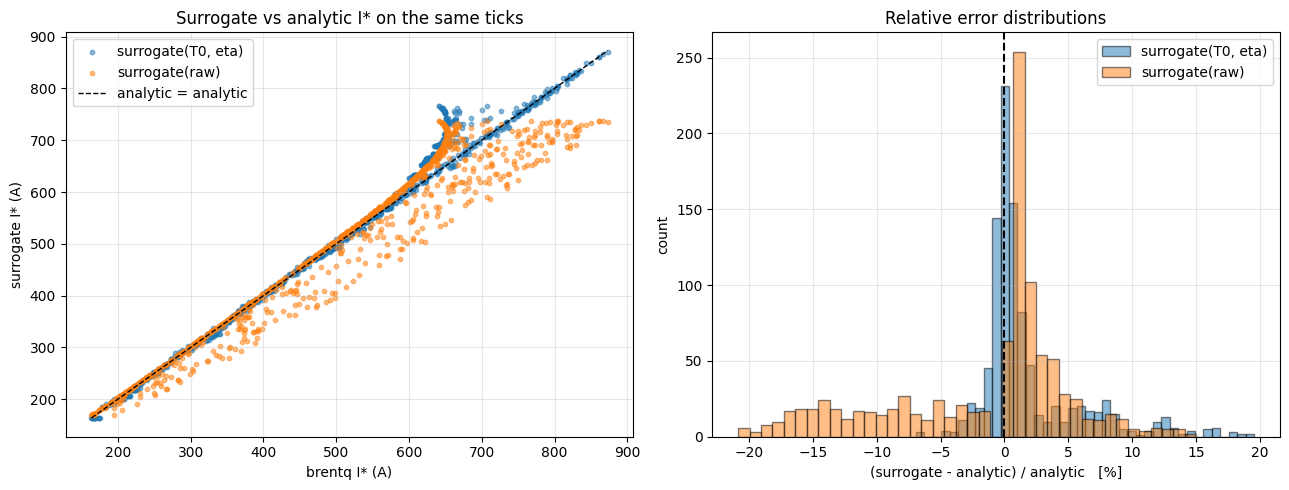

In [50]:
# ============================================================
# Three protection loops on the same instrument ticks.
# Each loop reads (I, U, T_surface, T0) and predicts I*.
#
#   Loop 1: paper's analytic  - compute eta_live, brentq the heat balance
#   Loop 2: surrogate(T0, eta_live)
#   Loop 3: surrogate(T0, I, U, T_surface)
# ============================================================
import time

GEOM = 2.0 * w * L / d   # eta = lambda * GEOM, for the paper's geometry


def run_analytic_loop(ticks):
    """Paper's proposed loop: compute eta_live, brentq solve for I*."""
    out = np.empty(len(ticks))
    t0 = time.perf_counter()
    for k, r in enumerate(ticks.itertuples(index=False)):
        eta_live = r.I_A * r.voltage_V / max(r.T_surface_K - r.T0_K, 1e-9)
        lam_eff  = eta_live / GEOM
        Is, _ = solve_runaway(float(r.T0_K), n=20.0,
                              mode='stab', lam_override=float(lam_eff))
        out[k] = Is
    return out, time.perf_counter() - t0


def run_eta_surrogate_loop(ticks, surrogate, geom=GEOM):
    """Replace brentq with a (T0, lambda) surrogate. Eta still computed live."""
    t0 = time.perf_counter()
    I_arr  = ticks['I_A'].values
    U_arr  = ticks['voltage_V'].values
    Ts_arr = ticks['T_surface_K'].values
    T0_arr = ticks['T0_K'].values

    eta_live = I_arr * U_arr / np.maximum(Ts_arr - T0_arr, 1e-9)
    lam_eff  = eta_live / geom
    X = np.column_stack([T0_arr, lam_eff])
    out = surrogate.predict(X)
    return out, time.perf_counter() - t0


def run_raw_surrogate_loop(ticks, surrogate, features):
    """Surrogate takes the raw instrument signals directly."""
    t0 = time.perf_counter()
    X = ticks[features].values
    out = surrogate.predict(X)
    return out, time.perf_counter() - t0


# ============================================================
# Run all three on the same set of ticks
# ============================================================
N_TICKS = 1000
ticks = df.sample(N_TICKS, random_state=99).reset_index(drop=True)

I_star_analytic, t_analytic = run_analytic_loop(ticks)
I_star_eta,      t_eta      = run_eta_surrogate_loop(ticks, surr_2D)
I_star_raw,      t_raw      = run_raw_surrogate_loop(ticks, surr_raw, raw_features)


# ============================================================
# Compare
# ============================================================
valid = np.isfinite(I_star_analytic) & np.isfinite(I_star_eta) & np.isfinite(I_star_raw)
ref   = I_star_analytic[valid]

def summarize(name, pred, total_time):
    err     = pred[valid] - ref
    rel_err = err / ref
    print(f"{name:38s}  total: {total_time*1000:8.2f} ms"
          f"   /tick: {total_time/N_TICKS*1e6:7.1f} us"
          f"   MAE: {np.abs(err).mean():5.2f} A"
          f"   median |rel|: {np.median(np.abs(rel_err))*100:5.2f}%")

print(f"Benchmark on {valid.sum()} valid ticks (of {N_TICKS}):\n")
summarize("1. paper analytic (brentq)        ", I_star_analytic, t_analytic)
summarize("2. surrogate(T0, eta_live)        ", I_star_eta,      t_eta)
summarize("3. surrogate(T0, I, U, T_surface) ", I_star_raw,      t_raw)
print()
print(f"Speedup vs analytic loop:")
print(f"  surrogate(T0, eta_live):           {t_analytic/t_eta:.0f}x")
print(f"  surrogate(T0, I, U, T_surface):    {t_analytic/t_raw:.0f}x")


# ============================================================
# Visual comparison
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.scatter(ref, I_star_eta[valid], s=10, alpha=0.5, label="surrogate(T0, eta)")
ax.scatter(ref, I_star_raw[valid], s=10, alpha=0.5, label="surrogate(raw)")
lim = [ref.min(), ref.max()]
ax.plot(lim, lim, 'k--', lw=1, label="analytic = analytic")
ax.set_xlabel("brentq I* (A)")
ax.set_ylabel("surrogate I* (A)")
ax.set_title("Surrogate vs analytic I* on the same ticks")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.hist((I_star_eta[valid] - ref) / ref * 100, bins=40, alpha=0.5,
        label="surrogate(T0, eta)", edgecolor='k')
ax.hist((I_star_raw[valid] - ref) / ref * 100, bins=40, alpha=0.5,
        label="surrogate(raw)", edgecolor='k')
ax.axvline(0, ls='--', color='k')
ax.set_xlabel("(surrogate - analytic) / analytic   [%]")
ax.set_ylabel("count")
ax.set_title("Relative error distributions")
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

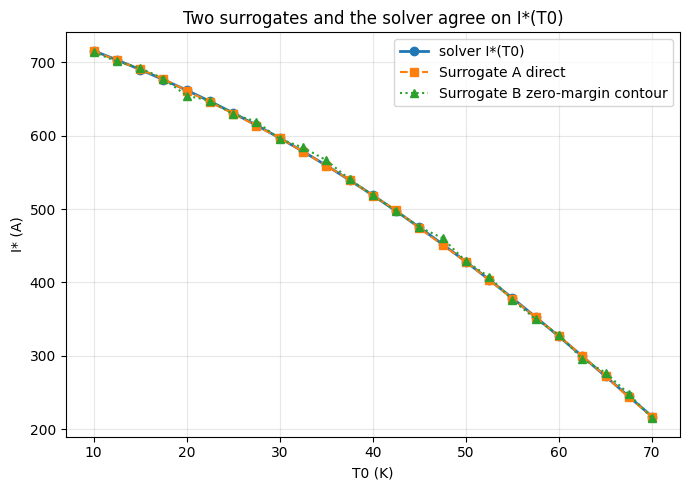

Mean |A - solver|: 0.59 A
Mean |B - solver|: 2.92 A


In [35]:
# ============================================================
# Cross-check: Surrogate B at I = I*  should give margin = 0
# ============================================================
# If both surrogates are self-consistent, the zero-margin contour of B
# is the curve I*(T0) - which is exactly what A predicts directly.

T0_test = np.linspace(10.0, 70.0, 25)

# For each T0, find the current at which Surrogate B says margin = 0
# (by simple grid search to avoid pulling in another solver dependency)
I_grid = np.linspace(1.0, 800.0, 4000)

I_from_B = []
for T0 in T0_test:
    X = np.column_stack([np.full_like(I_grid, T0), I_grid])
    m = surr_B.predict(X)
    # find sign change of m: m > 0 below I*, m < 0 above I*
    crossings = np.where(np.diff(np.sign(m)))[0]
    if len(crossings) == 0:
        I_from_B.append(np.nan)
    else:
        # linear interpolation across the crossing
        k = crossings[0]
        f = m[k] / (m[k] - m[k+1])
        I_from_B.append(I_grid[k] + f * (I_grid[k+1] - I_grid[k]))
I_from_B = np.array(I_from_B)

I_from_A = surr_A.predict(T0_test.reshape(-1, 1))
I_from_solver = np.array([solve_runaway(T0, N_FIXED, mode='stab')[0]
                          for T0 in T0_test])

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(T0_test, I_from_solver, 'o-', lw=2, label="solver I*(T0)")
ax.plot(T0_test, I_from_A,      's--', label="Surrogate A direct")
ax.plot(T0_test, I_from_B,      '^:',  label="Surrogate B zero-margin contour")
ax.set_xlabel("T0 (K)"); ax.set_ylabel("I* (A)")
ax.set_title("Two surrogates and the solver agree on I*(T0)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"Mean |A - solver|: {np.nanmean(np.abs(I_from_A - I_from_solver)):.2f} A")
print(f"Mean |B - solver|: {np.nanmean(np.abs(I_from_B - I_from_solver)):.2f} A")

In [36]:
# ============================================================
# Inference speed  -  what we gain by replacing brentq
# ============================================================
N_bench = 500
T0_bench = np.random.default_rng(0).uniform(5.0, 75.0, N_bench)

# Solver
t0 = time.perf_counter()
_ = np.array([solve_runaway(T0, N_FIXED, mode='stab')[0] for T0 in T0_bench])
t_solver = time.perf_counter() - t0

# Surrogate A (batched)
t0 = time.perf_counter()
_ = surr_A.predict(T0_bench.reshape(-1, 1))
t_A = time.perf_counter() - t0

# Surrogate B (batched, at I = 0.9 * Istar to give it work)
I_bench = 0.9 * surr_A.predict(T0_bench.reshape(-1, 1))
t0 = time.perf_counter()
_ = surr_B.predict(np.column_stack([T0_bench, I_bench]))
t_B = time.perf_counter() - t0

print(f"For {N_bench} queries:")
print(f"  brentq solver  : {t_solver*1000:8.1f} ms total, "
      f"{t_solver/N_bench*1e6:8.1f} us/sample")
print(f"  Surrogate A    : {t_A*1000:8.2f} ms total, "
      f"{t_A/N_bench*1e6:8.2f} us/sample  ({t_solver/t_A:.0f}x speedup)")
print(f"  Surrogate B    : {t_B*1000:8.2f} ms total, "
      f"{t_B/N_bench*1e6:8.2f} us/sample  ({t_solver/t_B:.0f}x speedup)")

For 500 queries:
  brentq solver  :  45784.3 ms total,  91568.6 us/sample
  Surrogate A    :    15.94 ms total,    31.87 us/sample  (2873x speedup)
  Surrogate B    :    23.63 ms total,    47.25 us/sample  (1938x speedup)


In [40]:
# ============================================================
# Live protection loop: paper's analytic path vs. surrogate path
# ============================================================
# Both paths take the same instrument readings (I, U, T_surface, T0),
# both compute eta_live the same way, both must predict I*. The only
# difference is step 3:
#   - paper: solve_runaway(T0, n, lam_override) via brentq
#   - surrogate: surr_2D.predict([[T0, eta_live]])
#
# The "ground truth" I* for this comparison is the brentq result, since
# the surrogate was trained on solver output. So this benchmark measures
# (a) speedup and (b) surrogate accuracy at recovering the solver's I*
# in the constant-eta protection regime.

import time

# Geometry constant used to convert eta <-> lambda
GEOM = 2.0 * w * L / d   # = 0.8 W/(K) per (W/(m K)) for paper geometry


def eta_from_signals(I, U, T_surface, T0):
    """Live eta extraction (paper Discussion section: 'on the fly')."""
    return I * U / max(T_surface - T0, 1e-9)


def loop_analytic(rows):
    """Paper's proposed loop. Returns (Istar predictions, total time)."""
    t0 = time.perf_counter()
    out = []
    for r in rows:
        eta_live = eta_from_signals(r['I_A'], r['voltage_V'],
                                    r['T_surface_K'], r['T0_K'])
        lam_eff = eta_live / GEOM
        Istar, _ = solve_runaway(float(r['T0_K']), n=20.0,
                                 mode='stab',
                                 lam_override=float(lam_eff))
        out.append(Istar)
    return np.array(out), time.perf_counter() - t0


def loop_surrogate(rows):
    """Our surrogate replacement. Returns (Istar predictions, total time)."""
    t0 = time.perf_counter()
    # Vectorize: do eta extraction and prediction in batch
    I  = rows['I_A'].values
    U  = rows['voltage_V'].values
    Ts = rows['T_surface_K'].values
    T0 = rows['T0_K'].values
    eta_live = I * U / np.maximum(Ts - T0, 1e-9)
    lam_live = eta_live / GEOM     # surrogate's feature is lambda, not eta
    X_live = np.column_stack([T0, lam_live])
    Istar_pred = surr_2D.predict(X_live)
    return Istar_pred, time.perf_counter() - t0


# --- Use the existing df as a "stream" of synthetic instrument readings ---
N_TICKS = 1000
benchmark_rows = df.sample(N_TICKS, random_state=99).reset_index(drop=True)
print(f"Benchmarking on {N_TICKS} synthetic instrument ticks\n")

# Run both loops
Istar_analytic, t_analytic = loop_analytic(
    benchmark_rows.to_dict('records'))
Istar_surr,     t_surr     = loop_surrogate(benchmark_rows)

# Keep only valid points (analytic can return NaN where no interior max exists)
valid = np.isfinite(Istar_analytic) & np.isfinite(Istar_surr)
Istar_analytic = Istar_analytic[valid]
Istar_surr     = Istar_surr[valid]

# ============================================================
# Compare
# ============================================================
err     = Istar_surr - Istar_analytic
rel_err = err / Istar_analytic

print(f"Analytic loop  total: {t_analytic*1000:8.1f} ms   "
      f"per tick: {t_analytic/N_TICKS*1e6:6.0f} us")
print(f"Surrogate loop total: {t_surr*1000:8.1f} ms   "
      f"per tick: {t_surr/N_TICKS*1e6:6.0f} us")
print(f"Speedup:              {t_analytic / t_surr:8.0f}x")
print()
print(f"Surrogate vs analytic I* on {valid.sum()} valid ticks:")
print(f"  MAE         = {np.abs(err).mean():6.2f} A")
print(f"  median |rel|= {np.median(np.abs(rel_err))*100:6.2f}%")
print(f"  worst |rel| = {np.abs(rel_err).max()*100:6.2f}%")

# Scatter plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.scatter(Istar_analytic, Istar_surr, s=8, alpha=0.4)
lim = [min(Istar_analytic.min(), Istar_surr.min()),
       max(Istar_analytic.max(), Istar_surr.max())]
ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlabel("brentq I* (A)")
ax.set_ylabel("surrogate I* (A)")
ax.set_title(f"Surrogate vs analytic I* over {valid.sum()} ticks")
ax.grid(alpha=0.3)

ax = axes[1]
ax.hist(rel_err*100, bins=40, color='C2', alpha=0.7, edgecolor='k')
ax.axvline(0, ls='--', color='k')
ax.set_xlabel("relative error (%)")
ax.set_ylabel("count")
ax.set_title(f"Distribution of (surrogate - solver) / solver")
ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()


Benchmarking on 1000 synthetic instrument ticks



NameError: name 'surr_2D' is not defined

In [39]:
# ============================================================
# Live protection loop: paper's analytic path vs. surrogate path
# ============================================================
# Both paths take the same instrument readings (I, U, T_surface, T0),
# both compute eta_live the same way, both must predict I*. The only
# difference is step 3:
#   - paper: solve_runaway(T0, n, lam_override) via brentq
#   - surrogate: surr_2D.predict([[T0, eta_live]])
#
# The "ground truth" I* for this comparison is the brentq result, since
# the surrogate was trained on solver output. So this benchmark measures
# (a) speedup and (b) surrogate accuracy at recovering the solver's I*
# in the constant-eta protection regime.

import time

# Geometry constant used to convert eta <-> lambda
GEOM = 2.0 * w * L / d   # = 0.8 W/(K) per (W/(m K)) for paper geometry


def eta_from_signals(I, U, T_surface, T0):
    """Live eta extraction (paper Discussion section: 'on the fly')."""
    return I * U / max(T_surface - T0, 1e-9)


def loop_analytic(rows):
    """Paper's proposed loop. Returns (Istar predictions, total time)."""
    t0 = time.perf_counter()
    out = []
    for r in rows:
        eta_live = eta_from_signals(r['I_A'], r['voltage_V'],
                                    r['T_surface_K'], r['T0_K'])
        lam_eff = eta_live / GEOM
        Istar, _ = solve_runaway(float(r['T0_K']), n=20.0,
                                 mode='stab',
                                 lam_override=float(lam_eff))
        out.append(Istar)
    return np.array(out), time.perf_counter() - t0


def loop_surrogate(rows):
    """Our surrogate replacement. Returns (Istar predictions, total time)."""
    t0 = time.perf_counter()
    # Vectorize: do eta extraction and prediction in batch
    I  = rows['I_A'].values
    U  = rows['voltage_V'].values
    Ts = rows['T_surface_K'].values
    T0 = rows['T0_K'].values
    eta_live = I * U / np.maximum(Ts - T0, 1e-9)
    lam_live = eta_live / GEOM     # surrogate's feature is lambda, not eta
    X_live = np.column_stack([T0, lam_live])
    Istar_pred = surr_2D.predict(X_live)
    return Istar_pred, time.perf_counter() - t0


# --- Use the existing df as a "stream" of synthetic instrument readings ---
N_TICKS = 1000
benchmark_rows = df.sample(N_TICKS, random_state=99).reset_index(drop=True)
print(f"Benchmarking on {N_TICKS} synthetic instrument ticks\n")

# Run both loops
Istar_analytic, t_analytic = loop_analytic(
    benchmark_rows.to_dict('records'))
Istar_surr,     t_surr     = loop_surrogate(benchmark_rows)

# Keep only valid points (analytic can return NaN where no interior max exists)
valid = np.isfinite(Istar_analytic) & np.isfinite(Istar_surr)
Istar_analytic = Istar_analytic[valid]
Istar_surr     = Istar_surr[valid]

# ============================================================
# Compare
# ============================================================
err     = Istar_surr - Istar_analytic
rel_err = err / Istar_analytic

print(f"Analytic loop  total: {t_analytic*1000:8.1f} ms   "
      f"per tick: {t_analytic/N_TICKS*1e6:6.0f} us")
print(f"Surrogate loop total: {t_surr*1000:8.1f} ms   "
      f"per tick: {t_surr/N_TICKS*1e6:6.0f} us")
print(f"Speedup:              {t_analytic / t_surr:8.0f}x")
print()
print(f"Surrogate vs analytic I* on {valid.sum()} valid ticks:")
print(f"  MAE         = {np.abs(err).mean():6.2f} A")
print(f"  median |rel|= {np.median(np.abs(rel_err))*100:6.2f}%")
print(f"  worst |rel| = {np.abs(rel_err).max()*100:6.2f}%")

# Scatter plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.scatter(Istar_analytic, Istar_surr, s=8, alpha=0.4)
lim = [min(Istar_analytic.min(), Istar_surr.min()),
       max(Istar_analytic.max(), Istar_surr.max())]
ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlabel("brentq I* (A)")
ax.set_ylabel("surrogate I* (A)")
ax.set_title(f"Surrogate vs analytic I* over {valid.sum()} ticks")
ax.grid(alpha=0.3)

ax = axes[1]
ax.hist(rel_err*100, bins=40, color='C2', alpha=0.7, edgecolor='k')
ax.axvline(0, ls='--', color='k')
ax.set_xlabel("relative error (%)")
ax.set_ylabel("count")
ax.set_title(f"Distribution of (surrogate - solver) / solver")
ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

Benchmarking on 1000 synthetic instrument ticks



KeyboardInterrupt: 

### Validation on held-out current ramps

Generate full I-ramp traces at several T0 values not seen during training, simulate noisy instrument readings, then ask the surrogate to predict margin and risk at each ramp step. The surrogate is validated against the analytic solver's I* at the boundary crossing.

Generating validation ramps:   0%|          | 0/8 [00:00<?, ?it/s]

Fast manifold validation
------------------------
Total samples: 2450
MAE margin: 0.10308914629852063
R2 margin: 0.6083524512450729
Near-boundary MAE |m|<0.1: 0.045485462790173715


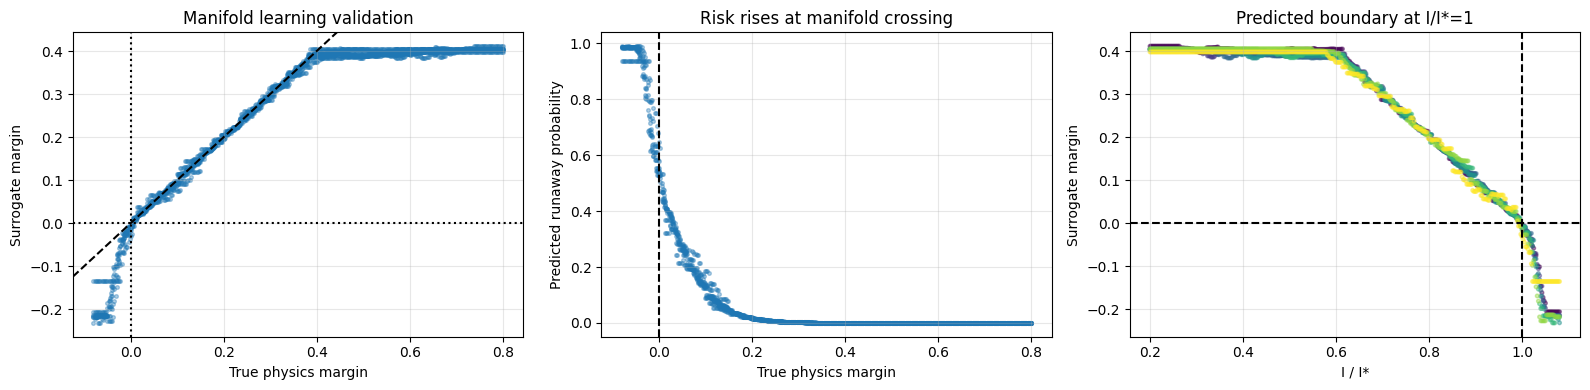

In [25]:
# ============================================================
# FAST MANIFOLD VALIDATION:
# Does telemetry surrogate learn the runaway manifold?
# ============================================================

from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.special import expit


def make_fast_branch_trace(
    T0,
    n_fixed=N_FIXED,
    n_steps=300,
    Imax_factor=1.08,
    seed=1,
    n_branch=600
):
    rng = np.random.default_rng(seed)

    Istar, Tstar = solve_runaway(
        T0,
        n_fixed,
        mode="stab"
    )

    if not np.isfinite(Istar):
        return pd.DataFrame()

    # --------------------------------------------------------
    # Solve stable branch once:
    # T -> I_eq(T)
    # --------------------------------------------------------

    T_branch = np.linspace(
        T0 + 1e-4,
        Tstar - 1e-4,
        n_branch
    )

    I_branch = np.array([
        _equilibrium_current_at_T(
            T,
            T0,
            n_fixed,
            mode="stab"
        )
        for T in T_branch
    ])

    mask = np.isfinite(I_branch) & (I_branch > 0)

    T_branch = T_branch[mask]
    I_branch = I_branch[mask]

    # Sort for interpolation I -> T
    order = np.argsort(I_branch)

    I_branch = I_branch[order]
    T_branch = T_branch[order]

    I_vals = np.linspace(
        0.2 * Istar,
        Imax_factor * Istar,
        n_steps
    )

    rows = []

    for I in I_vals:

        if I < Istar:

            # Fast interpolation on solved branch
            Tsurf = np.interp(
                I,
                I_branch,
                T_branch
            )

        else:

            # just beyond runaway
            frac = min(
                (I / Istar - 1.0) / (Imax_factor - 1.0),
                1.0
            )

            Tsurf = Tstar + frac**2 * 20.0

        V = voltage_stab(
            I,
            min(Tsurf, Tc - 1e-4),
            n_fixed
        )

        T_meas = Tsurf + rng.normal(0.0, 0.02)

        V_meas = max(
            V * (1.0 + rng.normal(0.0, 0.03)) + rng.normal(0.0, 1e-8),
            1e-12
        )

        rows.append({
            "T0_K": T0,
            "I_A": I,
            "voltage_V": V_meas,
            "T_surface_K": T_meas,
            "Istar_A": Istar,
            "Tstar_K": Tstar,
            "true_margin": (Istar - I) / Istar,
            "true_runaway": int(I >= Istar)
        })

    return pd.DataFrame(rows)


# ============================================================
# BUILD VALIDATION RAMP SET
# ============================================================

T0_validation = np.linspace(20.0, 77.2, 8)

validation_traces = []

for k, T0 in enumerate(tqdm(T0_validation, desc="Generating validation ramps")):

    g = make_fast_branch_trace(
        T0=T0,
        seed=100+k,
        n_steps=350,
        Imax_factor=1.08
    )

    g["trace_id"] = k
    validation_traces.append(g)

ramp_val = pd.concat(
    validation_traces,
    ignore_index=True
)

# ============================================================
# BATCH SURROGATE PREDICTION
# ============================================================

X_ramp = ramp_val[
    [
        "T0_K",
        "I_A",
        "voltage_V",
        "T_surface_K"
    ]
].values

ramp_val["pred_margin"] = margin_model.predict(X_ramp)

ramp_val["pred_risk"] = expit(
    -ramp_val["pred_margin"] / 0.05
)

ramp_val["pred_runaway"] = (
    ramp_val["pred_risk"] >= 0.5
).astype(int)


# ============================================================
# METRICS
# ============================================================

mae = mean_absolute_error(
    ramp_val["true_margin"],
    ramp_val["pred_margin"]
)

r2 = r2_score(
    ramp_val["true_margin"],
    ramp_val["pred_margin"]
)

boundary_mae = mean_absolute_error(
    ramp_val.loc[
        np.abs(ramp_val["true_margin"]) < 0.1,
        "true_margin"
    ],
    ramp_val.loc[
        np.abs(ramp_val["true_margin"]) < 0.1,
        "pred_margin"
    ]
)

print("Fast manifold validation")
print("------------------------")
print("Total samples:", len(ramp_val))
print("MAE margin:", mae)
print("R2 margin:", r2)
print("Near-boundary MAE |m|<0.1:", boundary_mae)


# ============================================================
# PLOT 1: TRUE VS PREDICTED MANIFOLD MARGIN
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16,4)
)

axes[0].scatter(
    ramp_val["true_margin"],
    ramp_val["pred_margin"],
    s=7,
    alpha=0.35
)

axes[0].axline(
    (0,0),
    slope=1,
    linestyle="--",
    color="k"
)

axes[0].axvline(
    0,
    linestyle=":",
    color="k"
)

axes[0].axhline(
    0,
    linestyle=":",
    color="k"
)

axes[0].set_xlabel("True physics margin")
axes[0].set_ylabel("Surrogate margin")
axes[0].set_title("Manifold learning validation")
axes[0].grid(True, alpha=0.3)


# ============================================================
# PLOT 2: RISK VS TRUE MARGIN
# ============================================================

axes[1].scatter(
    ramp_val["true_margin"],
    ramp_val["pred_risk"],
    s=7,
    alpha=0.35
)

axes[1].axvline(
    0,
    linestyle="--",
    color="k"
)

axes[1].set_xlabel("True physics margin")
axes[1].set_ylabel("Predicted runaway probability")
axes[1].set_title("Risk rises at manifold crossing")
axes[1].grid(True, alpha=0.3)


# ============================================================
# PLOT 3: CURRENT NORMALIZED BY TRUE I*
# ============================================================

axes[2].scatter(
    ramp_val["I_A"] / ramp_val["Istar_A"],
    ramp_val["pred_margin"],
    c=ramp_val["T0_K"],
    s=7,
    alpha=0.45,
    cmap="viridis"
)

axes[2].axvline(
    1.0,
    linestyle="--",
    color="k"
)

axes[2].axhline(
    0.0,
    linestyle="--",
    color="k"
)

axes[2].set_xlabel("I / I*")
axes[2].set_ylabel("Surrogate margin")
axes[2].set_title("Predicted boundary at I/I*=1")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

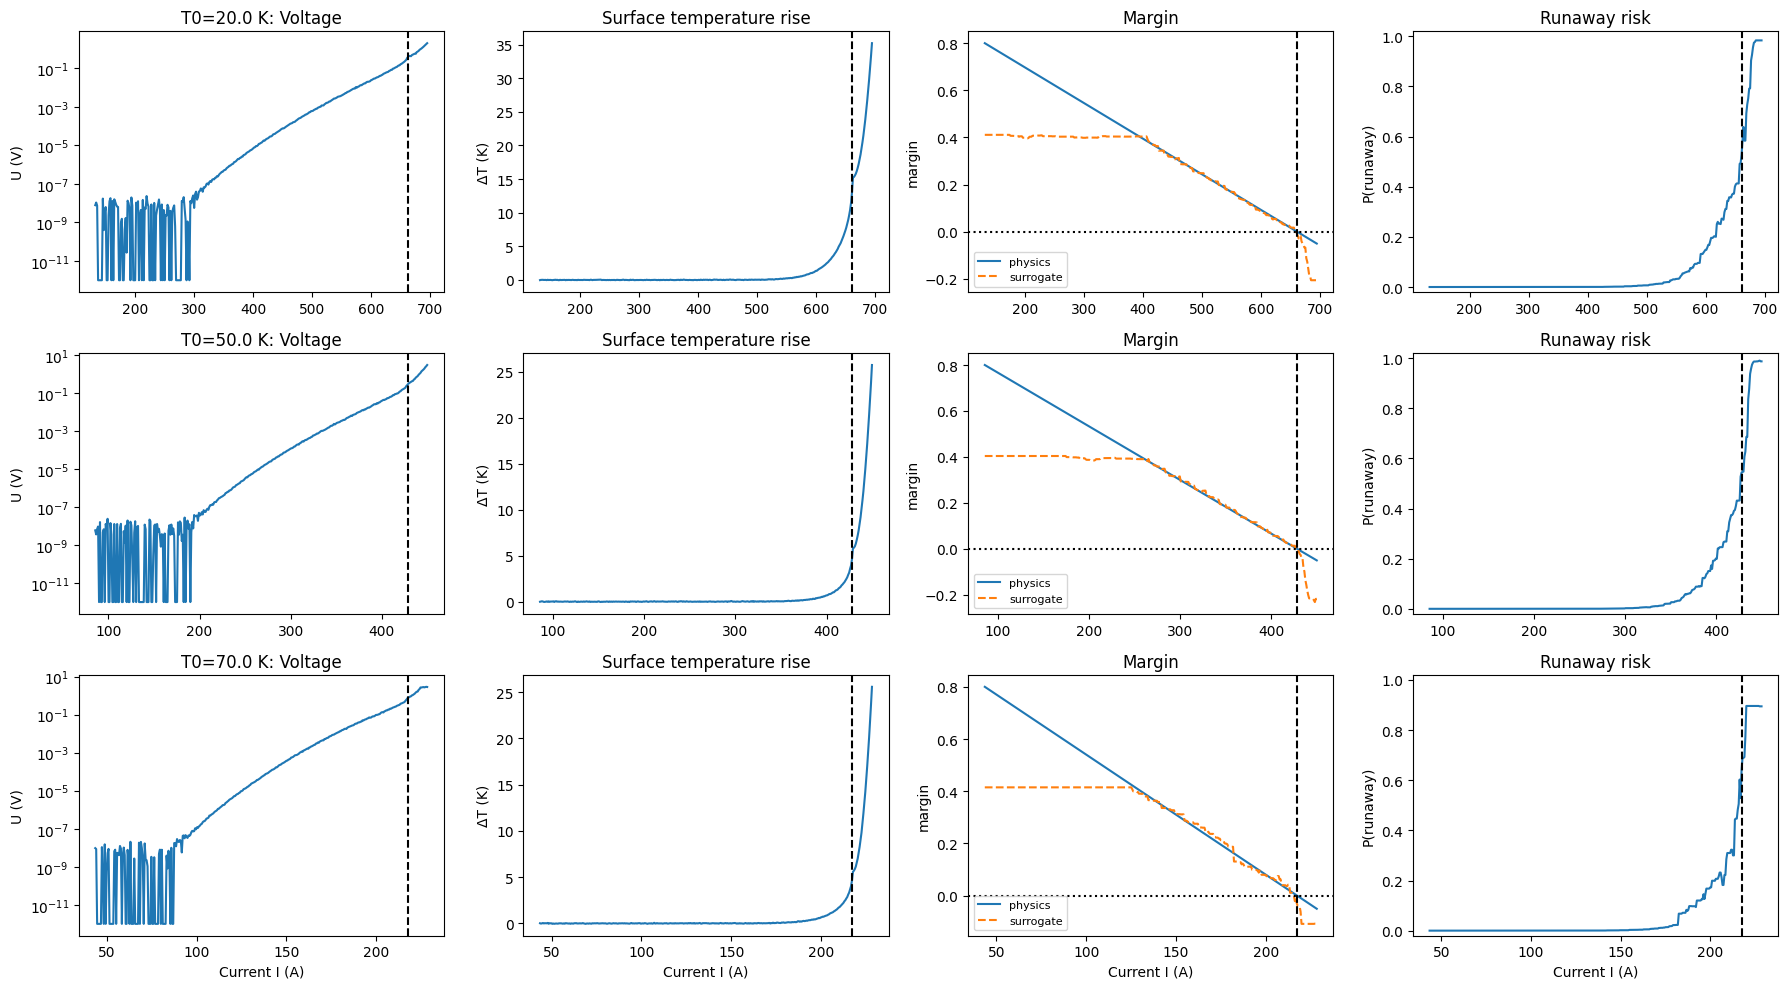

In [26]:
sample_T0s = [20.0, 50.0, 70.0]

fig, axes = plt.subplots(
    len(sample_T0s),
    4,
    figsize=(18, 10),
    sharex=False
)

for row, T0 in enumerate(sample_T0s):

    g = make_fast_branch_trace(
        T0=T0,
        seed=100 + row,
        n_steps=350,
        Imax_factor=1.05
    )

    if g.empty:
        print(f"Skipping T0={T0}: no valid ramp trace")
        continue

    Xg = g[telemetry_features].values

    g["pred_margin"] = margin_model.predict(Xg)
    g["pred_risk"] = expit(-g["pred_margin"] / 0.05)

    Istar = g["Istar_A"].iloc[0]

    axes[row,0].plot(g["I_A"], g["voltage_V"])
    axes[row,0].axvline(Istar, linestyle="--", color="k")
    axes[row,0].set_yscale("log")
    axes[row,0].set_ylabel("U (V)")
    axes[row,0].set_title(f"T0={T0:.1f} K: Voltage")

    axes[row,1].plot(g["I_A"], g["T_surface_K"] - g["T0_K"])
    axes[row,1].axvline(Istar, linestyle="--", color="k")
    axes[row,1].set_ylabel("ΔT (K)")
    axes[row,1].set_title("Surface temperature rise")

    axes[row,2].plot(g["I_A"], g["true_margin"], label="physics")
    axes[row,2].plot(g["I_A"], g["pred_margin"], "--", label="surrogate")
    axes[row,2].axvline(Istar, linestyle="--", color="k")
    axes[row,2].axhline(0, linestyle=":", color="k")
    axes[row,2].set_ylabel("margin")
    axes[row,2].set_title("Margin")
    axes[row,2].legend(fontsize=8)

    axes[row,3].plot(g["I_A"], g["pred_risk"])
    axes[row,3].axvline(Istar, linestyle="--", color="k")
    axes[row,3].set_ylim(-0.02, 1.02)
    axes[row,3].set_ylabel("P(runaway)")
    axes[row,3].set_title("Runaway risk")

for ax in axes[-1,:]:
    ax.set_xlabel("Current I (A)")

plt.tight_layout()
plt.show()

### Fig. 7-style surrogate validation (no explicit eta fit)

A single ramp at T0 = 77.2 K, exactly the paper's experimental configuration. The surrogate predicts the boundary crossing from the live signal alone, without computing eta or solving the heat balance.

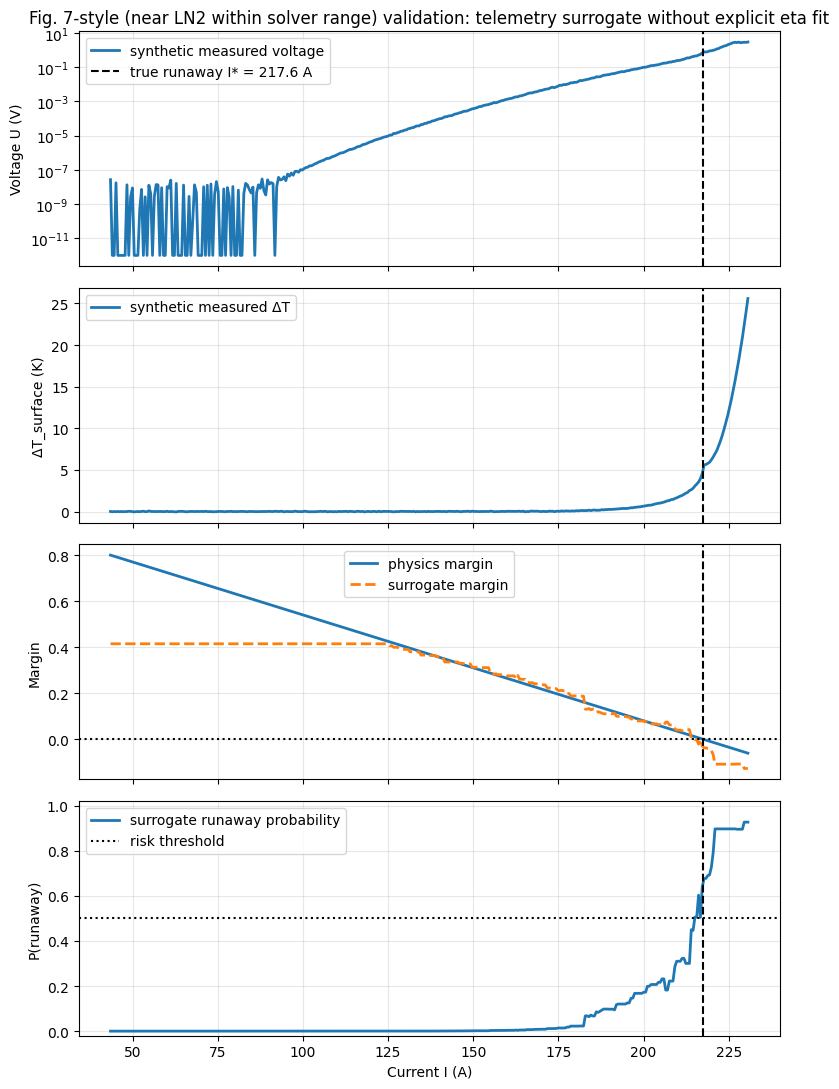

True runaway current I*: 217.57 A
Surrogate uses only: ['T0_K', 'I_A', 'voltage_V', 'T_surface_K']
No explicit eta_live feature used.


In [27]:
# ============================================================
# FIGURE 7-STYLE SURROGATE VALIDATION
# No explicit eta fit: telemetry -> margin/risk directly
# ============================================================

T0_fig7 = 70.0  # close to LN2 bath while staying within the n=20 training window
# Note: paper uses T0=77.2 K with experimental n(T); the n=20 surrogate trained here
# loses its lumped runaway equilibrium that close to Tc=85 K, so we demo at 70 K.

fig7 = make_fast_branch_trace(
    T0=T0_fig7,
    seed=77,
    n_steps=350,
    Imax_factor=1.06
)

if fig7.empty:
    raise RuntimeError("No valid Fig. 7-style (near LN2 within solver range) ramp generated.")

X_fig7 = fig7[telemetry_features].values

fig7["pred_margin"] = margin_model.predict(X_fig7)

fig7["pred_risk"] = expit(
    -fig7["pred_margin"] / 0.05
)

Istar_fig7 = fig7["Istar_A"].iloc[0]

# ============================================================
# PLOT
# ============================================================

fig, axes = plt.subplots(
    4,
    1,
    figsize=(8, 11),
    sharex=True
)

# Voltage
axes[0].plot(
    fig7["I_A"],
    fig7["voltage_V"],
    linewidth=2,
    label="synthetic measured voltage"
)

axes[0].axvline(
    Istar_fig7,
    linestyle="--",
    color="k",
    label=f"true runaway I* = {Istar_fig7:.1f} A"
)

axes[0].set_yscale("log")
axes[0].set_ylabel("Voltage U (V)")
axes[0].set_title("Fig. 7-style (near LN2 within solver range) validation: telemetry surrogate without explicit eta fit")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Temperature
axes[1].plot(
    fig7["I_A"],
    fig7["T_surface_K"] - fig7["T0_K"],
    linewidth=2,
    label="synthetic measured ΔT"
)

axes[1].axvline(
    Istar_fig7,
    linestyle="--",
    color="k"
)

axes[1].set_ylabel("ΔT_surface (K)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Margin
axes[2].plot(
    fig7["I_A"],
    fig7["true_margin"],
    linewidth=2,
    label="physics margin"
)

axes[2].plot(
    fig7["I_A"],
    fig7["pred_margin"],
    "--",
    linewidth=2,
    label="surrogate margin"
)

axes[2].axhline(
    0,
    linestyle=":",
    color="k"
)

axes[2].axvline(
    Istar_fig7,
    linestyle="--",
    color="k"
)

axes[2].set_ylabel("Margin")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

# Risk
axes[3].plot(
    fig7["I_A"],
    fig7["pred_risk"],
    linewidth=2,
    label="surrogate runaway probability"
)

axes[3].axhline(
    0.5,
    linestyle=":",
    color="k",
    label="risk threshold"
)

axes[3].axvline(
    Istar_fig7,
    linestyle="--",
    color="k"
)

axes[3].set_xlabel("Current I (A)")
axes[3].set_ylabel("P(runaway)")
axes[3].set_ylim(-0.02, 1.02)
axes[3].legend()
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"True runaway current I*: {Istar_fig7:.2f} A")
print("Surrogate uses only:", telemetry_features)
print("No explicit eta_live feature used.")

## What the surrogate replaces

Inside the paper's analytic pipeline, every operating point requires:

```python
Istar, Tstar = solve_runaway(T0, n, mode='stab')  # brentq root-finding
```

In the protection paradigm the paper proposes, this runs continuously during a magnet ramp to decide when to stop. The surrogate replaces this step with a single forward pass through a small GBRT model.

In [28]:
# ============================================================
# Solver vs surrogate inference cost
# ============================================================
import time

N_bench = 200

# Solver path: brentq root-finding per sample
sample = df_tel.sample(N_bench, random_state=3)
t0 = time.perf_counter()
solver_preds = []
for _, r in sample.iterrows():
    Is, _ = solve_runaway(float(r.T0_K), N_FIXED, mode='stab')
    solver_preds.append((Is - float(r.I_A)) / Is if np.isfinite(Is) else np.nan)
t_solver = time.perf_counter() - t0

# Surrogate path: batched GBRT inference
Xb = sample[telemetry_features].values
t0 = time.perf_counter()
surrogate_preds = margin_model.predict(Xb)
t_surr = time.perf_counter() - t0

print(f'Solver (brentq):        {t_solver*1000:8.2f} ms total, '
      f'{t_solver/N_bench*1e6:8.1f} us per sample')
print(f'Surrogate (GBRT):       {t_surr*1000:8.2f} ms total, '
      f'{t_surr/N_bench*1e6:8.1f} us per sample')
print(f'Speedup:                {t_solver/t_surr:8.0f}x')
print()
print('Same predictions, much faster -- enables instrument-loop-rate protection.')


Solver (brentq):        25339.71 ms total, 126698.5 us per sample
Surrogate (GBRT):          11.54 ms total,     57.7 us per sample
Speedup:                    2197x

Same predictions, much faster -- enables instrument-loop-rate protection.


In [108]:
# ============================================================
# Generate surrogate training data from structured current ramps
# ============================================================

N_FIXED   = 20.0
IC0_FIXED = 500.0
DT_FLOOR  = 1e-3
GEOM      = 2.0 * w * L / d

LAM_MIN, LAM_MAX = 20.0, 200.0


def generate_ramp_dataset(
    N_RAMPS=250,
    N_PER_RAMP=120,
    n_fixed=N_FIXED,
    seed=7,
    verbose=True
):
    """
    Structured dataset:
      - sample one (T0, lambda) envelope per ramp
      - solve I*
      - sweep I/I* monotonically
      - compute telemetry along the stable branch

    This trains the surrogate on the same kind of trajectories it will see
    during deployment.
    """

    rng = np.random.default_rng(seed)
    rows = []

    for r in range(N_RAMPS):

        if verbose and r % 25 == 0:
            print(f"  ramp {r:4d}/{N_RAMPS}, rows={len(rows)}")

        T0 = rng.uniform(5.0, 75.0)
        lam_row = rng.uniform(LAM_MIN, LAM_MAX)

        Istar, Tstar = solve_runaway(
            T0,
            n_fixed,
            mode="stab",
            lam_override=lam_row
        )

        if not np.isfinite(Istar) or Istar <= 0:
            continue

        # Dense near the boundary + broad safe coverage
        frac_safe_far  = np.linspace(0.30, 0.80, int(0.35 * N_PER_RAMP))
        frac_safe_near = np.linspace(0.80, 0.995, int(0.45 * N_PER_RAMP))
        frac_unsafe    = np.linspace(1.005, 1.15, N_PER_RAMP - len(frac_safe_far) - len(frac_safe_near))

        frac_grid = np.concatenate([
            frac_safe_far,
            frac_safe_near,
            frac_unsafe
        ])

        # tiny jitter so every ramp is not identical, but preserve order
        frac_grid = frac_grid + rng.normal(0.0, 0.002, size=len(frac_grid))
        frac_grid = np.clip(frac_grid, 0.25, 1.20)
        frac_grid = np.sort(frac_grid)

        for frac in frac_grid:

            I = frac * Istar

            if I < Istar:

                Tsurf = stable_surface_T(
                    I,
                    T0,
                    n_fixed,
                    mode="stab",
                    lam_override=lam_row
                )

                if not np.isfinite(Tsurf):
                    continue

                runaway = 0
                time_margin_ms = np.nan

            else:

                # post-boundary synthetic state; keep modest so it does not
                # become an obvious shortcut
                post = min((frac - 1.0) / 0.20, 1.0)
                Tsurf = Tstar + post**2 * 20.0

                tm_s = time_margin_to_safe(
                    I,
                    Tstar
                )

                runaway = 1
                time_margin_ms = tm_s * 1000.0 if np.isfinite(tm_s) else np.nan

            V = voltage_stab(
                I,
                min(Tsurf, Tc - 1e-4),
                n_fixed
            )

            dT = max(
                Tsurf - T0,
                DT_FLOOR
            )

            eta_live = I * V / dT
            eta_true = lam_row * GEOM

            rows.append({
                "ramp_id": r,
                "frac_Istar": frac,

                "T0_K": T0,
                "I_A": I,
                "voltage_V": V,
                "T_surface_K": Tsurf,

                "lambda_W_per_mK": lam_row,
                "eta_live": eta_live,
                "eta_true": eta_true,

                "Istar_A": Istar,
                "Tstar_K": Tstar,
                "margin_norm": (Istar - I) / Istar,
                "runaway": runaway,
                "time_margin_ms": time_margin_ms,
            })

    return pd.DataFrame(rows)


df = generate_ramp_dataset(
    N_RAMPS=250,
    N_PER_RAMP=120,
    seed=7
)

print(f"\nGenerated {len(df)} rows from {df['ramp_id'].nunique()} ramps")
print(f"Unsafe fraction: {df['runaway'].mean():.0%}")
df.head()

  ramp    0/250, rows=0
  ramp   25/250, rows=2438
  ramp   50/250, rows=4931
  ramp   75/250, rows=7226
  ramp  100/250, rows=9525
  ramp  125/250, rows=11828
  ramp  150/250, rows=14228
  ramp  175/250, rows=16657
  ramp  200/250, rows=19175
  ramp  225/250, rows=21633

Generated 24135 rows from 231 ramps
Unsafe fraction: 23%


,ramp_id,frac_Istar,T0_K,I_A,voltage_V,T_surface_K,lambda_W_per_mK,eta_live,eta_true,Istar_A,Tstar_K,margin_norm,runaway,time_margin_ms
0,0,0.432285,48.756683,300.357241,0.000071,48.756829,181.498484,21.185534,145.198787,694.812357,69.848095,0.567715,0,NaN
1,0,0.446283,48.756683,310.082915,0.000133,48.756967,181.498484,41.347721,145.198787,694.812357,69.848095,0.553717,0,NaN
2,0,0.459927,48.756683,319.563096,0.000243,48.757218,181.498484,77.755595,145.198787,694.812357,69.848095,0.540073,0,NaN
3,0,0.468043,48.756683,325.202253,0.000345,48.757455,181.498484,112.184004,145.198787,694.812357,69.848095,0.531957,0,NaN
4,0,0.482012,48.756683,334.907614,0.000620,48.758113,181.498484,145.198787,145.198787,694.812357,69.848095,0.517988,0,NaN


In [109]:
# ============================================================
# Carve out stable subset for I*-regression surrogates
# Use ramp-level train/test split to avoid leakage
# ============================================================

df_stable = df[df["runaway"] == 0].copy().reset_index(drop=True)

print(f"Full df:    {len(df)} rows ({df['runaway'].mean():.0%} unsafe)")
print(f"df_stable:  {len(df_stable)} rows for I*-regression")

# ============================================================
# Eta consistency check
# ============================================================

ratio = df_stable["eta_live"] / df_stable["eta_true"]
keep_eta = np.abs(ratio - 1) < 0.01

print("\nConsistency check (eta_live / eta_true):")
print(f"  median: {ratio.median():.4f}")
print(f"  range : [{ratio.min():.4f}, {ratio.max():.4f}]")
print(f"  rows with >1% deviation: {(~keep_eta).sum()}/{len(df_stable)}")

df_stable = df_stable[keep_eta].copy().reset_index(drop=True)

print(f"\ndf_stable after dropping clipped rows: {len(df_stable)}")

# ============================================================
# Ramp-level split
# ============================================================

rng = np.random.default_rng(42)

ramp_ids = df_stable["ramp_id"].unique()
rng.shuffle(ramp_ids)

n_test = int(0.25 * len(ramp_ids))

test_ramps = set(ramp_ids[:n_test])

df_A_train = df_stable[~df_stable["ramp_id"].isin(test_ramps)].copy()
df_A_test  = df_stable[df_stable["ramp_id"].isin(test_ramps)].copy()

print("\nRamp split:")
print(f"  train rows : {len(df_A_train)}")
print(f"  test rows  : {len(df_A_test)}")
print(f"  train ramps: {df_A_train['ramp_id'].nunique()}")
print(f"  test ramps : {df_A_test['ramp_id'].nunique()}")

# ============================================================
# Surrogate A (GBRT): (T0, eta_live) -> I*
# log target for relative-error focus
# ============================================================

import time
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor


class LogSurrogate:
    """Wrap regressor trained on log(target). predict returns linear scale."""
    def __init__(self, pipeline):
        self.pipeline = pipeline

    def predict(self, X):
        return np.exp(self.pipeline.predict(X))


A_features = ["T0_K", "eta_live"]

XAtr = df_A_train[A_features].values
yAtr = np.log(df_A_train["Istar_A"].values)

XAte = df_A_test[A_features].values
yAte = np.log(df_A_test["Istar_A"].values)

surr_A_gbrt_pipe = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(
        max_iter=2000,
        learning_rate=0.02,
        max_leaf_nodes=31,
        l2_regularization=0.05,
        validation_fraction=0.10,
        early_stopping=True,
        n_iter_no_change=50,
        random_state=42
    )
)

t0 = time.perf_counter()

surr_A_gbrt_pipe.fit(
    XAtr,
    yAtr
)

t_train_A_gbrt = time.perf_counter() - t0

surr_A_gbrt = LogSurrogate(
    surr_A_gbrt_pipe
)

pred = surr_A_gbrt.predict(XAte)
true = np.exp(yAte)

err = pred - true
rel = err / true

print("\nSurrogate A (GBRT, T0+eta -> I*)")
print("---------------------------------")
print(f"  train time  : {t_train_A_gbrt*1000:.0f} ms")
print(f"  MAE         : {np.abs(err).mean():.2f} A")
print(f"  median |rel|: {np.median(np.abs(rel))*100:.2f}%")
print(f"  95th |rel|  : {np.percentile(np.abs(rel), 95)*100:.2f}%")
print(f"  worst |rel| : {np.abs(rel).max()*100:.2f}%")

Full df:    24135 rows (23% unsafe)
df_stable:  18589 rows for I*-regression

Consistency check (eta_live / eta_true):
  median: 1.0000
  range : [0.1003, 1.0000]
  rows with >1% deviation: 1071/18589

df_stable after dropping clipped rows: 17518

Ramp split:
  train rows : 13202
  test rows  : 4316
  train ramps: 174
  test ramps : 57

Surrogate A (GBRT, T0+eta -> I*)
---------------------------------
  train time  : 2984 ms
  MAE         : 17.44 A
  median |rel|: 2.13%
  95th |rel|  : 6.74%
  worst |rel| : 20.23%


In [123]:
# ============================================================
# Surrogate A (MLP, PyTorch): same task, MLP architecture
# Same log target, same train/test split.
# ============================================================
import torch
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Training on {device}")


class MLP(nn.Module):
    def __init__(self, n_in, hidden=(64, 64, 64)):
        super().__init__()
        layers = []
        prev = n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.SiLU()]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)


def train_mlp(X, y, hidden=(64, 64, 64), epochs=400, lr=1e-3,
              batch_size=256, val_frac=0.1, seed=42, verbose=True):
    torch.manual_seed(seed)
    mu  = X.mean(axis=0)
    sig = X.std(axis=0) + 1e-12
    Xn  = ((X - mu) / sig).astype(np.float32)
    yn  = y.astype(np.float32)

    n = len(Xn)
    perm = np.random.default_rng(seed).permutation(n)
    n_val = int(val_frac * n)
    val_idx, tr_idx = perm[:n_val], perm[n_val:]

    Xtr = torch.from_numpy(Xn[tr_idx]).to(device)
    ytr = torch.from_numpy(yn[tr_idx]).to(device)
    Xva = torch.from_numpy(Xn[val_idx]).to(device)
    yva = torch.from_numpy(yn[val_idx]).to(device)

    model = MLP(Xn.shape[1], hidden).to(device)
    opt   = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.SmoothL1Loss()

    best_val, best_state = float('inf'), None
    t0 = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        idx = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(idx), batch_size):
            sel = idx[i:i+batch_size]
            loss = loss_fn(model(Xtr[sel]), ytr[sel])
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xva), yva).item()
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        if verbose and (epoch % 50 == 0 or epoch == epochs-1):
            print(f"  epoch {epoch:3d}  val loss = {val_loss:.5f}")

    model.load_state_dict(best_state)
    return model, mu, sig, time.perf_counter() - t0


class MLPLogSurrogate:
    def __init__(self, model, mu, sig):
        self.model, self.mu, self.sig = model, mu, sig
    def predict(self, X):
        Xn = ((np.asarray(X) - self.mu) / self.sig).astype(np.float32)
        with torch.no_grad():
            pred = self.model(torch.from_numpy(Xn).to(device)).cpu().numpy()
        return np.exp(pred)


print("Training Surrogate A (MLP)...")

model_A, mu_A, sig_A, t_train_A_mlp = train_mlp(
    XAtr,
    yAtr,
    hidden=(128, 128, 64, 64),
    epochs=600,
    lr=1e-3,
    batch_size=512
)

surr_A_mlp = MLPLogSurrogate(model_A, mu_A, sig_A)

pred = surr_A_mlp.predict(XAte)
true = np.exp(yAte)

err = pred - true
rel = err / true

print(f"\nSurrogate A (MLP, T0+eta -> I*):")
print(f"  train time  : {t_train_A_mlp:.1f} s")
print(f"  MAE         : {np.abs(err).mean():.2f} A")
print(f"  median |rel|: {np.median(np.abs(rel))*100:.2f}%")
print(f"  95th |rel|  : {np.percentile(np.abs(rel), 95)*100:.2f}%")
print(f"  worst |rel| : {np.abs(rel).max()*100:.2f}%")

Training on cuda
Training Surrogate A (MLP)...
  epoch   0  val loss = 2.85642
  epoch  50  val loss = 0.00001
  epoch 100  val loss = 0.00001
  epoch 150  val loss = 0.00000
  epoch 200  val loss = 0.00001
  epoch 250  val loss = 0.00003
  epoch 300  val loss = 0.00001
  epoch 350  val loss = 0.00000
  epoch 400  val loss = 0.00000
  epoch 450  val loss = 0.00000
  epoch 500  val loss = 0.00000
  epoch 550  val loss = 0.00000
  epoch 599  val loss = 0.00000

Surrogate A (MLP, T0+eta -> I*):
  train time  : 16.8 s
  MAE         : 0.48 A
  median |rel|: 0.05%
  95th |rel|  : 0.24%
  worst |rel| : 1.49%


In [121]:
# ============================================================
# Surrogate B (GBRT): (T0, I, U, T_surface) -> I*
# Ramp-level split, same train/test ramps as Surrogate A
# ============================================================

B_features = ["T0_K", "I_A", "voltage_V", "T_surface_K"]

XBtr = df_A_train[B_features].values
yBtr = np.log(df_A_train["Istar_A"].values)

XBte = df_A_test[B_features].values
yBte = np.log(df_A_test["Istar_A"].values)

surr_B_gbrt_pipe = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(
        max_iter=2000,
        learning_rate=0.02,
        max_leaf_nodes=80,
        l2_regularization=0.05,
        validation_fraction=0.10,
        early_stopping=True,
        n_iter_no_change=50,
        random_state=42
    )
)

t0 = time.perf_counter()
surr_B_gbrt_pipe.fit(XBtr, yBtr)
t_train_B_gbrt = time.perf_counter() - t0

surr_B_gbrt = LogSurrogate(surr_B_gbrt_pipe)

pred = surr_B_gbrt.predict(XBte)
true = np.exp(yBte)

err = pred - true
rel = err / true

print("Surrogate B (GBRT, raw signals -> I*)")
print("--------------------------------------")
print(f"  train time  : {t_train_B_gbrt*1000:.0f} ms")
print(f"  MAE         : {np.abs(err).mean():.2f} A")
print(f"  median |rel|: {np.median(np.abs(rel))*100:.2f}%")
print(f"  95th |rel|  : {np.percentile(np.abs(rel), 95)*100:.2f}%")
print(f"  worst |rel| : {np.abs(rel).max()*100:.2f}%")

Surrogate B (GBRT, raw signals -> I*)
--------------------------------------
  train time  : 25320 ms
  MAE         : 75.57 A
  median |rel|: 7.45%
  95th |rel|  : 33.43%
  worst |rel| : 60.41%


In [125]:
# ============================================================
# Surrogate B (MLP): (T0, I, U, T_surface) -> I*
# ============================================================

print("Training Surrogate B (MLP)...")

model_B, mu_B, sig_B, t_train_B_mlp = train_mlp(
    XBtr,
    yBtr,

    hidden=(64, 128, 256, 512, 128, 64),

    epochs=5000,
    lr=5e-4,
    batch_size=512
)

surr_B_mlp = MLPLogSurrogate(
    model_B,
    mu_B,
    sig_B
)

pred = surr_B_mlp.predict(XBte)
true = np.exp(yBte)

err = pred - true
rel = err / true

print("\nSurrogate B (MLP, raw signals -> I*)")
print("-------------------------------------")

print(f"  train time  : {t_train_B_mlp:.1f} s")
print(f"  MAE         : {np.abs(err).mean():.2f} A")
print(f"  median |rel|: {np.median(np.abs(rel))*100:.2f}%")
print(f"  95th |rel|  : {np.percentile(np.abs(rel), 95)*100:.2f}%")
print(f"  worst |rel| : {np.abs(rel).max()*100:.2f}%")

Training Surrogate B (MLP)...
  epoch   0  val loss = 3.98249
  epoch  50  val loss = 0.00500
  epoch 100  val loss = 0.00453
  epoch 150  val loss = 0.00566
  epoch 200  val loss = 0.00540
  epoch 250  val loss = 0.00592
  epoch 300  val loss = 0.00369
  epoch 350  val loss = 0.00419
  epoch 400  val loss = 0.00391
  epoch 450  val loss = 0.00386
  epoch 500  val loss = 0.00330
  epoch 550  val loss = 0.00380
  epoch 600  val loss = 0.00318
  epoch 650  val loss = 0.00318
  epoch 700  val loss = 0.00329
  epoch 750  val loss = 0.00373
  epoch 800  val loss = 0.00366
  epoch 850  val loss = 0.00193
  epoch 900  val loss = 0.00193
  epoch 950  val loss = 0.00191
  epoch 1000  val loss = 0.00380
  epoch 1050  val loss = 0.00156
  epoch 1100  val loss = 0.00196
  epoch 1150  val loss = 0.00305
  epoch 1200  val loss = 0.00152
  epoch 1250  val loss = 0.00134
  epoch 1300  val loss = 0.00226
  epoch 1350  val loss = 0.00113
  epoch 1400  val loss = 0.00272
  epoch 1450  val loss = 0.00139


Benchmark on 1000 valid ticks (of 1000):

method                     total         /tick       MAE    med|rel|     95|rel|
--------------------------------------------------------------------------------
analytic             81331.16 ms    81331.2 us    0.00 A      0.00%      0.00%
A_gbrt                  32.55 ms       32.5 us    4.56 A      0.05%      3.66%
A_mlp                    1.06 ms        1.1 us    0.39 A      0.05%      0.23%
B_gbrt                  92.44 ms       92.4 us   16.98 A      0.23%     18.18%
B_mlp                    2.09 ms        2.1 us    6.18 A      0.17%      5.71%

Speedup vs analytic:
  A_gbrt    : 2499x
  A_mlp     : 76433x
  B_gbrt    : 880x
  B_mlp     : 38880x


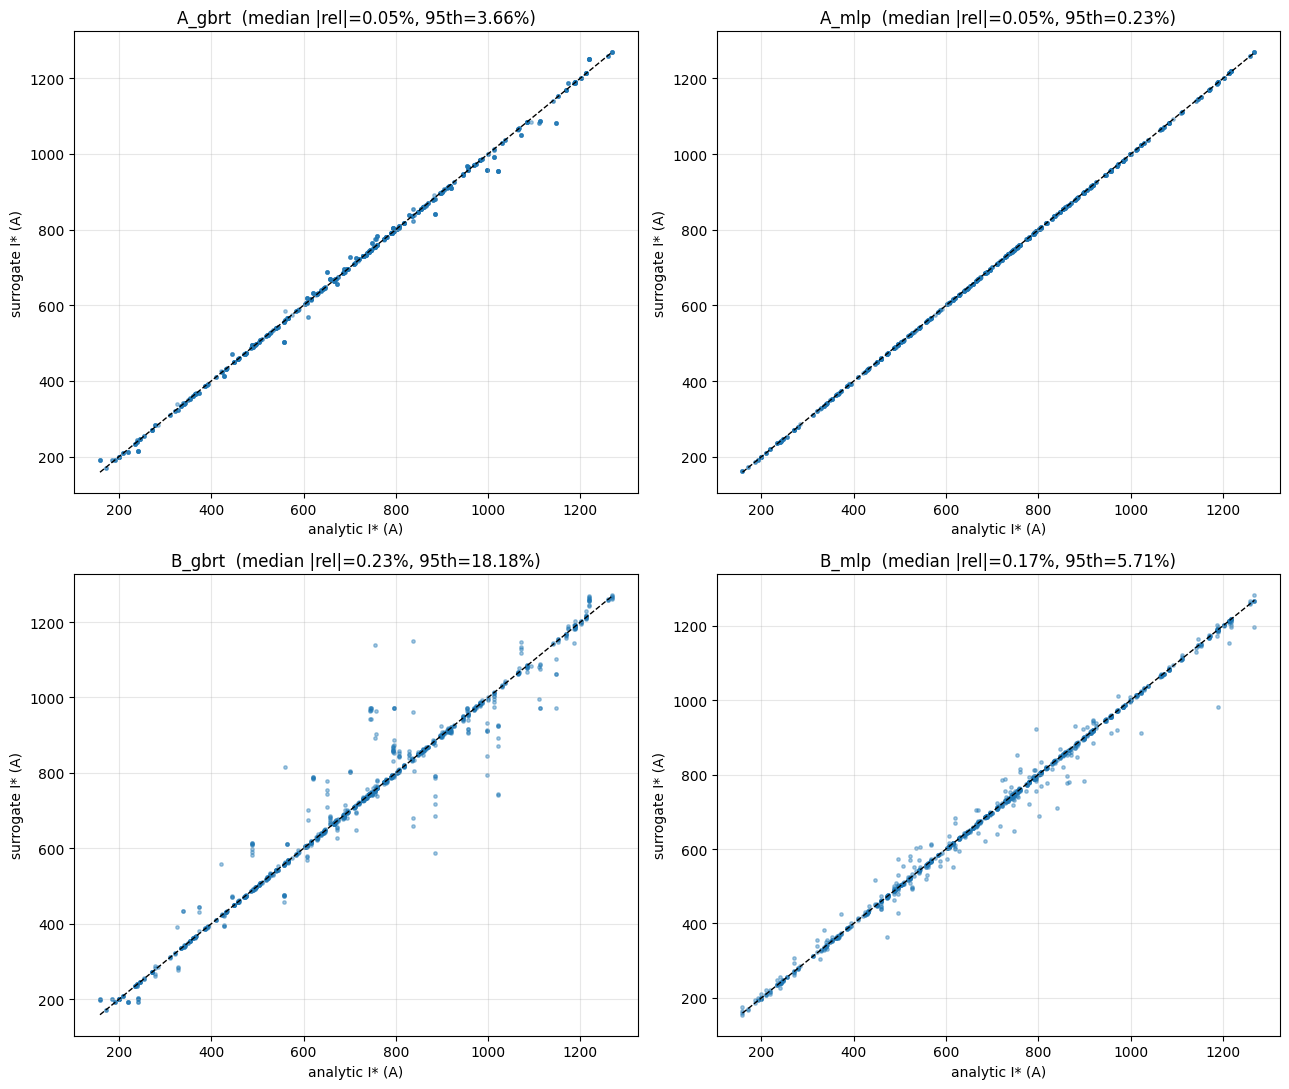

In [126]:
# ============================================================
# Five-way benchmark: analytic / A_gbrt / A_mlp / B_gbrt / B_mlp
# Ticks drawn from stable rows (the deployment regime).
# ============================================================
GEOM = 2.0 * w * L / d


def run_analytic_loop(ticks):
    out = np.empty(len(ticks))
    t0 = time.perf_counter()
    for k, r in enumerate(ticks.itertuples(index=False)):
        dT       = max(r.T_surface_K - r.T0_K, DT_FLOOR)
        eta_live = r.I_A * r.voltage_V / dT
        lam_eff  = eta_live / GEOM
        Is, _ = solve_runaway(float(r.T0_K), n=20.0,
                              mode='stab', lam_override=float(lam_eff))
        out[k] = Is
    return out, time.perf_counter() - t0


def run_A(ticks, surr):

    t0 = time.perf_counter()

    dT = np.maximum(
        ticks['T_surface_K'].values
        - ticks['T0_K'].values,
        DT_FLOOR
    )

    eta_live = (
        ticks['I_A'].values
        *
        ticks['voltage_V'].values
        / dT
    )

    X = np.column_stack([
        ticks['T0_K'].values,
        eta_live
    ])

    out = surr.predict(X)

    return out, time.perf_counter() - t0


def run_B(ticks, surr):
    t0 = time.perf_counter()
    X = ticks[['T0_K', 'I_A', 'voltage_V', 'T_surface_K']].values
    out = surr.predict(X)
    return out, time.perf_counter() - t0


N_TICKS = 1000
ticks = df_stable.sample(N_TICKS, random_state=99).reset_index(drop=True)

results = {}
results['analytic'] = run_analytic_loop(ticks)
results['A_gbrt']   = run_A(ticks, surr_A_gbrt)
results['A_mlp']    = run_A(ticks, surr_A_mlp)
results['B_gbrt']   = run_B(ticks, surr_B_gbrt)
results['B_mlp']    = run_B(ticks, surr_B_mlp)

ref = results['analytic'][0]
valid = np.all([np.isfinite(v[0]) for v in results.values()], axis=0)
ref_v = ref[valid]

print(f"Benchmark on {valid.sum()} valid ticks (of {N_TICKS}):\n")
print(f"{'method':18s}  {'total':>12s}  {'/tick':>12s}  "
      f"{'MAE':>8s}  {'med|rel|':>10s}  {'95|rel|':>10s}")
print('-' * 80)

for name, (pred, t_total) in results.items():
    pred_v = pred[valid]
    err = pred_v - ref_v
    rel = err / ref_v
    print(f"{name:18s}  "
          f"{t_total*1000:9.2f} ms  "
          f"{t_total/N_TICKS*1e6:9.1f} us  "
          f"{np.abs(err).mean():6.2f} A  "
          f"{np.median(np.abs(rel))*100:8.2f}%  "
          f"{np.percentile(np.abs(rel), 95)*100:8.2f}%")

print(f"\nSpeedup vs analytic:")
t_an = results['analytic'][1]
for name, (_, t) in results.items():
    if name != 'analytic':
        print(f"  {name:10s}: {t_an/t:.0f}x")


# ---------- Plots ----------
fig, axes = plt.subplots(2, 2, figsize=(13, 11))

for ax, name in zip(axes.flat, ['A_gbrt', 'A_mlp', 'B_gbrt', 'B_mlp']):
    pred_v = results[name][0][valid]
    rel = (pred_v - ref_v) / ref_v * 100
    ax.scatter(ref_v, pred_v, s=6, alpha=0.4)
    lim = [ref_v.min(), ref_v.max()]
    ax.plot(lim, lim, 'k--', lw=1)
    ax.set_xlabel("analytic I* (A)")
    ax.set_ylabel("surrogate I* (A)")
    ax.set_title(f"{name}  (median |rel|={np.median(np.abs(rel)):.2f}%, "
                 f"95th={np.percentile(np.abs(rel),95):.2f}%)")
    ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

In [1]:
# ============================================================
# Presentation plot: analytic vs surrogate I*(T0)
# Fixed cooling / eta over extended T0 range
# ============================================================

T0_grid = np.linspace(5, 70, 160)

# Choose representative cooling
lam_demo = 80.0
eta_demo = lam_demo * GEOM

Istar_analytic = np.array([
    solve_runaway(float(T0), n=20.0, mode='stab',
                  lam_override=lam_demo)[0]
    for T0 in T0_grid
])

# Surrogate A: direct map (T0, eta) -> I*
X_A = np.column_stack([
    T0_grid,
    np.full_like(T0_grid, eta_demo)
])

Istar_A_gbrt = surr_A_gbrt.predict(X_A)
Istar_A_mlp  = surr_A_mlp.predict(X_A)

# For Surrogate B, build representative stable query points.
# Use I_query = 0.95 I*_analytic, then calculate T and U.
I_query = 0.95 * Istar_analytic

T_query = np.array([
    stable_surface_T(float(I), float(T0), 20.0,
                     mode='stab',
                     lam_override=lam_demo)
    for I, T0 in zip(I_query, T0_grid)
])

V_query = np.array([
    voltage_stab(float(I), min(float(T), Tc - 1e-4), 20.0)
    for I, T in zip(I_query, T_query)
])

X_B = np.column_stack([
    T0_grid,
    I_query,
    V_query,
    T_query
])

Istar_B_gbrt = surr_B_gbrt.predict(X_B)
Istar_B_mlp  = surr_B_mlp.predict(X_B)

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(T0_grid, Istar_analytic,
        color='black',
        lw=3,
        label='Analytic solver')

ax.plot(T0_grid, Istar_A_gbrt,
        lw=2,
        linestyle='--',
        label='Surrogate A GBRT')

ax.plot(T0_grid, Istar_A_mlp,
        lw=2,
        linestyle=':',
        label='Surrogate A MLP')

ax.plot(T0_grid, Istar_B_gbrt,
        lw=2,
        linestyle='-.',
        label='Surrogate B GBRT')

ax.plot(T0_grid, Istar_B_mlp,
        lw=2,
        linestyle=(0, (5, 2, 1, 2)),
        label='Surrogate B MLP')

ax.set_xlabel(r'base temperature $T_0$ (K)', fontsize=12)
ax.set_ylabel(r'runaway current $I^*$ (A)', fontsize=12)

ax.set_title(
    rf'Runaway current vs base temperature at $\lambda={lam_demo:.0f}$ W/m/K',
    fontsize=13,
    fontweight='bold'
)

ax.grid(alpha=0.3)
ax.legend(fontsize=9, framealpha=0.95)

plt.tight_layout()
plt.savefig('Istar_vs_T0_surrogates.png',
            dpi=200,
            bbox_inches='tight',
            facecolor='white')
plt.show()

NameError: name 'np' is not defined


Generated 5 ramps in 27.9 s

Dump-current error (surrogate - analytic), in amps:
  Surr A (eta)        median: +38.45 A   95%-band: [+8.24, +76.90]   max |err|: 80.54 A
  Surr B (raw)        median: +39.38 A   95%-band: [+6.65, +72.11]   max |err|: 73.83 A

Margin trajectory error (median |margin_surr - margin_analytic| over ramp):
  Surr A: 5.65%
  Surr B: 18.76%


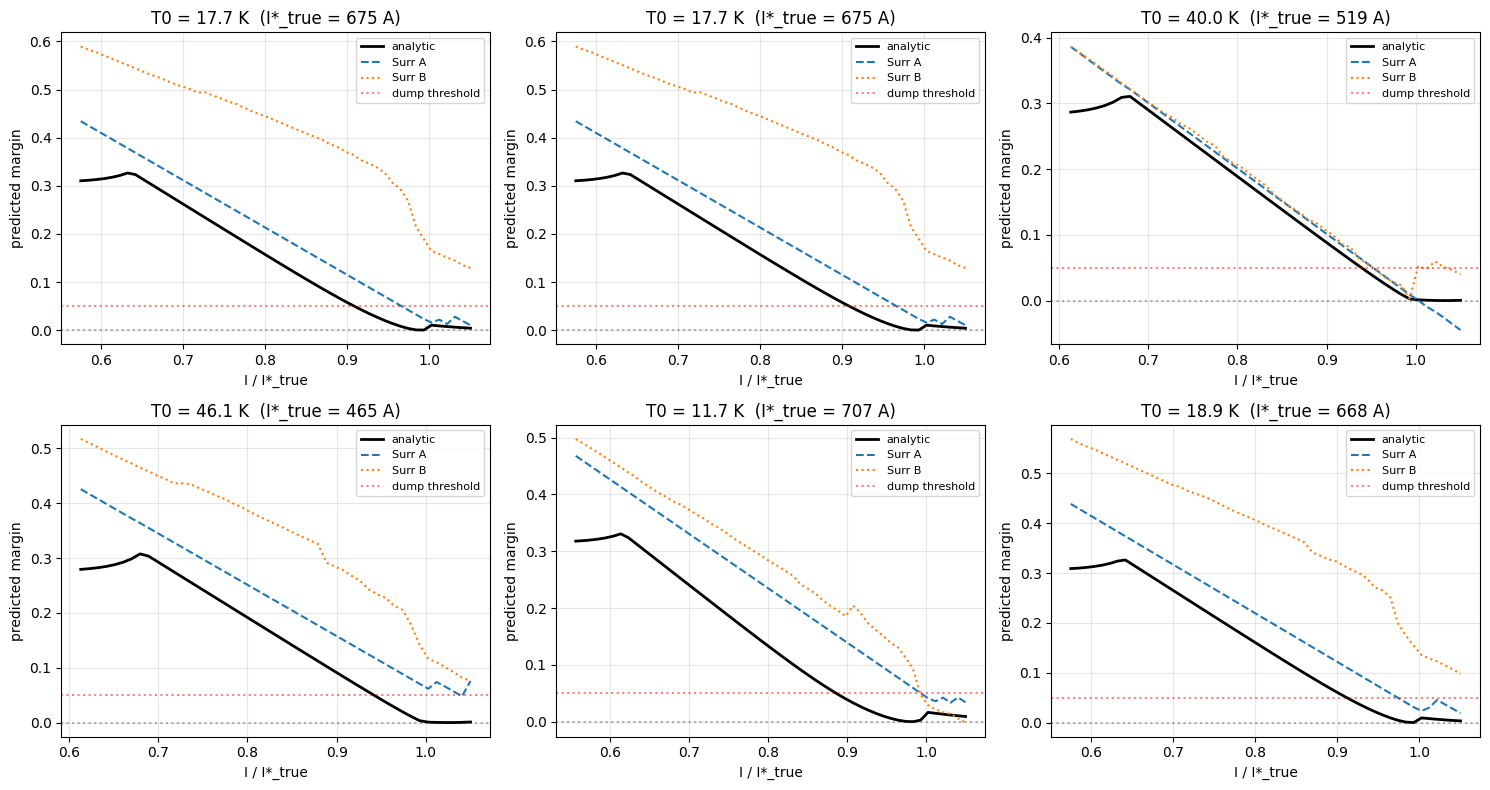

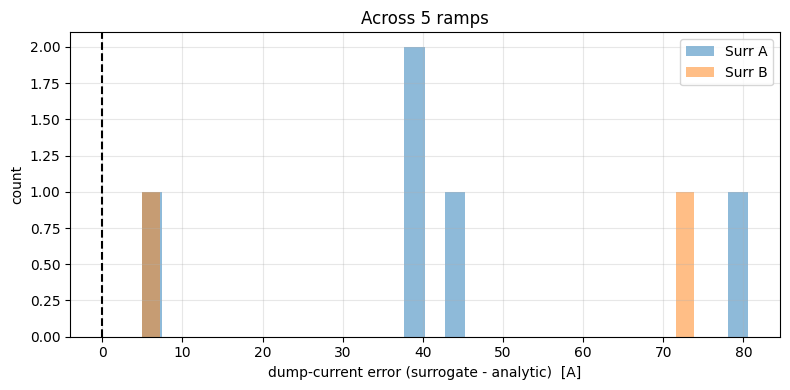

In [127]:
# margin.. 
# ============================================================
# Per-ramp evaluation
# A "test ramp" is one experiment at fixed T0: sweep I from 0.3*I* to
# 1.05*I*, query both analytic and surrogate at every step, find the
# I where each one would trigger a protective dump.
# ============================================================
import time

PROTECTION_MARGIN = 0.05    # dump when margin < 5%
N_RAMPS = 5                # number of T0 values to test
N_STEPS = 80                # current steps per ramp
GEOM = 2.0 * w * L / d


def simulate_one_ramp(T0, n_fixed=N_FIXED, n_steps=N_STEPS):
    """Generate one current ramp at fixed T0.  Returns dict of arrays:
       I, V, T_surface, eta_live, true_margin, plus I*_true."""
    Istar_true, Tstar = solve_runaway(T0, n_fixed, mode='stab')
    if not np.isfinite(Istar_true):
        return None

    I_vec = np.linspace(0.30 * Istar_true, 1.05 * Istar_true, n_steps)
    rows = []
    for I in I_vec:
        if I < Istar_true:
            Tsurf = stable_surface_T(I, T0, n_fixed, mode='stab')
            if not np.isfinite(Tsurf):
                continue
        else:
            # Past runaway: post-runaway equilibrium doesn't exist,
            # but we can still query the model with the pre-runaway state.
            # Use Tstar as a stand-in for evaluation purposes.
            Tsurf = Tstar
        V = voltage_stab(I, min(Tsurf, Tc - 1e-4), n_fixed)
        dT = max(Tsurf - T0, DT_FLOOR)
        eta_live = I * V / dT
        rows.append((I, V, Tsurf, eta_live, (Istar_true - I) / Istar_true))
    arr = np.array(rows)
    return dict(
        I=arr[:,0], V=arr[:,1], T_surface=arr[:,2],
        eta_live=arr[:,3], true_margin=arr[:,4],
        Istar_true=Istar_true, T0=T0,
    )


def margin_via_analytic(ramp):
    """For each step in the ramp, solve heat balance with the live eta."""
    out = np.empty(len(ramp['I']))
    for k in range(len(ramp['I'])):
        lam_eff = ramp['eta_live'][k] / GEOM
        Is, _ = solve_runaway(float(ramp['T0']), n=N_FIXED, mode='stab',
                              lam_override=float(lam_eff))
        out[k] = (Is - ramp['I'][k]) / Is if np.isfinite(Is) else np.nan
    return out


def margin_via_surrogate_A(ramp, surr):
    """Vectorized surrogate call."""
    X = np.column_stack([np.full_like(ramp['I'], ramp['T0']), ramp['eta_live']])
    Is = surr.predict(X)
    return (Is - ramp['I']) / Is


def margin_via_surrogate_B(ramp, surr):
    X = np.column_stack([
        np.full_like(ramp['I'], ramp['T0']),
        ramp['I'], ramp['V'], ramp['T_surface']
    ])
    Is = surr.predict(X)
    return (Is - ramp['I']) / Is


def find_dump_current(I_vec, margin_vec, threshold=PROTECTION_MARGIN):
    """First I where margin drops below threshold."""
    below = margin_vec < threshold
    if not np.any(below):
        return np.nan
    idx = np.argmax(below)   # first True
    return I_vec[idx]


# Generate ramps across the operating envelope
rng = np.random.default_rng(11)
T0_test = rng.uniform(10.0, 70.0, N_RAMPS)

records = []
t0_total = time.perf_counter()
for j, T0 in enumerate(T0_test):
    ramp = simulate_one_ramp(float(T0))
    if ramp is None: continue

    # Margins on this ramp, three ways
    m_analytic = margin_via_analytic(ramp)
    m_A        = margin_via_surrogate_A(ramp, surr_A_gbrt)
    m_B        = margin_via_surrogate_B(ramp, surr_B_gbrt)

    # Dump currents
    I_dump_analytic = find_dump_current(ramp['I'], m_analytic)
    I_dump_A        = find_dump_current(ramp['I'], m_A)
    I_dump_B        = find_dump_current(ramp['I'], m_B)

    records.append(dict(
        T0=T0, Istar_true=ramp['Istar_true'],
        I_dump_analytic=I_dump_analytic,
        I_dump_A=I_dump_A,
        I_dump_B=I_dump_B,
        margin_traj_err_A=np.nanmedian(np.abs(m_A - m_analytic)),
        margin_traj_err_B=np.nanmedian(np.abs(m_B - m_analytic)),
    ))
print(f"\nGenerated {len(records)} ramps in {time.perf_counter()-t0_total:.1f} s")

R = pd.DataFrame(records)

# Headline metrics: dump-current error in amps
R['dA'] = R['I_dump_A'] - R['I_dump_analytic']
R['dB'] = R['I_dump_B'] - R['I_dump_analytic']

print()
print("Dump-current error (surrogate - analytic), in amps:")
for col, name in [('dA','Surr A (eta)'), ('dB','Surr B (raw)')]:
    print(f"  {name:18s}  median: {R[col].median():+.2f} A   "
          f"95%-band: [{R[col].quantile(0.025):+.2f}, {R[col].quantile(0.975):+.2f}]   "
          f"max |err|: {R[col].abs().max():.2f} A")

print()
print("Margin trajectory error (median |margin_surr - margin_analytic| over ramp):")
print(f"  Surr A: {R['margin_traj_err_A'].median()*100:.2f}%")
print(f"  Surr B: {R['margin_traj_err_B'].median()*100:.2f}%")

# Visualize a few example ramps
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
example_idx = np.linspace(0, len(R)-1, 6).astype(int)

for ax, j in zip(axes.flat, example_idx):
    T0 = R.iloc[j]['T0']
    ramp = simulate_one_ramp(float(T0))
    m_an  = margin_via_analytic(ramp)
    m_A   = margin_via_surrogate_A(ramp, surr_A_gbrt)
    m_B   = margin_via_surrogate_B(ramp, surr_B_gbrt)

    I_norm = ramp['I'] / ramp['Istar_true']
    ax.plot(I_norm, m_an, 'k-', lw=2, label='analytic')
    ax.plot(I_norm, m_A,  '--', lw=1.5, label='Surr A')
    ax.plot(I_norm, m_B,  ':', lw=1.5, label='Surr B')
    ax.axhline(PROTECTION_MARGIN, color='r', ls=':', alpha=0.5, label='dump threshold')
    ax.axhline(0, color='k', ls=':', alpha=0.3)
    ax.set_xlabel("I / I*_true"); ax.set_ylabel("predicted margin")
    ax.set_title(f"T0 = {T0:.1f} K  (I*_true = {ramp['Istar_true']:.0f} A)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

# Dump-current error histogram
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(R['dA'], bins=30, alpha=0.5, label='Surr A')
ax.hist(R['dB'], bins=30, alpha=0.5, label='Surr B')
ax.axvline(0, color='k', ls='--')
ax.set_xlabel("dump-current error (surrogate - analytic)  [A]")
ax.set_ylabel("count")
ax.set_title(f"Across {len(R)} ramps")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

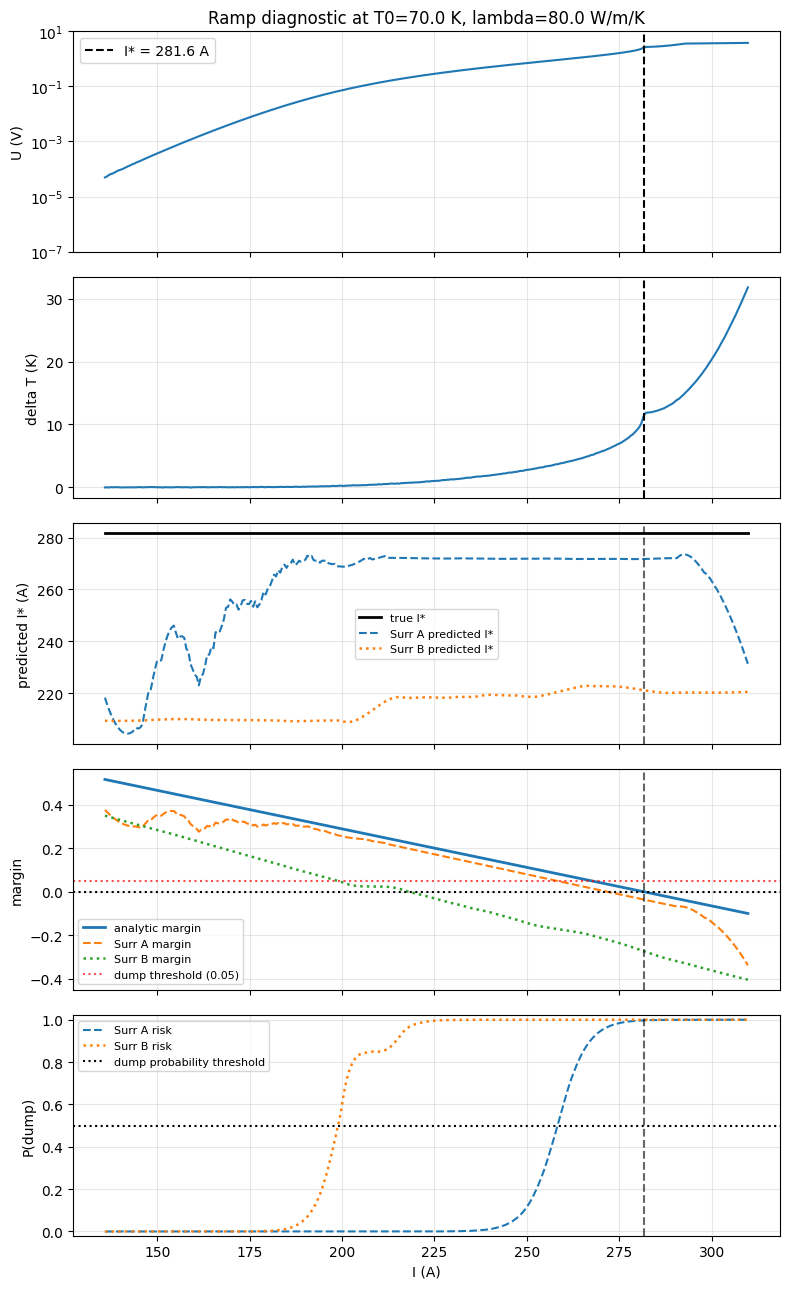

Dump-current error vs analytic across 29 ramps:
  Surr A (eta)    median: -2.80 A   95% band: [-30.79, +20.35]   worst |err|: 36.19 A
  Surr B (raw)    median: -2.08 A   95% band: [-93.07, +37.54]   worst |err|: 100.94 A


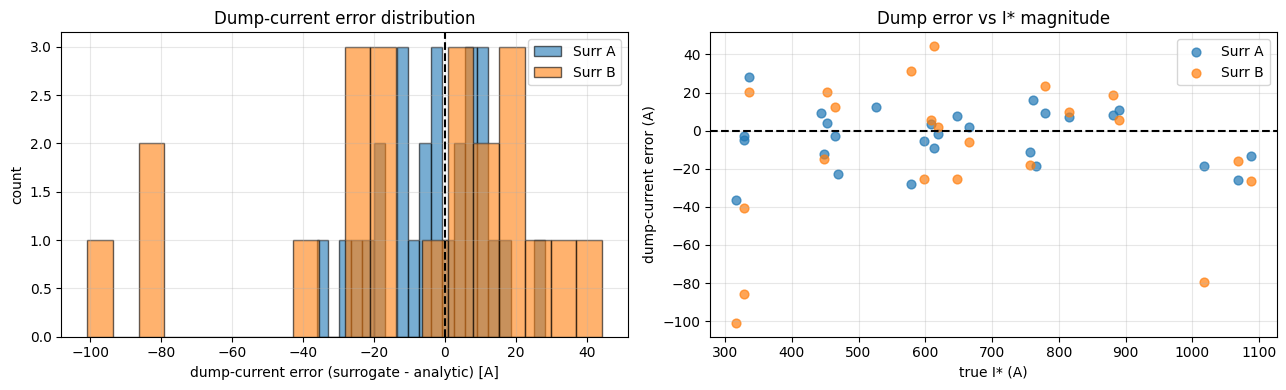

In [128]:
# ============================================================
# Diagnostic: ramp behavior + dump-current accuracy
# FIXED VERSION:
#   surrogate predicts I*
#   margin = (I*_pred - I) / I*_pred
#   risk = sigmoid of margin relative to dump threshold
# ============================================================

from scipy.signal import savgol_filter

PROTECTION_MARGIN = 0.05
RISK_SCALE = 0.015

V_NOISE_FLOOR_V = 1e-6
T_NOISE_FLOOR_K = 0.02

def margin_to_risk(margin, threshold=PROTECTION_MARGIN, scale=RISK_SCALE):
    return 1.0 / (1.0 + np.exp((margin - threshold) / scale))


def smooth_series(y, window=31, poly=2):
    y = np.asarray(y, float)

    if len(y) < window:
        return y

    if window % 2 == 0:
        window += 1

    window = min(window, len(y) if len(y) % 2 == 1 else len(y) - 1)

    if window <= poly + 2:
        return y

    return savgol_filter(y, window_length=window, polyorder=poly)


def simulate_ramp(
    T0,
    n_fixed=N_FIXED,
    lam_const=None,
    n_steps=400,
    I_frac_max=1.10,
    seed=22
):
    rng = np.random.default_rng(seed)

    Istar, Tstar = solve_runaway(
        T0,
        n_fixed,
        mode="stab",
        lam_override=lam_const
    )

    if not np.isfinite(Istar):
        return None

    I_vec = np.linspace(
        0.30 * Istar,
        I_frac_max * Istar,
        n_steps
    )

    rows = []

    for I in I_vec:

        if I < Istar:

            Tsurf = stable_surface_T(
                I,
                T0,
                n_fixed,
                mode="stab",
                lam_override=lam_const
            )

            if not np.isfinite(Tsurf):
                continue

        else:
            frac = min(
                (I / Istar - 1.0) / (I_frac_max - 1.0),
                1.0
            )

            Tsurf = Tstar + frac**2 * 20.0

        V_clean = voltage_stab(
            I,
            min(Tsurf, Tc - 1e-4),
            n_fixed
        )

        V_meas = max(
            V_clean + rng.normal(0, V_NOISE_FLOOR_V),
            V_NOISE_FLOOR_V * 0.1
        )

        T_meas = Tsurf + rng.normal(0, T_NOISE_FLOOR_K)

        dT = max(
            T_meas - T0,
            DT_FLOOR
        )

        eta_live = I * V_meas / dT

        rows.append({
            "I_A": I,
            "voltage_V": V_meas,
            "T_surface_K": T_meas,
            "T0_K": T0,
            "eta_live": eta_live,
            "Istar_true": Istar,
            "Tstar_true": Tstar,
            "true_margin": (Istar - I) / Istar,
        })

    return pd.DataFrame(rows)


def predict_Istar_and_margin(
    surr,
    ramp,
    features,
    smooth=True,
    smooth_window=31
):
    X = ramp[features].values

    Istar_pred = np.asarray(
        surr.predict(X),
        dtype=float
    )

    if smooth:
        Istar_pred = smooth_series(
            Istar_pred,
            window=smooth_window,
            poly=2
        )

    Istar_pred = np.maximum(
        Istar_pred,
        1e-9
    )

    margin = (
        Istar_pred
        -
        ramp["I_A"].values
    ) / Istar_pred

    return Istar_pred, margin


def find_dump_current(
    I_vec,
    margin_vec,
    threshold=PROTECTION_MARGIN
):
    below = margin_vec < threshold

    if not np.any(below):
        return np.nan

    return I_vec[np.argmax(below)]


# ============================================================
# Plot 1: ramp diagnostic at fixed T0
# ============================================================

T0_demo = 70.0
lam_demo = 80.0

ramp = simulate_ramp(
    T0_demo,
    lam_const=lam_demo,
    n_steps=400,
    seed=22
)

if ramp is None or ramp.empty:
    raise RuntimeError("No valid ramp generated.")

A_features = ["T0_K", "eta_live"]
B_features = ["T0_K", "I_A", "voltage_V", "T_surface_K"]

Istar_A, marg_A = predict_Istar_and_margin(
    surr_A_gbrt,
    ramp,
    A_features,
    smooth=True
)

Istar_B, marg_B = predict_Istar_and_margin(
    surr_B_gbrt,
    ramp,
    B_features,
    smooth=True
)

Istar_true = ramp["Istar_true"].iloc[0]

risk_A = margin_to_risk(marg_A)
risk_B = margin_to_risk(marg_B)

fig, axes = plt.subplots(
    5,
    1,
    figsize=(8, 13),
    sharex=True
)

# Voltage
axes[0].plot(
    ramp.I_A,
    ramp.voltage_V,
    lw=1.5
)

axes[0].axvline(
    Istar_true,
    ls="--",
    color="k",
    label=f"I* = {Istar_true:.1f} A"
)

axes[0].set_yscale("log")
axes[0].set_ylim(1e-7, 1e1)
axes[0].set_ylabel("U (V)")
axes[0].set_title(
    f"Ramp diagnostic at T0={T0_demo} K, lambda={lam_demo} W/m/K"
)
axes[0].legend()
axes[0].grid(alpha=0.3, which="both")

# Temperature
axes[1].plot(
    ramp.I_A,
    ramp.T_surface_K - ramp.T0_K,
    lw=1.5
)

axes[1].axvline(
    Istar_true,
    ls="--",
    color="k"
)

axes[1].set_ylabel("delta T (K)")
axes[1].grid(alpha=0.3)

# Predicted I*
axes[2].plot(
    ramp.I_A,
    np.full(len(ramp), Istar_true),
    "k-",
    lw=2,
    label="true I*"
)

axes[2].plot(
    ramp.I_A,
    Istar_A,
    "--",
    lw=1.5,
    label="Surr A predicted I*"
)

axes[2].plot(
    ramp.I_A,
    Istar_B,
    ":",
    lw=1.8,
    label="Surr B predicted I*"
)

axes[2].axvline(
    Istar_true,
    ls="--",
    color="k",
    alpha=0.6
)

axes[2].set_ylabel("predicted I* (A)")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)

# Margin
axes[3].plot(
    ramp.I_A,
    ramp.true_margin,
    lw=2,
    label="analytic margin"
)

axes[3].plot(
    ramp.I_A,
    marg_A,
    "--",
    lw=1.5,
    label="Surr A margin"
)

axes[3].plot(
    ramp.I_A,
    marg_B,
    ":",
    lw=1.8,
    label="Surr B margin"
)

axes[3].axhline(
    0,
    ls=":",
    color="k"
)

axes[3].axhline(
    PROTECTION_MARGIN,
    ls=":",
    color="r",
    alpha=0.7,
    label=f"dump threshold ({PROTECTION_MARGIN})"
)

axes[3].axvline(
    Istar_true,
    ls="--",
    color="k",
    alpha=0.6
)

axes[3].set_ylabel("margin")
axes[3].legend(fontsize=8)
axes[3].grid(alpha=0.3)

# Risk
axes[4].plot(
    ramp.I_A,
    risk_A,
    "--",
    lw=1.5,
    label="Surr A risk"
)

axes[4].plot(
    ramp.I_A,
    risk_B,
    ":",
    lw=1.8,
    label="Surr B risk"
)

axes[4].axhline(
    0.5,
    ls=":",
    color="k",
    label="dump probability threshold"
)

axes[4].axvline(
    Istar_true,
    ls="--",
    color="k",
    alpha=0.6
)

axes[4].set_xlabel("I (A)")
axes[4].set_ylabel("P(dump)")
axes[4].set_ylim(-0.02, 1.02)
axes[4].legend(fontsize=8)
axes[4].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# Plot 2: dump-current accuracy across many ramps
# ============================================================

N_RAMPS = 30
rng = np.random.default_rng(0)

T0s = rng.uniform(15.0, 70.0, N_RAMPS)
lams = rng.uniform(LAM_MIN, LAM_MAX, N_RAMPS)

records = []

for T0, lam in zip(T0s, lams):

    ramp_i = simulate_ramp(
        float(T0),
        lam_const=float(lam),
        n_steps=250,
        I_frac_max=1.05
    )

    if ramp_i is None or len(ramp_i) < 50:
        continue

    Is_true = ramp_i.Istar_true.iloc[0]

    _, m_A = predict_Istar_and_margin(
        surr_A_gbrt,
        ramp_i,
        A_features,
        smooth=True
    )

    _, m_B = predict_Istar_and_margin(
        surr_B_gbrt,
        ramp_i,
        B_features,
        smooth=True
    )

    I_dump_true = find_dump_current(
        ramp_i.I_A.values,
        ramp_i.true_margin.values
    )

    I_dump_A = find_dump_current(
        ramp_i.I_A.values,
        m_A
    )

    I_dump_B = find_dump_current(
        ramp_i.I_A.values,
        m_B
    )

    records.append({
        "T0": T0,
        "lam": lam,
        "Istar_true": Is_true,
        "I_dump_true": I_dump_true,
        "I_dump_A": I_dump_A,
        "I_dump_B": I_dump_B
    })

R = pd.DataFrame(records)

R["err_A"] = R["I_dump_A"] - R["I_dump_true"]
R["err_B"] = R["I_dump_B"] - R["I_dump_true"]

print(f"Dump-current error vs analytic across {len(R)} ramps:")

for col, name in [
    ("err_A", "Surr A (eta)"),
    ("err_B", "Surr B (raw)")
]:

    print(
        f"  {name:14s}  "
        f"median: {R[col].median():+.2f} A   "
        f"95% band: [{R[col].quantile(0.025):+.2f}, "
        f"{R[col].quantile(0.975):+.2f}]   "
        f"worst |err|: {R[col].abs().max():.2f} A"
    )

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4)
)

axes[0].hist(
    R["err_A"].dropna(),
    bins=20,
    alpha=0.6,
    label="Surr A",
    edgecolor="k"
)

axes[0].hist(
    R["err_B"].dropna(),
    bins=20,
    alpha=0.6,
    label="Surr B",
    edgecolor="k"
)

axes[0].axvline(
    0,
    ls="--",
    color="k"
)

axes[0].set_xlabel(
    "dump-current error (surrogate - analytic) [A]"
)

axes[0].set_ylabel("count")
axes[0].set_title("Dump-current error distribution")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(
    R["Istar_true"],
    R["err_A"],
    s=40,
    alpha=0.7,
    label="Surr A"
)

axes[1].scatter(
    R["Istar_true"],
    R["err_B"],
    s=40,
    alpha=0.7,
    label="Surr B"
)

axes[1].axhline(
    0,
    ls="--",
    color="k"
)

axes[1].set_xlabel("true I* (A)")
axes[1].set_ylabel("dump-current error (A)")
axes[1].set_title("Dump error vs I* magnitude")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [129]:
# ============================================================
# Slide 8: surface reproduction + spatial error maps
# Shows where each surrogate agrees/disagrees with the solver
# across the (T0, lambda) operating envelope.
# ============================================================
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# -------- Build a dense (T0, lambda) grid for the analytic surface --------
T0_grid  = np.linspace(5.0, 75.0, 60)
lam_grid = np.linspace(LAM_MIN, LAM_MAX, 50)
TT, LL = np.meshgrid(T0_grid, lam_grid)

print("Computing analytic I* surface on grid...")
Istar_analytic = np.full(TT.shape, np.nan)
Tstar_analytic = np.full(TT.shape, np.nan)
for i in range(TT.shape[0]):
    for j in range(TT.shape[1]):
        Is, Ts = solve_runaway(float(TT[i, j]), n=N_FIXED, mode='stab',
                               lam_override=float(LL[i, j]))
        if np.isfinite(Is):
            Istar_analytic[i, j] = Is
            Tstar_analytic[i, j] = Ts

# Corresponding eta grid for Surrogate A
eta_grid = LL * GEOM

# -------- Surrogate A prediction on the grid --------
X_A_grid = np.column_stack([TT.ravel(), eta_grid.ravel()])
Istar_A_grid = surr_A_mlp.predict(X_A_grid).reshape(TT.shape)
Istar_A_grid = np.where(np.isfinite(Istar_analytic), Istar_A_grid, np.nan)

# -------- Surrogate B prediction on the grid --------
# B needs raw signals (T0, I, U, T_surface). We need to manufacture a sensible
# (I, U, T_surface) for each grid point. Use the analytic stable equilibrium
# at I = 0.95 * Istar_analytic for that grid point - a representative
# "near-boundary" operating condition, which is where protection matters.
print("Computing Surrogate B grid (requires per-point physics for raw signals)...")
I_grid_op       = np.full(TT.shape, np.nan)
V_grid_op       = np.full(TT.shape, np.nan)
Tsurf_grid_op   = np.full(TT.shape, np.nan)

for i in range(TT.shape[0]):
    for j in range(TT.shape[1]):
        if not np.isfinite(Istar_analytic[i, j]):
            continue
        I_op = 0.95 * Istar_analytic[i, j]
        Tsurf = stable_surface_T(I_op, float(TT[i, j]), N_FIXED, mode='stab',
                                 lam_override=float(LL[i, j]))
        if not np.isfinite(Tsurf):
            continue
        V_op = voltage_stab(I_op, min(Tsurf, Tc - 1e-4), N_FIXED)
        I_grid_op[i, j]     = I_op
        V_grid_op[i, j]     = V_op
        Tsurf_grid_op[i, j] = Tsurf

X_B_grid = np.column_stack([
    TT.ravel(),
    I_grid_op.ravel(),
    V_grid_op.ravel(),
    Tsurf_grid_op.ravel(),
])
# Mask invalid rows before predicting
valid_B = np.isfinite(X_B_grid).all(axis=1)
Istar_B_grid = np.full(TT.size, np.nan)
Istar_B_grid[valid_B] = surr_B_mlp.predict(X_B_grid[valid_B])
Istar_B_grid = Istar_B_grid.reshape(TT.shape)
Istar_B_grid = np.where(np.isfinite(Istar_analytic), Istar_B_grid, np.nan)

# -------- Relative error surfaces --------
rel_err_A = (Istar_A_grid - Istar_analytic) / Istar_analytic * 100
rel_err_B = (Istar_B_grid - Istar_analytic) / Istar_analytic * 100

# Normalize by Ic(T0) for paper-style Fig. 3a display
Ic_at_T0   = np.array([float(Ic(t)) for t in T0_grid])
ratio_analytic = Istar_analytic / Ic_at_T0[None, :]
ratio_A        = Istar_A_grid   / Ic_at_T0[None, :]
ratio_B        = Istar_B_grid   / Ic_at_T0[None, :]

Computing analytic I* surface on grid...
Computing Surrogate B grid (requires per-point physics for raw signals)...


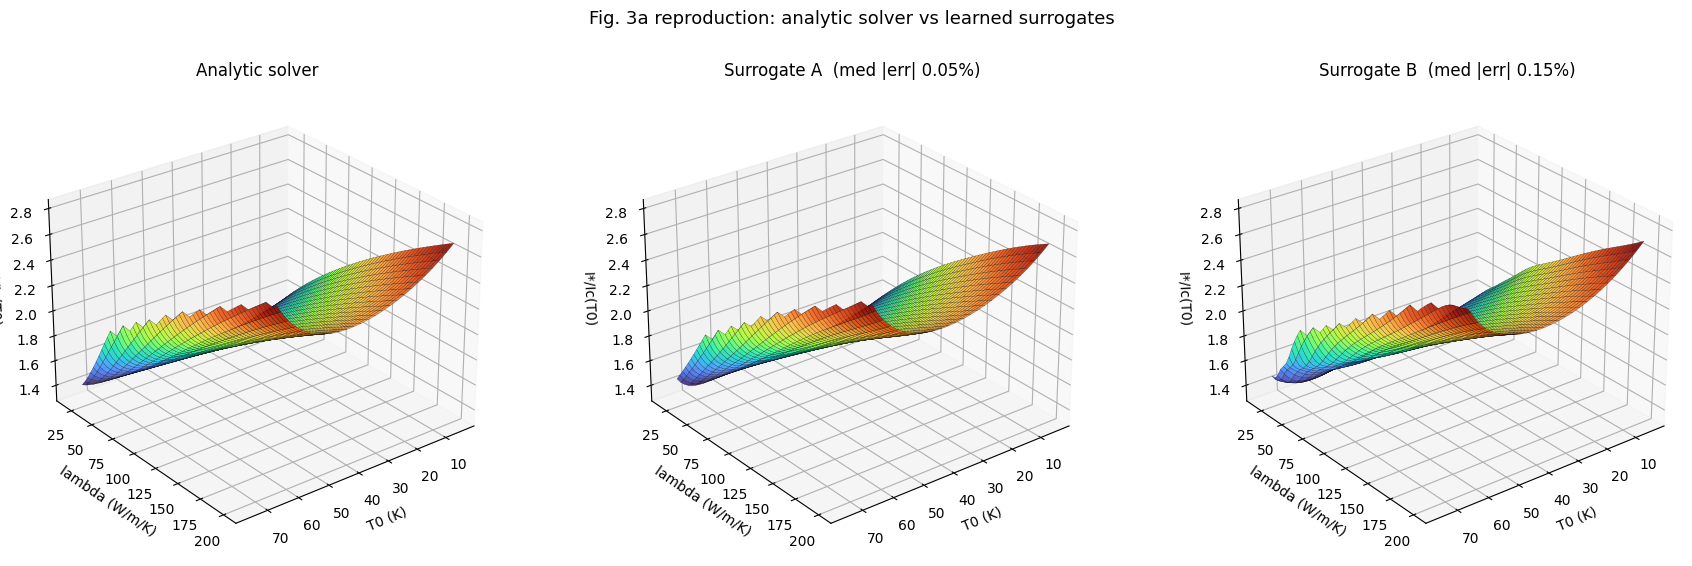

In [131]:
 # ============================================================
# Plot 1: three 3D surfaces side-by-side  (Fig. 3a-style)
# ============================================================
fig = plt.figure(figsize=(18, 5.5))

zmax = np.nanmax(ratio_analytic) * 1.05
zmin = np.nanmin(ratio_analytic) * 0.95

panels = [
    ("Analytic solver", ratio_analytic),
    (f"Surrogate A  (med |err| {np.nanmedian(np.abs(rel_err_A)):.2f}%)", ratio_A),
    (f"Surrogate B  (med |err| {np.nanmedian(np.abs(rel_err_B)):.2f}%)", ratio_B),
]
for k, (title, Z) in enumerate(panels):
    ax = fig.add_subplot(1, 3, k + 1, projection='3d')
    ax.plot_surface(TT, LL, Z, cmap='turbo',
                    edgecolor='k', linewidth=0.15, alpha=0.9)
    ax.set_xlabel("T0 (K)"); ax.set_ylabel("lambda (W/m/K)")
    ax.set_zlabel("I*/Ic(T0)")
    ax.set_zlim(zmin, zmax)
    ax.set_title(title)
    ax.view_init(elev=27, azim=-128)
    ax.invert_xaxis(); ax.invert_yaxis()

plt.suptitle("Fig. 3a reproduction: analytic solver vs learned surrogates", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()


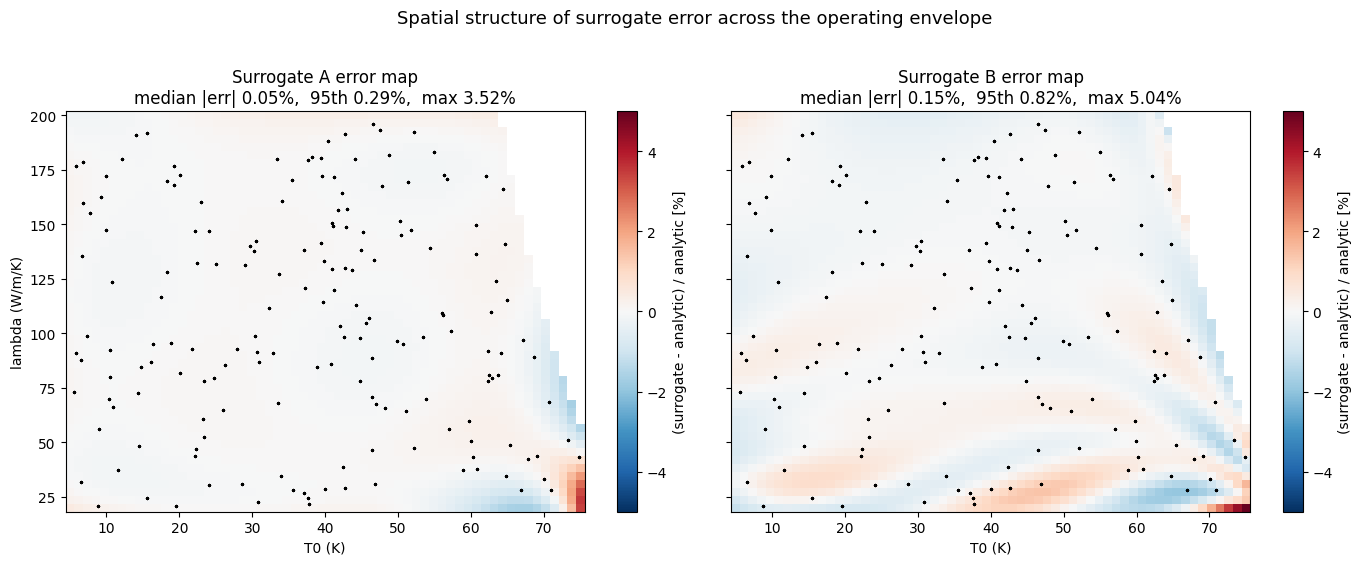

In [132]:
# ============================================================
# Plot 2: 2D error maps  -  spatial structure of surrogate disagreement
# ============================================================
err_scale = 5.0   # symmetric +/- 5% color scale

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

for ax, err, label in [
    (axes[0], rel_err_A, "Surrogate A"),
    (axes[1], rel_err_B, "Surrogate B"),
]:
    im = ax.pcolormesh(TT, LL, err, cmap='RdBu_r',
                       vmin=-err_scale, vmax=err_scale, shading='auto')
    ax.set_xlabel("T0 (K)")
    if ax is axes[0]:
        ax.set_ylabel("lambda (W/m/K)")
    ax.set_title(f"{label} error map\n"
                 f"median |err| {np.nanmedian(np.abs(err)):.2f}%,  "
                 f"95th {np.nanpercentile(np.abs(err), 95):.2f}%,  "
                 f"max {np.nanmax(np.abs(err)):.2f}%")
    plt.colorbar(im, ax=ax, label="(surrogate - analytic) / analytic [%]")

    # Overlay training extent so the audience sees where data was
    ax.scatter(df_A_train['T0_K'], df_A_train['lambda_W_per_mK'],
               s=1.5, alpha=0.15, color='black')

plt.suptitle("Spatial structure of surrogate error across the operating envelope",
             y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

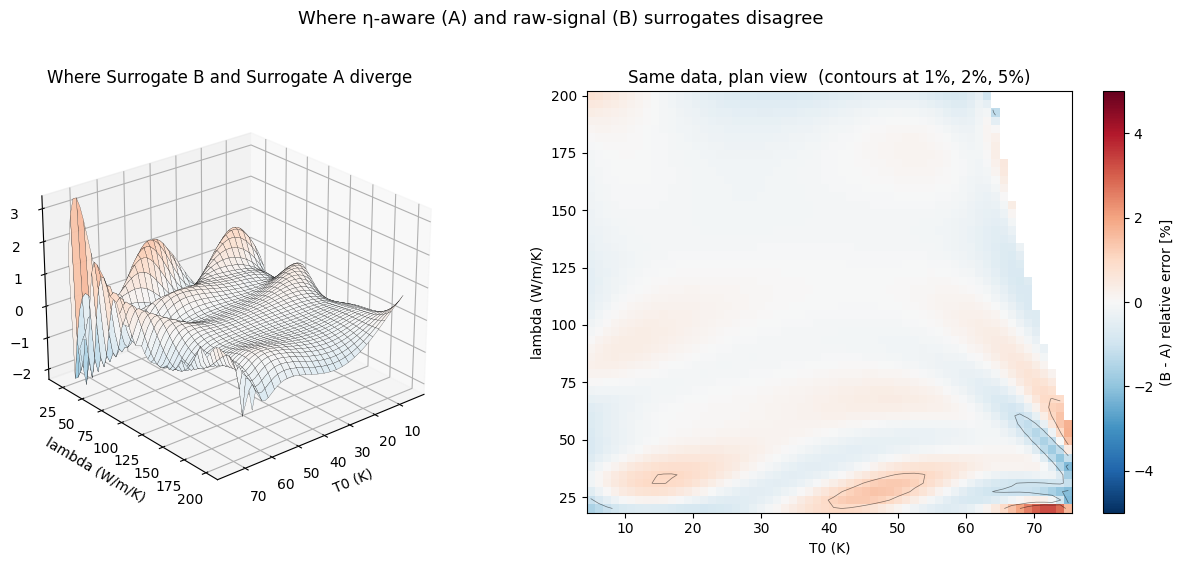

In [133]:
# ============================================================
# Plot 3: B-minus-A relative-error surface
# Where A and B differ tells you where the η-aware framing and the
# raw-signal framing make different bets. Flat = identical; bumps =
# regions of operating envelope where the two see different physics.
# ============================================================
diff_B_minus_A = rel_err_B - rel_err_A

fig = plt.figure(figsize=(13, 5.5))

ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot_surface(TT, LL, diff_B_minus_A, cmap='RdBu_r',
                vmin=-5, vmax=5,
                edgecolor='k', linewidth=0.15, alpha=0.95)
ax.set_xlabel("T0 (K)"); ax.set_ylabel("lambda (W/m/K)")
ax.set_zlabel("(B - A) relative error [%]")
ax.set_title("Where Surrogate B and Surrogate A diverge")
ax.view_init(elev=25, azim=-130)
ax.invert_xaxis(); ax.invert_yaxis()

ax = fig.add_subplot(1, 2, 2)
im = ax.pcolormesh(TT, LL, diff_B_minus_A, cmap='RdBu_r',
                   vmin=-5, vmax=5, shading='auto')
plt.colorbar(im, ax=ax, label="(B - A) relative error [%]")
ax.contour(TT, LL, np.abs(diff_B_minus_A), levels=[1, 2, 5],
           colors='k', linewidths=0.5, alpha=0.5)
ax.set_xlabel("T0 (K)"); ax.set_ylabel("lambda (W/m/K)")
ax.set_title("Same data, plan view  (contours at 1%, 2%, 5%)")

plt.suptitle("Where η-aware (A) and raw-signal (B) surrogates disagree",
             y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

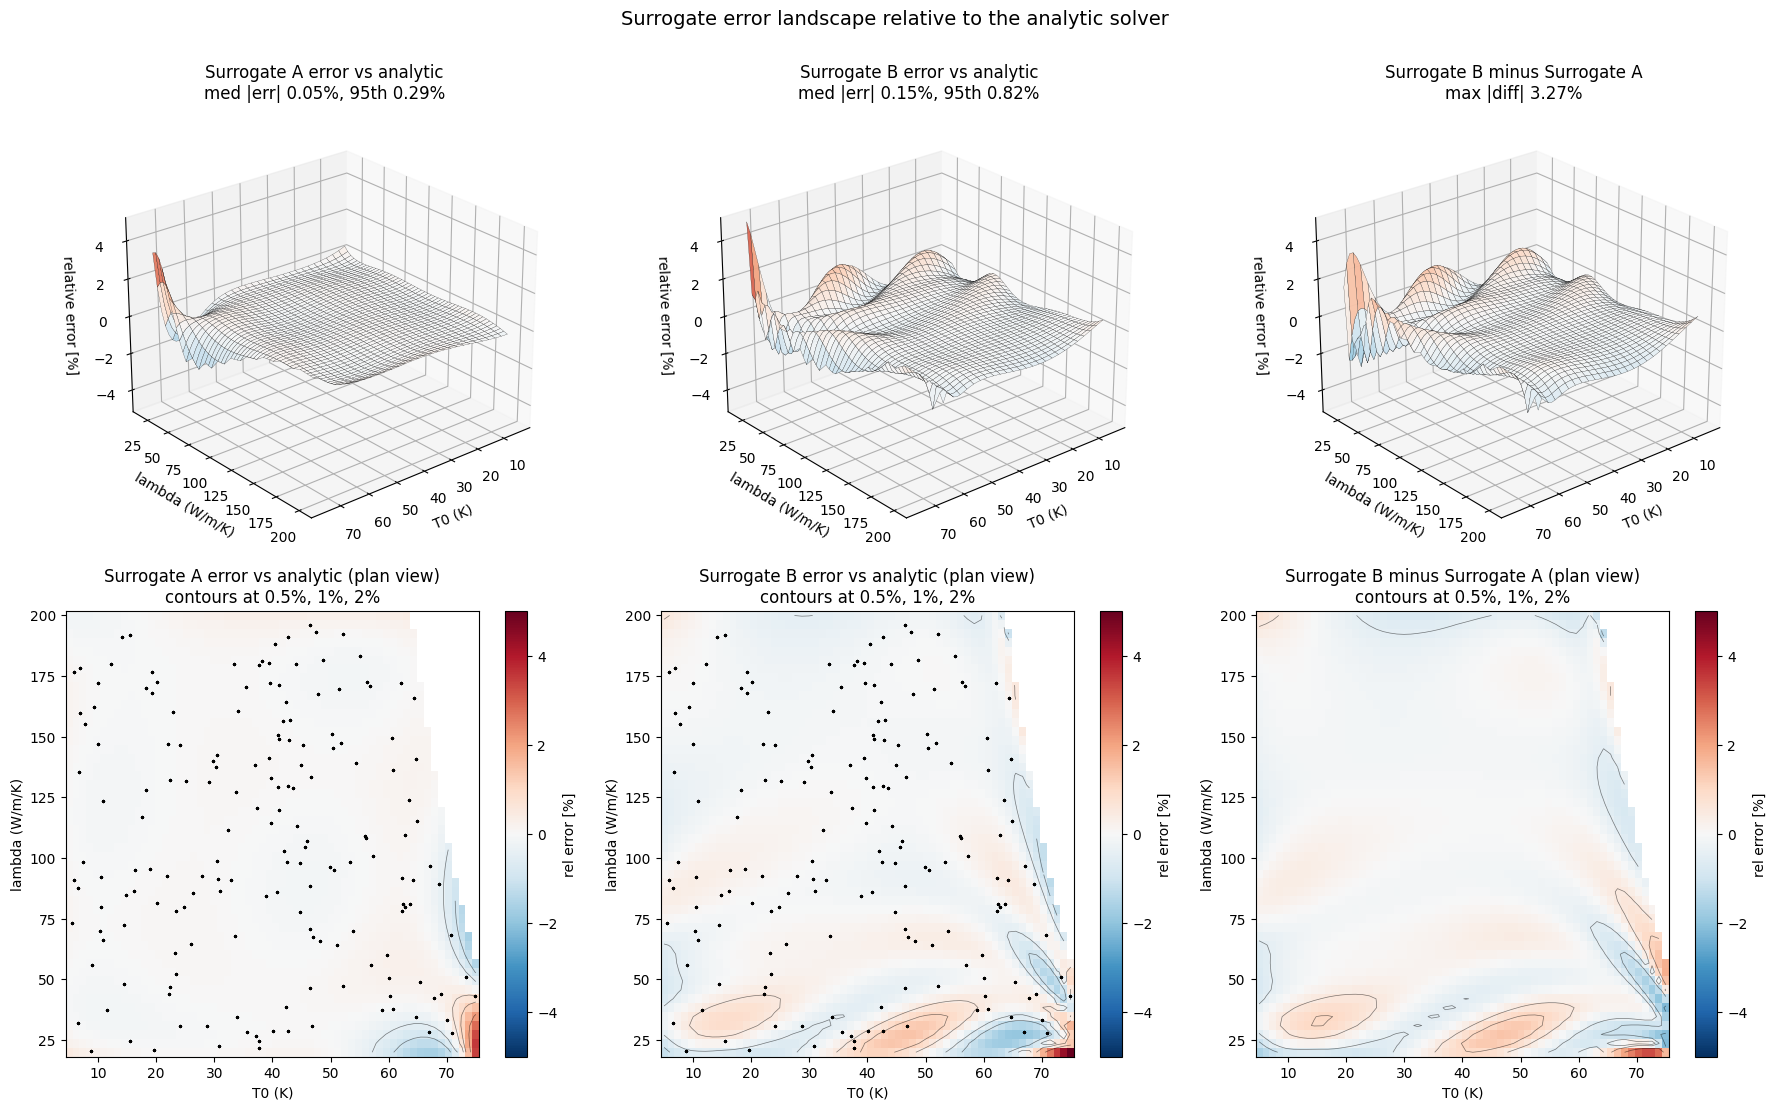

In [134]:
# ============================================================
# Plot 3 (revised): three error surfaces relative to the analytic solver
#   Left:   Surrogate A error vs analytic
#   Middle: Surrogate B error vs analytic
#   Right:  B - A (where the two surrogates differ from each other)
# All on the same +/-5% color scale so panels are comparable.
# ============================================================
err_scale = 5.0

# A and B errors relative to analytic ground truth
# (already computed above as rel_err_A, rel_err_B)
diff_B_minus_A = rel_err_B - rel_err_A

# -------- 3D row --------
fig = plt.figure(figsize=(18, 11))

surfaces = [
    (rel_err_A,         "Surrogate A error vs analytic",
     f"med |err| {np.nanmedian(np.abs(rel_err_A)):.2f}%, "
     f"95th {np.nanpercentile(np.abs(rel_err_A), 95):.2f}%"),
    (rel_err_B,         "Surrogate B error vs analytic",
     f"med |err| {np.nanmedian(np.abs(rel_err_B)):.2f}%, "
     f"95th {np.nanpercentile(np.abs(rel_err_B), 95):.2f}%"),
    (diff_B_minus_A,    "Surrogate B minus Surrogate A",
     f"max |diff| {np.nanmax(np.abs(diff_B_minus_A)):.2f}%"),
]

for k, (Z, title, sub) in enumerate(surfaces):
    ax = fig.add_subplot(2, 3, k + 1, projection='3d')
    ax.plot_surface(TT, LL, Z, cmap='RdBu_r',
                    vmin=-err_scale, vmax=err_scale,
                    edgecolor='k', linewidth=0.15, alpha=0.95)
    ax.set_xlabel("T0 (K)"); ax.set_ylabel("lambda (W/m/K)")
    ax.set_zlabel("relative error [%]")
    ax.set_zlim(-err_scale, err_scale)
    ax.set_title(f"{title}\n{sub}")
    ax.view_init(elev=25, azim=-130)
    ax.invert_xaxis(); ax.invert_yaxis()

# -------- 2D row (plan view) --------
for k, (Z, title, sub) in enumerate(surfaces):
    ax = fig.add_subplot(2, 3, k + 4)
    im = ax.pcolormesh(TT, LL, Z, cmap='RdBu_r',
                       vmin=-err_scale, vmax=err_scale, shading='auto')
    plt.colorbar(im, ax=ax, label="rel error [%]")

    # contours at meaningful thresholds
    ax.contour(TT, LL, np.abs(Z), levels=[0.5, 1, 2],
               colors='k', linewidths=0.5, alpha=0.5)

    # training-data extent for context (only on the first two)
    if k < 2:
        ax.scatter(df_A_train['T0_K'], df_A_train['lambda_W_per_mK'],
                   s=1.5, alpha=0.12, color='black')

    ax.set_xlabel("T0 (K)"); ax.set_ylabel("lambda (W/m/K)")
    ax.set_title(f"{title} (plan view)\ncontours at 0.5%, 1%, 2%")

plt.suptitle("Surrogate error landscape relative to the analytic solver",
             y=1.005, fontsize=14)
plt.tight_layout(); plt.show()

In [105]:
## NEXT MODEL PARADIGM (noise, incomplete measurements) ###

In [ ]:
# ============================================================
# Slide: Fig. 7b-style validation
# Ramp current at fixed T0 (and fixed eta).  Show the voltage and
# T_surface divergence as I crosses I*.  Compare three methods' predictions
# of the runaway current.
# ============================================================

# Pick a representative operating point - near LN2-like base T, realistic eta
T0_demo  = 70.0     # K
lam_demo = 80.0     # W/m/K, representative cooling
eta_demo = lam_demo * GEOM

# ----- Analytic ground truth -----
Istar_true, Tstar_true = solve_runaway(T0_demo, n=N_FIXED, mode='stab',
                                        lam_override=lam_demo)
print(f"Analytic ground truth at T0={T0_demo} K, lambda={lam_demo} W/m/K:")
print(f"  I*    = {Istar_true:.2f} A")
print(f"  T*    = {Tstar_true:.2f} K")

# ----- Build the ramp: I from 0.3*I* up to just past 1.05*I* -----
# Below I*: use the stable surface T from the heat balance
# Above I*: there's no stable equilibrium; integrate a stabilized adiabatic
# trajectory just for visualization of the divergence (paper does this
# properly via the quench integral in Fig. 4).

I_below = np.linspace(0.30 * Istar_true, 0.999 * Istar_true, 200)
I_above = np.linspace(1.001 * Istar_true, 1.05 * Istar_true, 50)

# Below: solve the stable equilibrium at each I
T_below = np.array([
    stable_surface_T(I, T0_demo, N_FIXED, mode='stab',
                     lam_override=lam_demo)
    for I in I_below
])

# Above: stabilized Euler step with temperature cap
T_CAP = 200.0    # K - cap so voltage doesn't blow up
T_above_list = []
T_running = Tstar_true
for I in I_above:
    T_eval = min(T_running, Tc - 1e-3)
    P_in   = I * voltage_stab(I, T_eval, N_FIXED)
    P_out  = eta_demo * (T_running - T0_demo)
    # bounded fractional step
    dT     = 0.5 * (P_in - P_out) / max(P_in + P_out, 1.0)
    T_running = min(T_running + dT, T_CAP)
    T_above_list.append(T_running)
T_above = np.array(T_above_list)

I_ramp = np.concatenate([I_below, I_above])
T_ramp = np.concatenate([T_below, T_above])

# Voltage along the ramp, capped on the high end for plotting
V_ramp = np.array([
    voltage_stab(I, min(T, Tc - 1e-3), N_FIXED)
    for I, T in zip(I_ramp, T_ramp)
])
V_CAP = 10.0    # V - well past any realistic measurement
V_ramp = np.clip(V_ramp, 1e-10, V_CAP)

# ----- Each method predicts I* given the operating point -----
# Analytic
Istar_analytic = Istar_true

# Surrogate A: (T0, eta) -> I*
Istar_A = float(surr_A_mlp.predict(np.array([[T0_demo, eta_demo]]))[0])

# Surrogate B needs raw signals - use a representative stable point at
# I = 0.95 * I* (what protection would actually be querying as it approaches)
I_query  = 0.95 * Istar_true
T_query  = stable_surface_T(I_query, T0_demo, N_FIXED, mode='stab',
                            lam_override=lam_demo)
V_query  = voltage_stab(I_query, min(T_query, Tc - 1e-4), N_FIXED)
Istar_B  = float(surr_B_mlp.predict(np.array([[T0_demo, I_query, V_query, T_query]]))[0])

print()
print(f"Runaway-current predictions at this operating point:")
print(f"  Analytic    : I* = {Istar_analytic:.2f} A   (ground truth)")
print(f"  Surrogate A : I* = {Istar_A:.2f} A   (Δ {Istar_A - Istar_analytic:+.2f} A, "
      f"{(Istar_A - Istar_analytic)/Istar_analytic*100:+.2f}%)")
print(f"  Surrogate B : I* = {Istar_B:.2f} A   (Δ {Istar_B - Istar_analytic:+.2f} A, "
      f"{(Istar_B - Istar_analytic)/Istar_analytic*100:+.2f}%)")


# ============================================================
# Plot: Fig. 7b-style
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

c_analytic = '#dc2626'
c_A        = '#3a7bd5'
c_B        = '#f59e0b'

# ----- Top: voltage -----
ax = axes[0]
ax.semilogy(I_ramp, V_ramp, lw=2.5, color='#374151', label='conductor voltage U(I)')
ax.axvline(Istar_analytic, color=c_analytic, lw=2, linestyle='-',
           label=f'analytic I* = {Istar_analytic:.1f} A', alpha=0.85)
ax.axvline(Istar_A, color=c_A, lw=2, linestyle='--',
           label=f'Surrogate A I* = {Istar_A:.1f} A', alpha=0.85)
ax.axvline(Istar_B, color=c_B, lw=2, linestyle=':',
           label=f'Surrogate B I* = {Istar_B:.1f} A', alpha=0.85)
ax.axvspan(Istar_true, Istar_true * 1.05, alpha=0.10, color='red',
           label='runaway region')

ax.set_ylabel("voltage U (V)", fontsize=12)
ax.set_title(f"Fig. 7b-style validation at T0 = {T0_demo} K, η = {eta_demo:.0f} W/K",
             fontsize=13, fontweight='bold')
ax.legend(loc='upper left', fontsize=10, framealpha=0.95)
ax.grid(alpha=0.3, which='both')
ax.set_ylim(1e-7, V_CAP * 1.5)

# ----- Bottom: T_surface -----
ax = axes[1]
ax.plot(I_ramp, T_ramp, lw=2.5, color='#374151', label='surface temperature T(I)')
ax.axvline(Istar_analytic, color=c_analytic, lw=2, linestyle='-', alpha=0.85)
ax.axvline(Istar_A, color=c_A, lw=2, linestyle='--', alpha=0.85)
ax.axvline(Istar_B, color=c_B, lw=2, linestyle=':', alpha=0.85)
ax.axhline(Tstar_true, color='#9ca3af', lw=1, linestyle=':',
           label=f'T* = {Tstar_true:.1f} K')
ax.axvspan(Istar_true, Istar_true * 1.05, alpha=0.10, color='red')

ax.set_xlabel("current I (A)", fontsize=12)
ax.set_ylabel("surface T (K)", fontsize=12)
ax.legend(loc='upper left', fontsize=10, framealpha=0.95)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('slide_fig7b_validation.png', dpi=200, bbox_inches='tight',
            facecolor='white')
plt.show()

In [ ]:
## SPATIAL VARIATION ##

In [ ]:
## time dependent and history dependet in the ramp ##


I_c non-linear 
state ad heavoor?